# 06 — The calibration target: can the boreholes tell f_ref and f_ins apart? (Step 5a)

> **In short.** A calibration needs a *target*: the way model and boreholes are compared. Today's
> target (T1) compares one mean per borehole entity, so it sees only the **level** of the
> profiles. With it, f_ins cannot be calibrated: a fit is expected to leave it two thirds of its
> prior uncertainty (spread left 0.66), and more refreezing can still be undone by less insulation
> (correlation 0.88). Comparing every 1 m depth bin (T2), or every depth bin and month (T3), also
> uses the **shape** with depth and the **season**; both are expected to tell the two apart
> (correlation 0.58 and 0.34, f_ins spread left 0.19 and 0.12, by both methods).
>
> **But the level and the shape ask for different parameters** (5.4 and 6.9 standard deviations
> apart). The shape alone wants about half the refreezing, at which the high firn of Monte Rosa and
> Col du Dôme would be about 2 °C too cold; a whole T2 fit lands in between, with that firn
> 0.6–0.85 °C too cold (T3: 1.0–1.3 °C).
>
> **What the rule fixed beforehand says depends on the error model.** With the August error model,
> as planned, **T2 is outcome 2**: only "consistent" fails, and the held-out cost is inside the
> margin by every method (+0.07 °C expected; 90 % interval −0.12 to +0.25 °C). **T3 is not
> resolved:** +0.08 °C by the stand-ins, +0.23 °C by the real runs, and no real run lies near its
> optimum. With an error model
> fitted to the misfits, which describes them better, **both are outcome 3**: the cost is +0.19 to
> +0.37 °C, above your 0.10 °C margin. And with the emulator's own uncertainty varying with the
> parameters, as the pipeline computes it, neither target is told apart on this 29-run design: a
> risk the campaign must handle.
>
> **Recommendation: build T2,** with the August error model and f_adv fixed at 1.0, and document
> the level/shape conflict. The rule selects T2 over T3 because T3 does not come "at no higher RMSE
> cost"; T3 stays an option once runs near its optimum exist. **Your decisions, starting with the
> error model, are in section 7,** with the limits of this analysis (7 glaciers, 32 runs, 6 folds;
> Monte Rosa holds 55 % of the points; the separation numbers are expectations, not calibrations).
>
> *Status (2026-10-09, revised the same day after two independent reviews): analysis only
> (Step 5a); no calibration was run, nothing in `src/` changed, no IDL. Ensemble `alps_s2` (32 runs
> with the snow fix, Step 4) on the 7 Alpine test glaciers, 66 borehole entities; `alps_r7` (before
> the snow fix) for comparison. Data and model rows come from
> `scripts/icetemp_analysis/target_analysis.py` and its cache; the expensive Stage 2–3 results
> (emulator, bootstrap, checks) are read from
> `/scratch_net/vierzack04_fourth/jabeer/tmp_icetemp_trees/step5a/` (section 9 lists them). Section
> 8 compares every number recomputed here with the stage reports, and every number quoted in the
> revised text with the values computed here.*

**Contents.** 1 What a target is · 2 Data and rows · 3 The month-to-month error term · 4 Can the
targets tell the parameters apart? (4.1 the emulator's own uncertainty) · 5 Held-out RMSE,
consistency, honest error model (5.4 the error model decides) · 6 The checks (a)–(g) · 7 The
decision rule and what you decide · 8 Reproduction check · 9 Where the read numbers come from

| word | meaning |
|---|---|
| entity | one glacier's boreholes in one 10 m elevation band, e.g. Grenzgletscher@4455 (66 on the 7 glaciers) |
| point | an entity's readings pooled into a 1 m depth bin; 771 points have a model value in every run |
| row | one number compared with the model; what it is depends on the target |
| run | one forward GloGEM run with one parameter set: 32 in the ensemble; the 29 with f_ref ≥ 0.1 train the smooth stand-ins (below 0.1, Tête Rousse leaves the melting point and the model jumps) |
| prior sd | the spread a parameter has before the fit: f_ref 0.289 (uniform 0–1), f_ins 0.326, f_adv 0.244. All sensitivities and spreads are in these units |
| spread left | uncertainty after the fit ÷ uncertainty before it: 1 = nothing learned, 0.5 = halved |
| correlation | how strongly f_ref and f_ins can still trade off after a fit: ±1 = one fully replaces the other |
| expected | estimated from how fast the misfit rises around one parameter set (its slopes), or from a fit on a stand-in; no calibration was run |
| best point | the parameter set a target's smooth fit prefers |
| 5 best runs | the 5 real runs (of the 29) with the smallest misfit for that target |
| held-out | scored on a glacier system the fit did not see (6 systems: Monte Rosa = 01225 + 01230 counts as one) |
| surface, emulator | two smooth stand-ins for GloGEM between the runs: a polynomial per row (quadratic in section 4, cubic in section 5), and the calibration pipeline's statistical emulator |
| E | a stand-in's own uncertainty: how far its prediction may be off; for the emulator it grows with the distance to the nearest run |
| coverage gate | the calibrator's limit on how far from the nearest run a parameter set may lie |
| error model | Σ, what misfit the comparison expects: measurement error plus model error (section 1) |
| misfit ratio | rᵀ Σ⁻¹ r / n: how large the misfits are compared with what the error model expects (about 1 if it is honest) |

## 1. What a target is, and why it decides what we can calibrate

**The heater and the wall.** Think of the firn as a room that is heated in summer and cooled in
winter.
- **f_ref is the heater:** how much of the meltwater's heat stays in the firn when the water
  refreezes.
- **f_ins is the wall:** how easily heat moves through the firn and, since the snow fix of Step 2,
  through the winter snow on the tongues.

A warmer room can come from a stronger heater or from a better wall. So the *mean* temperature of a
borehole cannot tell the two apart: along a "ridge" of parameter pairs, a stronger heater behind a
leakier wall (more refreezing, more conductive firn) gives the same mean as a weaker heater behind a
better one. Their fingerprints with depth and season differ:

```
 depth     heater (f_ref)                            wall (f_ins)
  0-5 m    summer heat, added from the top           how far the seasonal swing reaches, and how late
  5-20 m   a warm bulge down to where the water      less conductive firn damps the swing within a
           runs out                                  shallower depth, and delays it more
  > 20 m   only the long-term mean                   only the long-term mean
 (on ice bands only the wall acts, through the winter snow)
```

**Three targets.** They differ only in what one compared number averages over:

```
 one borehole entity (glacier, 10 m band)          what each target compares with the model
   depth   Jun-98  Nov-98  Jun-99
     2 m     x       x       x          T1  entity mean      1 number per entity            the level
     5 m     x       x       x          T2  depth            1 number per 1 m depth bin     + the shape with depth
    10 m     x       x       x          T3  depth + month    1 number per bin and month     + the season
    20 m     x
```

- **T1** (today's target) averages each entity's points with their depth weights, as
  `calibrator.py` does: it sees the level only.
- **T2** keeps each point: the level and the shape with depth. A point still mixes months: 403 of
  the 771 points average readings from more than one month, 341 from more than one season.
- **T3** keeps each month of a point apart, so it also sees the seasonal swing. A profile dated
  only to a range of months stays one row, compared with the model averaged over that range
  (section 2 explains why).

**How a target judges a parameter set.** The misfits are weighed by what the error model expects:

  misfit(θ) = rᵀ Σ⁻¹ r,   r = model(θ) − boreholes,   Σ = D + S (+ K + V for T3) (+ E)

| symbol | meaning |
|---|---|
| θ | the parameters (f_ref, f_ins); f_adv = 1.0 unless stated |
| r | the misfits, one per row |
| D | measurement error: glenglat's σ², ×3 for "estimated" profiles |
| S | model error, the August choice: 3.5 °C² × exp(−depth difference ÷ 15 m) between rows of one entity, zero between entities |
| K | T3 only: model error between the months of one point (section 3) |
| V | T3 only: for a reading dated to a range of months, how much the model varies over that range |
| E | the stand-in's own uncertainty (sections 4 and 5) |
| Σ⁻¹ | weighs each misfit by the error expected there, and counts correlated rows about once |

For T1, D + S is pooled to the entity means exactly as `calibrator.py` pools it. The per-glacier
offset δ stays out of the fit (your decision); it appears only as a sensitivity.

**The decision rule, fixed before looking** (plan of 30 September):

| check | passes if |
|---|---|
| told apart | f_ins spread left ≤ 0.5 and correlation ≤ 0.8, by two methods (surface and emulator), at the target's best point and at 4 of its 5 best runs |
| consistent | fitting the level alone and the shape alone gives parameters within 3 standard deviations |
| RMSE | held-out RMSE ≤ T1's + 0.10 °C (your margin) |
| honest error model | misfit ratio between 0.5 and 2 at the best run |

f_adv is freed only if, with three parameters, its spread left is ≤ 0.5 and f_ref and f_ins still
pass "told apart". Outcomes: **(1)** all pass → build T2, or T3 if it cuts the f_ins spread by a
further 20 % at no higher RMSE cost; **(2)** only "consistent" fails → the parameters partly make
up for a model error; build if within your margin, document the conflict, your call; **(3)** "RMSE"
fails → you decide between two parameters at the measured cost and f_ref alone; **(4)** nothing
tells them apart → f_ref alone, and test a parameter with a fingerprint of its own.

*How this notebook reads two points the rule left open:* the f_adv condition is read like "told
apart" (both methods, best point and 4 of 5 runs; section 4 also gives the literal reading), and
the RMSE check, whose method was not fixed, passes only if every method agrees (the stand-ins, the
real runs, and the stand-in's error near the fit; section 7). The error model is the August one
(3.5 °C², 15 m), as the plan set; the fitted one is the sensitivity it asked for (section 5.4).

## 2. Data and rows per target

The module `target_analysis.py` builds every row from DataHandler's own pooling (CentralEurope,
"estimated" and "unassessed" profiles included) and reads the model at each reading's date
through the pipeline's matcher (`runner.match_model_to_obs`). Its cache was rebuilt from scratch
and checked in Stage 1; the checks are rerun here (a fraction of a second).

In [1]:
import json
import pickle
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from IPython.display import display

REPO = Path.cwd().resolve().parent                     # the notebook runs in notebooks/
if not (REPO / 'scripts' / 'icetemp_analysis' / 'target_analysis.py').exists():
    REPO = Path('/home/jabeer/projects/glogemflow_development/glogemflow_icetemp')
sys.path.insert(0, str(REPO / 'scripts' / 'icetemp_analysis'))
import target_analysis as ta                                             # noqa: E402
from icetemp.calibration.thermal_structure import pressure_melting_point  # noqa: E402

STEP5A = ta.SCRATCH / 'step5a'          # Stage 1-3 outputs: cache/, stage2/, identifiability/, heldout/, checks/
pd.set_option('display.precision', 3, 'display.width', 220, 'display.max_columns', 30, 'display.max_colwidth', 80)

GOT = {}                                # numbers computed here; compared with the stage reports in section 8


def got(key, value):
    GOT[key] = float(value)


# figures: one colour per target in every figure, neutral ink otherwise
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#a3a29c', '#e6e5e1'
COL = {'T1': '#2a78d6', 'T2': '#eb6834', 'T3': '#1baf7a'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9.5, 'axes.titlesize': 10, 'axes.titlelocation': 'left',
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'xtick.color': INK2, 'ytick.color': INK2, 'legend.frameon': False, 'lines.linewidth': 2,
                     'lines.solid_capstyle': 'round', 'text.color': INK})

In [2]:
obs = ta.load_obs()
s2, r7 = ta.load_model('alps_s2'), ta.load_model('alps_r7')
common = ta.common_rows([s2, r7], obs)             # points with a model value in all 64 runs, and their T3 rows
SD = ta.prior_sd()                                 # prior sd of f_ref (U[0, 1]), f_ins, f_adv
theta = s2['theta']                                # the 32 runs: f_ref, f_ins, f_adv (identical in alps_r7)
keep = s2['design'].keep.to_numpy()                # f_ref >= 0.1: the 29 runs the smooth stand-ins use
ik = np.flatnonzero(keep)
print(f"{len(obs['glaciers'])} entities, {len(obs['readings'])} readings; same design in both ensembles: "
      f"{np.array_equal(s2['theta'], r7['theta'])}; prior sd {np.round(SD, 4)}; runs left out of the smooth "
      f"fits (f_ref < 0.1): {[int(i) for i in np.flatnonzero(~keep)]}")


def build_targets(mod, date_run=ta.BEST_RUN):
    """T1, T2 and T3 (the T3r rows) over the common rows, each with Sigma = D + S, and for T3 the
    month-to-month term K and the date spread V (V from run 13's monthly values, as in Stage 3)."""
    t1, t2, t3 = (ta.target(n, obs, mod, common) for n in ('T1', 'T2', 'T3r'))
    t1.Sigma = ta.target_error_cov(t1, obs)
    t2.Sigma = ta.target_error_cov(t2, obs)
    t3.Sigma = (ta.target_error_cov(t3, obs, seasonal=ta.seasonal_cov)
                + np.diag(ta.date_spread_var(t3.rows, obs, mod['Y3'][date_run])))
    t1.A2 = t1.A[:, common[0]]                     # T1 model = A2 @ model at the T2 rows
    return {'T1': t1, 'T2': t2, 'T3': t3}


TG = build_targets(s2)

66 entities, 57831 readings; same design in both ensembles: True; prior sd [0.2887 0.3259 0.2444]; runs left out of the smooth fits (f_ref < 0.1): [10, 11, 29]


In [3]:
checks = ta.run_checks(obs, {'alps_s2': s2, 'alps_r7': r7})
c = checks
rm13 = c['T2_rmse_design13']
display(pd.DataFrame([
    ('observations: T2 = count-weighted mean of its T3 rows',
     f"{c['T2_obs_vs_T3']['max_diff_in_window']:.1e} °C on {c['T2_obs_vs_T3']['in_window']} points", c['T2_obs_vs_T3']['passes']),
    ('model: T2 = count-weighted mean of its T3 rows (alps_s2 / alps_r7)',
     f"{c['alps_s2_T2_model_vs_T3']['max_diff']:.1e} / {c['alps_r7_T2_model_vs_T3']['max_diff']:.1e} °C over "
     f"{c['alps_s2_T2_model_vs_T3']['values_compared']} values each",
     c['alps_s2_T2_model_vs_T3']['passes'] and c['alps_r7_T2_model_vs_T3']['passes']),
    ('T1 = weighted mean of T2, pooling matrix vs calibrator.py (observations / model)',
     f"{c['alps_s2_T1_vs_T2']['max_diff_obs']:.1e} / {c['alps_s2_T1_vs_T2']['max_diff_model']:.1e} °C",
     c['alps_s2_T1_vs_T2']['passes'] and c['alps_r7_T1_vs_T2']['passes']),
    ('T3: the matcher vs a copy of its time interpolation',
     f"{c['alps_s2_T3_matcher_vs_at_date']['max_diff']:.1e} °C", c['alps_s2_T3_matcher_vs_at_date']['passes']),
    ('design 13, T2 RMSE on the common points (alps_s2 / alps_r7)',
     f"{rm13['alps_s2']['rmse_joint']:.4f} / {rm13['alps_r7']['rmse_joint']:.4f} °C on {rm13['alps_s2']['joint_rows']} points",
     rm13['alps_s2']['passes'] and rm13['alps_r7']['passes']),
], columns=['check (Stage 1)', 'result', 'passes']).set_index('check (Stage 1)'))
print('all Stage 1 checks pass:', c['all_pass'])
got('s1.rmse_d13_s2', rm13['alps_s2']['rmse_joint']); got('s1.rmse_d13_r7', rm13['alps_r7']['rmse_joint'])

,result,passes
check (Stage 1),,
observations: T2 = count-weighted mean of its T3 rows,1.2e-14 °C on 776 points,True
model: T2 = count-weighted mean of its T3 rows (alps_s2 / alps_r7),1.2e-14 / 1.2e-14 °C over 24672 values each,True
"T1 = weighted mean of T2, pooling matrix vs calibrator.py (observations / model)",5.3e-15 / 7.1e-15 °C,True
T3: the matcher vs a copy of its time interpolation,0.0e+00 °C,True
"design 13, T2 RMSE on the common points (alps_s2 / alps_r7)",2.1286 / 2.3185 °C on 771 points,True


all Stage 1 checks pass: True


In [4]:
t3lit = ta.target('T3', obs, s2, common)          # T3 as first specified (range-dated readings spread over months)
rows_tab = pd.DataFrame({
    'one row is': ['an entity: depth-weighted mean of its points', 'a point: 1 m depth bin',
                   'a point and month; a range-dated reading repeated in each of its months',
                   'a point and month; a range-dated reading kept whole'],
    'rows compared': [len(TG['T1'].y), len(TG['T2'].y), len(t3lit.y), len(TG['T3'].y)],
    'rows in the tables': [len(obs['T1']), len(obs['T2']), len(obs['T3']), len(obs['T3r'])]},
    index=pd.Index(['T1', 'T2', 'T3 as first specified', 'T3 (the T3r rows, used from here on)'], name='target'))
display(rows_tab)
n_rng = int((TG['T3'].rows.kind == 'range').sum())
n_rep = int(t3lit.rows.range_only.sum())
print(f'{n_rng} readings are dated only to a range of 4-25 months; as first specified they fill {n_rep} of the '
      f'{len(t3lit.y)} T3 rows, as T3r they are {n_rng} rows next to {int((TG["T3"].rows.kind == "month").sum())} month rows.')
for k, v in (('s1.rows_T1', len(TG['T1'].y)), ('s1.rows_T2', len(TG['T2'].y)), ('s1.rows_T3lit', len(t3lit.y)),
             ('s1.rows_T3r', len(TG['T3'].y)), ('s1.range_readings', n_rng), ('s1.range_rows_lit', n_rep)):
    got(k, v)
z_out = obs['T2'].depth.to_numpy(float)[~common[0]]
print(f'points never compared (no model value in some run): {len(z_out)}, at {z_out.min():.3f}–{z_out.max():.3f} m depth')

,one row is,rows compared,rows in the tables
target,,,
T1,an entity: depth-weighted mean of its points,66,66
T2,a point: 1 m depth bin,771,776
T3 as first specified,a point and month; a range-dated reading repeated in each of its months,3417,3426
"T3 (the T3r rows, used from here on)",a point and month; a range-dated reading kept whole,1671,1680


168 readings are dated only to a range of 4-25 months; as first specified they fill 1914 of the 3417 T3 rows, as T3r they are 168 rows next to 1503 month rows.
points never compared (no model value in some run): 5, at 0.065–0.295 m depth


In [5]:
r2 = TG['T2'].rows
rgi = obs['T2'].groupby('system_short').rgi.agg(lambda s: ' + '.join(sorted(set(s))))
per_sys = pd.concat([rgi.rename('RGI7'),
                     TG['T1'].rows.groupby('system_short').size().rename('T1 entities'),
                     r2.groupby('system_short').size().rename('T2 points'),
                     TG['T3'].rows.groupby('system_short').size().rename('T3 rows'),
                     t3lit.rows.groupby('system_short').size().rename('T3 as first specified')], axis=1)
per_sys.index.name = 'glacier system'
per_sys.loc['all'] = ['', *per_sys.iloc[:, 1:].sum()]
display(per_sys)
for s, row in per_sys.drop('all').iterrows():
    got(f's1.sys_T2_{s}', row['T2 points']); got(f's1.sys_T3r_{s}', row['T3 rows'])
bands = [b for _, _, b in ta.DEPTH_BINS]
zt = pd.crosstab(pd.Categorical(ta.depth_band(r2.depth), bands), r2.firn_label.to_numpy(), margins=True, margins_name='all')
zt.index.name, zt.columns.name = 'T2 points by depth', 'firn label'
display(zt)
for b in bands:
    got(f's1.T2_depth_{b}', (ta.depth_band(r2.depth) == b).sum())
for lab in ('firn', 'ice', 'unknown'):
    got(f's1.T2_label_{lab}', (r2.firn_label == lab).sum())
print(f"T2 points that average over several months / seasons / years: {(r2.n_months > 1).sum()} / "
      f"{(r2.n_seasons > 1).sum()} / {(r2.n_years > 1).sum()}; with range-dated readings: {r2.range_dated.sum()}")
got('s1.T2_mix_months', (r2.n_months > 1).sum()); got('s1.T2_mix_seasons', (r2.n_seasons > 1).sum())

,RGI7,T1 entities,T2 points,T3 rows,T3 as first specified
glacier system,,,,,
Bossons,00773,15,124,152,970
Corvatsch,02103,5,41,301,301
Hintereisferner,03116,6,57,208,208
Hohsaas,01112,5,21,90,90
Monte Rosa,01225 + 01230,27,422,776,1704
Tête Rousse,00777,8,106,144,144
all,,66,771,1671,3417


firn label,firn,ice,unknown,all
T2 points by depth,,,,
0-5 m,64,22,7,93
5-15 m,144,40,27,211
15-30 m,122,30,28,180
> 30 m,158,106,23,287
all,488,198,85,771


T2 points that average over several months / seasons / years: 403 / 341 / 205; with range-dated readings: 157


In [6]:
rbt = pd.DataFrame(checks['rmse_by_target']).T.astype({'rows': int, 'best_run': int})
rbt.index = pd.MultiIndex.from_tuples([tuple(i.split(' ')) for i in rbt.index], names=['ensemble', 'target'])
rbt = rbt.rename(columns={'design13': 'RMSE design 13 [°C]', 'best_run': 'best run', 'best': 'RMSE best run [°C]'})
display(rbt)
for (ens, tgt), row in rbt.iterrows():
    got(f's1.rmse_{ens}_{tgt}', row['RMSE design 13 [°C]'])

rows  RMSE design 13 [°C]  best run  RMSE best run [°C]
ensemble target                                                         
alps_s2  T1        66                2.096        13               2.096
         T2       771                2.129        13               2.129
         T3      3417                1.913        15               1.869
         T3r     1671                2.404        13               2.404
alps_r7  T1        66                2.317        13               2.317
         T2       771                2.318        13               2.318
         T3      3417                2.142         3               2.075
         T3r     1671                2.743         3               2.707

**Reading.**
- **T3 as first specified repeats readings.** 168 readings dated only to a range of months fill
  1,914 of its 3,417 rows. Each repeat compares the *same* reading with a different month of the
  model, so the differences between those rows are the model's own seasonal changes, not misfits,
  and each such reading would weigh 4–25 times. **From here on, T3 means the T3r rows:** a
  range-dated reading is one row, compared with the model averaged over its months, and the
  model's spread over those months is added to its measurement error (V). The plan's 1,674 T3
  rows on `alps_r7` correspond to this count (1,671 here), not to T3 as first specified.
- **Monte Rosa dominates:** 422 of the 771 points (55 %) and 776 of the 1,671 T3 rows (46 %).
  Corvatsch (41 points, 301 T3 rows), Hohsaas and Hintereisferner gain most rows from T3: loggers
  read their points over many months.
- 5 points at 0.065–0.295 m depth are never compared: they lie above the model's first node.
- The RMSEs above are plain averages over each target's own rows (no weights), so they describe
  the rows, not the targets' quality; held-out RMSE (section 5) puts all targets on one ruler.

## 3. The month-to-month error term (T3 only)

**Why T3 needs it.** The model error S treats all rows of one point as fully correlated (they
share a depth). Without another term, a point's months may differ from each other only by the
small measurement error, so every month-to-month wiggle of the misfit counts as strong evidence:
T3's misfit ratio is then 26 instead of about 1 (table below).

**What was measured (Stage 2).** For the 1,503 T3 rows dated to a single month, every pair of
months of the same point: half the squared difference of their misfits (model − borehole), the
*semivariogram* γ. γ = 1 °C² means the two months' misfits typically differ by about 1.4 °C. It
was measured at design 13 and over all 32 runs (they agree within about 10 %), and a covariance K
was fitted to it, pair by pair.

**The term in plain words:**
- **Within one borehole**, the misfit swings with the seasons near the surface. The variance of
  the swing halves every 2.4 m of depth (its size, the standard deviation, every 4.9 m). About a
  quarter of it repeats every year (the same season brings the same error); the rest is forgotten
  within about 7 months.
- **Ice points** get a quarter of firn's variance (ice only conducts). **Firn of entities at or
  above 4,000 m** gets 5.4 times as much: the model melts that cold firn in hot summers, and real
  meltwater soaks in unevenly.
- **Two boreholes at the same point** (all at Monte Rosa) disagree by an extra 0.45 °C², and
  misfits **drift** by about 0.035 °C per year (the model warms faster than the boreholes at
  Colle Gnifetti and Col du Dôme).
- **Nearby depths move together**, over 1.2 m near the surface and 200 m below 20 m.
- **All parts only spread a point's months around the point's own mean.** K adds nothing to the
  uncertainty of a point's mean; S still carries it. One small difference remains (next cell):
  every month row keeps the full measurement error σ² of its borehole entry, independent between
  months, so the mean of a point's T3 rows has a somewhat smaller measurement error than its T2
  row. T1 and T2 themselves are unchanged.

In [7]:
p = ta.SEASONAL
z = np.array([2.0, 5.0, 10.0, 20.0])
display(pd.DataFrame([
    ('variance within one borehole, firn below 4,000 m', f"{p['a']} °C² × exp(−depth ÷ {p['zs']} m)"),
    ('  the same at 2 / 5 / 10 / 20 m depth', ' / '.join(f'{v:.2f}' for v in p['a'] * np.exp(-z / p['zs'])) + ' °C²'),
    ('factor for ice points', f"{p['ice']}"),
    ('factor for firn of entities at band ≥ 4,000 m', f"{p['high']}"),
    ('share of the swing that repeats every year', f"{p['w']}"),
    ('memory of the rest', f"{p['tau']} months"),
    ('extra variance between boreholes of one point', f"{p['u0']} °C²"),
    ('slow drift of the misfit', f"{p['beta']} °C per year (depth-correlation length {p['ld']:.0f} m)"),
    ('depth over which months move together', ' / '.join(f'{l} m' for l in p['lens'])
     + ' at ' + ' / '.join(f'{d:g}' for d in p['lz'][:-1]) + f" / ≥ {p['lz'][-1]:g} m depth"),
], columns=['part of K (ta.SEASONAL)', 'value']).set_index('part of K (ta.SEASONAL)'))

,value
part of K (ta.SEASONAL),
"variance within one borehole, firn below 4,000 m",3.0 °C² × exp(−depth ÷ 3.5 m)
the same at 2 / 5 / 10 / 20 m depth,1.69 / 0.72 / 0.17 / 0.01 °C²
factor for ice points,0.25
"factor for firn of entities at band ≥ 4,000 m",5.4
share of the swing that repeats every year,0.27
memory of the rest,7.0 months
extra variance between boreholes of one point,0.45 °C²
slow drift of the misfit,0.035 °C per year (depth-correlation length 50 m)
depth over which months move together,1.2 m / 4.3 m / 200.0 m at 2.5 / 9 / ≥ 20 m depth


In [8]:
r3_ = TG['T3'].rows
w_ = r3_['count'].to_numpy(float)
w_ = w_ / pd.Series(w_).groupby(r3_.t2.to_numpy()).transform('sum').to_numpy()
s2_ = r3_.sigma.to_numpy(float) ** 2
d3 = pd.Series(w_ ** 2 * s2_).groupby(r3_.t2.to_numpy()).sum()      # measurement variance of a point's mean, T3
d2 = pd.Series(s2_).groupby(r3_.t2.to_numpy()).first()             # the same for its T2 row
print(f"measurement variance of a point's mean, T3 / T2: median {np.median(d3 / d2):.2f}, smallest {np.min(d3 / d2):.3f}; "
      f"with S added (D + S), T3 / T2: smallest {np.min((d3 + ta.S_MODEL_VARIANCE) / (d2 + ta.S_MODEL_VARIANCE)):.3f}; "
      f"largest sigma² {s2_.max():.2f} °C²")
V13 = np.diag(ta.date_spread_var(r3_, obs, s2['Y3'][ta.BEST_RUN]))
r13 = TG['T3'].Y[13] - TG['T3'].y
shr = {}
for share in (0.0, 0.5, 1.0):
    C_ = ta.error_cov(r3_, seasonal=ta.seasonal_cov, shared_d=share) + V13
    bad = []
    for e_ in np.unique(r3_.e):
        j = np.flatnonzero(r3_.e.to_numpy() == e_)
        try:
            np.linalg.cholesky(C_[np.ix_(j, j)])
        except np.linalg.LinAlgError:
            bad.append(e_)
    ok_ = ~np.isin(r3_.e.to_numpy(), bad)
    m_ = ta.misfit_ratio(r13[ok_], C_[np.ix_(ok_, ok_)], r3_[ok_].reset_index(drop=True))
    shr[f'{share:.0%} shared'] = {'entities Sigma cannot be factorised for': ', '.join(r3_.entity[r3_.e == b].iloc[0] for b in bad) or '–',
                                  'ratio at design 13': m_['ratio'], 'point means': m_['level'], 'month-to-month': m_['month_to_month']}
print("T3 with part of each borehole's measurement error shared between a point's months (design 13, D + S + K + V); "
      f"K at 30 m depth is only {ta.SEASONAL['a'] * np.exp(-30 / ta.SEASONAL['zs']):.4f} °C²")
display(pd.DataFrame(shr).T.round(3))
got('3.shared50_ratio', shr['50% shared']['ratio at design 13'])

measurement variance of a point's mean, T3 / T2: median 1.00, smallest 0.047; with S added (D + S), T3 / T2: smallest 0.950; largest sigma² 0.81 °C²


T3 with part of each borehole's measurement error shared between a point's months (design 13, D + S + K + V); K at 30 m depth is only 0.0006 °C²


,entities Sigma cannot be factorised for,ratio at design 13,point means,month-to-month
0% shared,–,0.663,0.648,0.676
50% shared,–,0.727,0.64,0.801
100% shared,Grenzgletscher@4445,10694.842,0.64,19988.323


The measurement error of a point's mean is the same in T3 as in T2 for most points (median ratio
1.0) and down to 0.05 times as large for points read in many months; with the model error S added
it is at least 0.95 times as large, because σ² ≤ 0.81 °C² is small against S = 3.5 °C². With half
of each borehole's measurement error shared between a point's months, T3's misfit ratio goes from
0.66 to 0.73 (its month-to-month part from 0.68 to 0.80). Sharing all of it is not an option: K
almost vanishes at depth, so nothing but the measurement error separates two months of a deep
point; fully shared, the month-to-month part explodes (about 20,000) and one entity's Σ cannot be
factorised at all. So the measurement error stays independent between months, as before; section
5.1 shows what the half-shared version does to T3's cost.

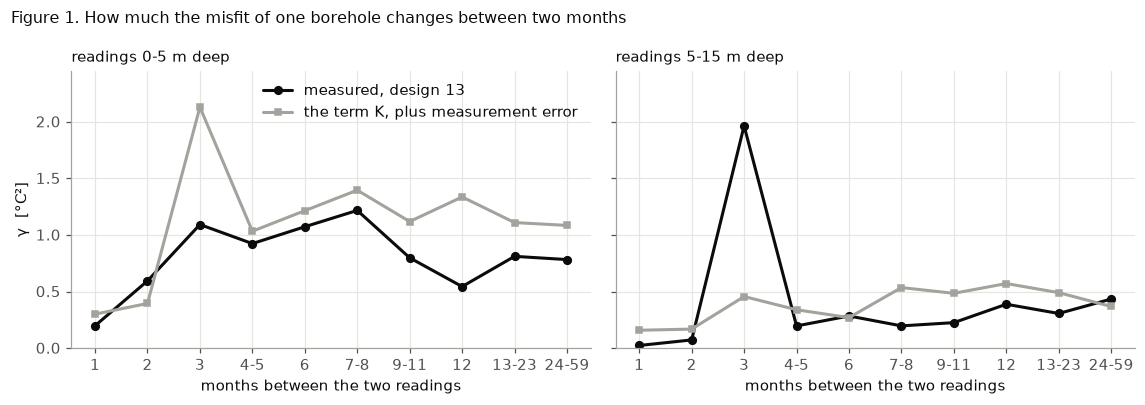

In [9]:
rep2 = json.loads((STEP5A / 'stage2' / 'report.json').read_text())
wb = rep2['within_borehole']
lags = ['1', '2', '3', '4-5', '6', '7-8', '9-11', '12', '13-23', '24-59', '60-119']
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), sharey=True)
for ax, band in zip(axes, ['0-5 m', '5-15 m']):
    npts = wb[f"('points', '{band}')"]
    use = [l for l in lags if (npts.get(l) or 0) >= 5]             # lag classes with at least 5 points
    x = np.arange(len(use))
    ax.plot(x, [wb[f"('d13', '{band}')"][l] for l in use], 'o-', color=INK, ms=5, label='measured, design 13')
    ax.plot(x, [wb[f"('fit', '{band}')"][l] for l in use], 's-', color=MUTED, ms=4.5,
            label='the term K, plus measurement error')
    ax.set_xticks(x, use)
    ax.set_xlabel('months between the two readings')
    ax.set_title(f'readings {band} deep')
    ax.set_ylim(0, 2.45)
axes[0].set_ylabel('γ  [°C²]')
axes[0].legend(loc='upper right')
fig.suptitle('Figure 1. How much the misfit of one borehole changes between two months', x=0.01, ha='left', fontsize=10.5)
fig.tight_layout()
plt.show()

Near the surface the misfit follows a yearly cycle: it differs most between months half a year
apart and less between the same months of different years (γ falls from 1.2 °C² at 7–8 months
to 0.5 °C² at 12 months). The term follows these swings only roughly: at 0–5 m it is too high at
3 months (2.13 against 1.09 °C² measured) and at 12 months (1.34 against 0.54 °C²), so it does
not reproduce the dip at 12 months. At 5–15 m it is too low at 3 months (0.46 against 1.96 °C²):
the June and September 1994 Grenz profiles differ there by summer meltwater that soaked in
unevenly. Below 30 m the misfit barely changes between months
(γ ≤ 0.003 °C² within 2 years, less than glenglat's own σ²). The lag classes with fewer than
5 points are not drawn (0–5 m and 5–15 m at 60–119 months); all classes are in Stage 2's
`report.log`.

In [10]:
t1, t2, t3 = TG['T1'], TG['T2'], TG['T3']
rmse2 = np.sqrt(np.mean((t2.Y - t2.y) ** 2, axis=1))          # T2 RMSE of each of the 32 runs
order = np.argsort(rmse2)
best5_rmse, med_run = [int(i) for i in order[:5]], int(order[len(order) // 2])
t3m = t3lit.rows[~t3lit.rows.range_only.to_numpy()].reset_index(drop=True)   # rows dated to one month
Y3m, y3m = t3lit.Y[:, ~t3lit.rows.range_only.to_numpy()], t3lit.y[~t3lit.rows.range_only.to_numpy()]
spike = np.load(STEP5A / 'stage2' / 'spike_rows_month.npy')                  # six Colle Gnifetti melt rows
spike_keys = set(zip(t3m.t2.to_numpy()[spike], t3m.ym.to_numpy()[spike]))
sp3 = np.array([(a, b) in spike_keys for a, b in zip(t3.rows.t2, t3.rows.ym_first)]) & (t3.rows.kind == 'month').to_numpy()

sets = {  # name: rows, model (runs x rows), observed, D+S, K, add the date spread V
    'T2': (t2.rows, t2.Y, t2.y, ta.error_cov(t2.rows), None, False),
    'T3 (T3r rows)': (t3.rows, t3.Y, t3.y, ta.error_cov(t3.rows), ta.seasonal_cov(t3.rows), True),
    'T3 as first specified': (t3lit.rows, t3lit.Y, t3lit.y, ta.error_cov(t3lit.rows), ta.seasonal_cov(t3lit.rows), False),
    'T3 month rows only': (t3m, Y3m, y3m, ta.error_cov(t3m), ta.seasonal_cov(t3m), False)}


def ratio_at(name, run, with_k=True):
    rows, Y, y, DS, K, add_v = sets[name]
    C = DS + (K if (with_k and K is not None) else 0.0)
    if with_k and add_v:
        C = C + np.diag(ta.date_spread_var(rows, obs, s2['Y3'][run]))       # the run's own spread, as Stage 2
    return ta.misfit_ratio(Y[run] - y, C, rows)


tab = []
C1 = t1.Sigma
r1 = lambda run: float((t1.Y[run] - t1.y) @ np.linalg.solve(C1, t1.Y[run] - t1.y) / len(t1.y))
tab.append(dict(target='T1', rows=len(t1.y), **{'D + S only': r1(13), 'with K': r1(13)},
                **{'level part': np.nan, 'month-to-month part': np.nan},
                **{'best five runs': f"{min(r1(i) for i in best5_rmse):.2f}–{max(r1(i) for i in best5_rmse):.2f}",
                   f'median run ({med_run})': r1(med_run)}))
for name in sets:
    m0, m13 = ratio_at(name, 13, with_k=False), ratio_at(name, 13)
    b5 = [ratio_at(name, i)['ratio'] for i in best5_rmse]
    tab.append(dict(target=name, rows=m13['n'], **{'D + S only': m0['ratio'], 'with K': m13['ratio'],
                    'level part': m13['level'], 'month-to-month part': m13['month_to_month'],
                    'best five runs': f'{min(b5):.2f}–{max(b5):.2f}', f'median run ({med_run})': ratio_at(name, med_run)['ratio']}))
ratios = pd.DataFrame(tab).set_index('target')
print(f'misfit ratio r^T Sigma^-1 r / n at design 13 (best five runs by T2 RMSE: {best5_rmse}; median run {med_run})')
display(ratios)
C3 = t3.Sigma                                        # D + S + K + V(run 13)
r3 = t3.Y[13] - t3.y
no_spike = ta.misfit_ratio(r3[~sp3], C3[np.ix_(~sp3, ~sp3)], t3.rows[~sp3].reset_index(drop=True))
print(f"T3 without the six Colle Gnifetti melt rows ({sp3.sum()} rows): ratio {no_spike['ratio']:.3f}")
got('s2.T3r_ratio_noK', ratios.loc['T3 (T3r rows)', 'D + S only']); got('s2.T3r_ratio', ratios.loc['T3 (T3r rows)', 'with K'])
got('s2.T3r_level', ratios.loc['T3 (T3r rows)', 'level part']); got('s2.T3r_m2m', ratios.loc['T3 (T3r rows)', 'month-to-month part'])
got('s2.T3lit_ratio_noK', ratios.loc['T3 as first specified', 'D + S only']); got('s2.T3lit_ratio', ratios.loc['T3 as first specified', 'with K'])
got('s2.T3m_ratio', ratios.loc['T3 month rows only', 'with K']); got('s2.T1_ratio', ratios.loc['T1', 'with K'])
got('s2.T2_ratio', ratios.loc['T2', 'with K']); got('s2.T3r_median_run', ratios.loc['T3 (T3r rows)', f'median run ({med_run})'])
got('s2.T3r_no_spike', no_spike['ratio'])

misfit ratio r^T Sigma^-1 r / n at design 13 (best five runs by T2 RMSE: [13, 14, 3, 9, 0]; median run 28)


,rows,D + S only,with K,level part,month-to-month part,best five runs,median run (28)
target,,,,,,,
T1,66,1.992,1.992,NaN,NaN,1.99–2.31,3.114
T2,771,0.635,0.635,0.635,NaN,0.62–0.70,0.658
T3 (T3r rows),1671,26.321,0.663,0.648,0.676,0.63–0.73,0.616
T3 as first specified,3417,14.562,0.356,0.661,0.266,0.34–0.39,0.332
T3 month rows only,1503,28.572,0.686,0.688,0.685,0.65–0.75,0.643


T3 without the six Colle Gnifetti melt rows (6 rows): ratio 0.625


In [11]:
by = []
zb = ta.depth_band(t3.rows.depth)
for lab, mask in ([(f'depth {b}', zb == b) for b in bands]
                  + [(s, (t3.rows.system_short == s).to_numpy()) for s in sorted(t3.rows.system_short.unique())]):
    m = ta.misfit_ratio(r3[mask], C3[np.ix_(mask, mask)], t3.rows[mask].reset_index(drop=True))
    by.append(dict(group=lab, rows=m['n'], points=m['points'], ratio=m['ratio'], level=m['level'],
                   month_to_month=m['month_to_month']))
    got(f's2.by_{lab}', m['ratio'])
sens = []
for lab, change in [('as proposed', {}), ('no high-firn factor', dict(high=1.0)), ('no between-borehole part', dict(u0=0.0)),
                    ('no drift', dict(beta=0.0)), ('yearly-cycle share 0', dict(w=0.0)), ('yearly-cycle share 0.5', dict(w=0.5)),
                    ('depth lengths × 0.5', dict(lens=tuple(0.5 * np.array(p['lens'])))),
                    ('depth lengths × 2', dict(lens=tuple(2 * np.array(p['lens'])))),
                    ('variance × 0.5', dict(a=p['a'] * 0.5)), ('variance × 2', dict(a=p['a'] * 2))]:
    Cv = ta.error_cov(t3.rows) + ta.seasonal_cov(t3.rows, change) + np.diag(ta.date_spread_var(t3.rows, obs, s2['Y3'][13]))
    m = ta.misfit_ratio(r3, Cv, t3.rows)
    sens.append(dict(variant=lab, ratio=m['ratio'], month_to_month=m['month_to_month']))
    got(f's2.sens_{lab}', m['ratio'])
print('T3 at design 13: each group on its own, then with K changed')
display(pd.DataFrame(by).set_index('group').round(3))
display(pd.DataFrame(sens).set_index('variant').round(3))
display(pd.DataFrame(rep2['spike_rows']).rename(columns={'obs': 'borehole [°C]', 'model_d13': 'model, design 13 [°C]'})
        .set_index('entity'))

T3 at design 13: each group on its own, then with K changed


,rows,points,ratio,level,month_to_month
group,,,,,
depth 0-5 m,332,93,1.407,1.849,1.235
depth 5-15 m,585,211,0.619,0.704,0.572
depth 15-30 m,362,180,0.557,0.752,0.364
depth > 30 m,392,287,0.363,0.360,0.370
Bossons,152,124,0.527,0.547,0.438
Corvatsch,301,41,0.498,0.567,0.487
Hintereisferner,208,57,1.110,0.553,1.319
Hohsaas,90,21,0.241,0.071,0.293
Monte Rosa,776,422,0.780,0.862,0.681


,ratio,month_to_month
variant,,
as proposed,0.663,0.676
no high-firn factor,1.018,1.336
no between-borehole part,1.108,1.503
no drift,0.743,0.824
yearly-cycle share 0,0.687,0.721
yearly-cycle share 0.5,0.720,0.782
depth lengths × 0.5,0.667,0.683
depth lengths × 2,0.733,0.806
variance × 0.5,0.886,1.092


,depth,ym,bh_label,borehole [°C],"model, design 13 [°C]"
entity,,,,,
Grenzgletscher@4455,2.02,200808,CG05-1,-11.53,-2.33
Grenzgletscher@4455,3.90,201509,CG05-1,-8.07,-0.93
Grenzgletscher@4455,5.94,201509,CG05-1,-10.30,-0.74
Grenzgletscher@4455,7.88,201509,CG05-1,-11.77,-1.52
Grenzgletscher@4455,8.95,201509,CG05-1,-12.12,-2.28
Grenzgletscher@4455,9.95,201509,CG05-1,-12.43,-3.30


**Reading.**
- **With K, T3 passes the honesty check:** its misfit ratio at design 13 is 0.663 (level part
  0.648, month-to-month part 0.676) and stays inside 0.5–2 at the five best runs by T2 RMSE
  (0.63–0.73) and at the median run (0.62). T1 and T2 do not change (1.99 and 0.635).
- **T3 as first specified fails it** (0.356): its repeated range-dated readings turn the model's own
  month-to-month changes into "misfits". That is why T3 means the T3r rows.
- **The term is honest on average but uneven.** It is right near the surface (0–5 m: 1.41), where
  the seasonal fingerprint lives; generous deeper (0.36–0.62) and at Tête Rousse, Hohsaas,
  Corvatsch and Bossons (0.14–0.53), so their month contrasts get less weight than they could;
  tight at Hintereisferner (1.11). Most of this is real site-to-site difference. The term is also
  the same in every season, while the misfits are not (Stage 2's season-pair table, pairs at most
  12 months apart): it over-covers winter pairs (0–5 m: 1.47 against 0.25 °C² measured; 5–15 m:
  0.51 against 0.09) and summer-to-autumn pairs at 0–5 m (1.28 against 0.59), but under-covers
  summer-to-autumn pairs at 5–15 m (0.27 against 1.31 °C²), where the meltwater arrives.
- **Six rows of Colle Gnifetti borehole CG05-1** (table above) are left out of the fit of K but
  kept in every ratio: in the hot summers of 2008 and 2015 the model melts this cold firn; the
  borehole shows no such warming. Without them the ratio is 0.625.
- **The parts are what matters most:** K is not very sensitive to its own details (0.52–0.89 in
  most variants), but dropping the high-firn factor or the between-borehole part doubles the
  month-to-month ratio (1.34 and 1.50).

## 4. Can each target tell f_ref and f_ins apart?

**How.** Near its best fit, a target's misfit rises like a bowl when a parameter moves away. How
steep the bowl is in each direction says how well each parameter is pinned down; a long flat
valley along a diagonal means the two parameters can replace each other. In numbers:
F = Jᵀ Σ⁻¹ J + P, where J says how far each row moves, in °C, per prior sd of each parameter, and P
is the prior's own share. Inverting F gives the two numbers of the rule: the **spread left** of
f_ins and the **correlation** of f_ref and f_ins after a fit.

**These are expectations, not calibrations.** They use the slopes J at one point, as if the misfit
bowl had the same shape everywhere; no fit was run. And P treats each prior as a bell curve with the
prior's own sd (P = 1 for both, as Stage 3a did). The exact priors are flat for f_ref (P = 0) and
slightly narrower for f_ins (P = 0.87); the cell after the main table shows that this changes T2
and T3 by at most 0.003.

J comes from two independent stand-ins for GloGEM, both trained on the 29 runs with f_ref ≥ 0.1:
- the **surface**: a quadratic polynomial in the three parameters for each row (median R² 0.996;
  error with one run left out 0.23–0.25 °C); recomputed below;
- the **emulator**: the calibration pipeline's own (7 patterns keeping 99.9 % of the variance, each
  learned by a Gaussian process), with its own uncertainty E added to Σ, taken at the evaluation
  point (error with one run left out 0.29–0.31 °C); its numbers take about 12 minutes (Stage 3a)
  and are read from `step5a/identifiability/results.pkl`. How the verdict changes when E varies
  with the parameters, as it does in the pipeline, is section 4.1.

Both are evaluated at the target's **best point** (the surface fit's optimum inside the area the
design covers, as the calibrator's coverage gate defines it; read from Stage 3a) and at its **5 best
runs** (the real runs with the smallest misfit for that target), with f_adv fixed at 1.0
("2 parameters") and free ("3 parameters").

In [12]:
def quad_basis(X):
    a, b, c = X.T
    return np.column_stack([np.ones(len(X)), a, b, c, a * a, b * b, c * c, a * b, a * c, b * c])


class QuadSurface:
    """Stage 3a's surface: a quadratic in (f_ref, f_ins, f_adv) per row, least squares over the given
    runs, parameters in prior-sd units. jac(theta): rows x 3, in C per prior sd."""

    def __init__(self, th, Y):
        self.c = th.mean(axis=0)
        self.coef = np.linalg.lstsq(quad_basis((th - self.c) / SD), Y, rcond=None)[0]

    def jac(self, t):
        x, b = (np.asarray(t, float) - self.c) / SD, self.coef
        return np.column_stack([b[1] + 2 * b[4] * x[0] + b[7] * x[1] + b[8] * x[2],
                                b[2] + 2 * b[5] * x[1] + b[7] * x[0] + b[9] * x[2],
                                b[3] + 2 * b[6] * x[2] + b[8] * x[0] + b[9] * x[1]])


def posterior(J, Sigma, free=(0, 1)):
    """Linearised posterior in prior-sd units, F = J^T Sigma^-1 J + I: (correlation f_ref-f_ins,
    spreads left, covariance)."""
    f = list(free)
    C = np.linalg.inv(J[:, f].T @ np.linalg.solve(Sigma, J[:, f]) + np.eye(len(f)))
    sd = np.sqrt(np.diag(C))
    return C[0, 1] / (sd[0] * sd[1]), sd, C


def told_apart(corr, spread_ins):
    return abs(corr) <= 0.8 and spread_ins <= 0.5


S3A = pickle.load(open(STEP5A / 'identifiability' / 'results.pkl', 'rb'))
KEY = {'T1': 'T1', 'T2': 'T2', 'T3': 'T3r'}                  # Stage 3a's target names


def surface_identifiability(ens, T):
    """Per (target, mode): the best point (Stage 3a), the posterior there, the 5 best runs by the
    target's own misfit on the real runs, and the posterior at each of them (2p: their f_ref, f_ins
    with f_adv = 1.0; 3p: their own three values)."""
    bp = S3A['bestpts']
    out = {}
    for name, t in T.items():
        surf = QuadSurface(theta[keep], (T['T2'].Y if name == 'T1' else t.Y)[keep])
        jac = (lambda q, s=surf, A=t.A2: A @ s.jac(q)) if name == 'T1' else surf.jac   # T1: pooled
        b = bp[(bp.ens == ens) & (bp.target == KEY[name]) & (bp.method == 'surface')].iloc[0]
        R = t.Y[ik] - t.y
        chi2 = np.einsum('ij,ij->i', R, np.linalg.solve(t.Sigma, R.T).T)
        runs5 = [int(i) for i in ik[np.argsort(chi2)[:5]]]
        for mode, best, free in (('2p', np.array([b.f_ref_2p, b.f_ins_2p, 1.0]), (0, 1)),
                                 ('3p', np.array([b.f_ref_3p, b.f_ins_3p, b.f_adv_3p]), (0, 1, 2))):
            at = [posterior(jac(np.r_[theta[i, :2], 1.0] if mode == '2p' else theta[i]), t.Sigma, free) for i in runs5]
            out[(name, mode)] = dict(best=best, post=posterior(jac(best), t.Sigma, free), runs=runs5, at_runs=at, jac=jac)
    return out


TG7 = build_targets(r7)
ID = {'alps_s2': surface_identifiability('alps_s2', TG), 'alps_r7': surface_identifiability('alps_r7', TG7)}

In [13]:
def id_record(ens, name, mode, method):
    """One line of the identifiability table: best point and 5 best runs, with the rule's verdicts."""
    if method == 'surface':
        r = ID[ens][(name, mode)]
        corr, sd, _ = r['post']
        best, runs = r['best'], r['runs']
        rc, rs = [a[0] for a in r['at_runs']], [a[1][1] for a in r['at_runs']]
        ra = [a[1][2] for a in r['at_runs']] if mode == '3p' else []
        s_ref, s_ins, s_adv = sd[0], sd[1], sd[2] if mode == '3p' else np.nan
    else:
        m = S3A['main']
        sel = m[(m.ens == ens) & (m.target == KEY[name]) & (m['mode'] == mode) & (m.method == method) & (m.variant == 'primary')]
        b = sel[sel.point == 'best point'].iloc[0]
        rr = sel[sel.point.str.startswith('run ')]
        corr, s_ref, s_ins, s_adv = b.corr_ref_ins, b.spread_f_ref, b.spread_f_ins, b.spread_f_adv
        best, runs = b[['f_ref', 'f_ins', 'f_adv']].to_numpy(float), [int(x.split()[1]) for x in rr.point]
        rc, rs, ra = rr.corr_ref_ins.tolist(), rr.spread_f_ins.tolist(), rr.spread_f_adv.tolist() if mode == '3p' else []
    n_pass = sum(told_apart(cc, ss) for cc, ss in zip(rc, rs))
    rec = {'best point': ', '.join(f'{v:.2f}' for v in best[:2 if mode == '2p' else 3]), 'correlation': corr,
           'spread f_ref': s_ref, 'spread f_ins': s_ins, '5 best runs': ' '.join(map(str, runs)),
           'runs: correlation': f'{min(rc):.2f}–{max(rc):.2f}', 'runs: spread f_ins': f'{min(rs):.2f}–{max(rs):.2f}',
           'runs passing': f'{n_pass}/5', 'told apart': told_apart(corr, s_ins) and n_pass >= 4}
    if mode == '3p':
        n_adv = sum(a <= 0.5 for a in ra)
        rec.update({'spread f_adv': s_adv, 'runs: spread f_adv': f'{min(ra):.2f}–{max(ra):.2f}',
                    'runs with f_adv ≤ 0.5': f'{n_adv}/5', 'f_adv passes': bool(s_adv <= 0.5 and n_adv >= 4 and rec['told apart'])})
    return rec


def id_table(ens, mode):
    recs = {(n, m): id_record(ens, n, mode, m) for n in ('T1', 'T2', 'T3') for m in ('surface', 'emulator')}
    return pd.DataFrame.from_dict(recs, orient='index').rename_axis(['target', 'method'])


ID2, ID3 = id_table('alps_s2', '2p'), id_table('alps_s2', '3p')
print('alps_s2, f_adv fixed at 1.0 (2 parameters). Surface: recomputed here; emulator: Stage 3a (results.pkl).')
display(ID2)
for n in ('T1', 'T2', 'T3'):
    for m in ('surface', 'emulator'):
        got(f'3a.{n}_{m}_corr', ID2.loc[(n, m), 'correlation']); got(f'3a.{n}_{m}_spread_ins', ID2.loc[(n, m), 'spread f_ins'])
    got(f'3a.{n}_surface_spread_ref', ID2.loc[(n, 'surface'), 'spread f_ref'])

alps_s2, f_adv fixed at 1.0 (2 parameters). Surface: recomputed here; emulator: Stage 3a (results.pkl).


best point  correlation  spread f_ref  spread f_ins    5 best runs runs: correlation runs: spread f_ins runs passing  told apart
target method                                                                                                                                    
T1     surface   0.53, 1.02        0.883         0.270         0.657    13 14 9 1 3         0.18–0.92          0.49–0.76          0/5       False
       emulator  0.53, 1.02        0.874         0.250         0.676    13 14 9 1 3         0.79–0.89          0.44–0.85          0/5       False
T2     surface   0.34, 0.76        0.577         0.089         0.188  15 14 25 23 0         0.49–0.60          0.22–0.33          5/5        True
       emulator  0.34, 0.76        0.496         0.086         0.230  15 14 25 23 0         0.43–0.63          0.24–0.34          5/5        True
T3     surface   0.27, 0.71        0.343         0.059         0.124  23 6 25 15 28         0.28–0.33          0.15–0.21          5/5        True
       emulator  0.27, 0.71        0.254         0.068         0.155  23 6 25 15 28         0.30–0.35          0.16–0.22          5/5        True

In [14]:
P_EXACT = np.diag([0.0, (SD[1] / 0.35) ** 2])     # f_ref uniform (flat); f_ins truncated normal, sd 0.35, in prior-sd units


def data_share(corr, s_ref, s_ins):
    """The data's share J^T Sigma^-1 J of a 2-parameter result computed with P = 1 (Stage 3a's emulator)."""
    C = np.array([[s_ref ** 2, corr * s_ref * s_ins], [corr * s_ref * s_ins, s_ins ** 2]])
    return np.linalg.inv(C) - np.eye(2)


PRIORS = {'bell-curve priors (P = 1, as above)': np.eye(2), 'exact priors': P_EXACT, 'data alone (no prior)': np.zeros((2, 2))}
EXP = {}
for n in ('T1', 'T2', 'T3'):
    r = ID['alps_s2'][(n, '2p')]
    J2 = r['jac'](r['best'])[:, :2]
    m_ = S3A['main']
    b = m_[(m_.ens == 'alps_s2') & (m_.target == KEY[n]) & (m_['mode'] == '2p') & (m_.method == 'emulator')
           & (m_.variant == 'primary') & (m_.point == 'best point')].iloc[0]
    for meth, Fd in (('surface', J2.T @ np.linalg.solve(TG[n].Sigma, J2)),
                     ('emulator', data_share(b.corr_ref_ins, b.spread_f_ref, b.spread_f_ins))):
        cell = {}
        for lab, P in PRIORS.items():
            C = np.linalg.inv(Fd + P)
            s = np.sqrt(np.diag(C))
            cell[lab] = f'{C[0, 1] / (s[0] * s[1]):.3f} / {s[1]:.3f}'
            EXP[(n, meth, lab)] = (C[0, 1] / (s[0] * s[1]), s[1])
        EXP[(n, meth)] = cell
print('Correlation / f_ins spread left at the best point, f_adv = 1.0, with three ways of counting the prior')
display(pd.DataFrame({k: v for k, v in EXP.items() if len(k) == 2}).T.rename_axis(['target', 'method']))
got('4.T1_surface_data_only_spread_ins', EXP[('T1', 'surface', 'data alone (no prior)')][1])

Correlation / f_ins spread left at the best point, f_adv = 1.0, with three ways of counting the prior


bell-curve priors (P = 1, as above)   exact priors data alone (no prior)
target method                                                                           
T1     surface                        0.883 / 0.657  0.896 / 0.698         0.936 / 0.918
       emulator                       0.874 / 0.676  0.887 / 0.716         0.933 / 0.961
T2     surface                        0.577 / 0.188  0.580 / 0.188         0.586 / 0.191
       emulator                       0.496 / 0.230  0.498 / 0.231         0.507 / 0.237
T3     surface                        0.343 / 0.124  0.344 / 0.124         0.346 / 0.125
       emulator                       0.254 / 0.155  0.255 / 0.155         0.258 / 0.157

In [15]:
cols3 = ['best point', 'correlation', 'spread f_ins', 'spread f_adv', 'runs: spread f_adv', 'runs with f_adv ≤ 0.5',
         'told apart', 'f_adv passes']
print('alps_s2, f_adv free (3 parameters): is f_adv worth freeing?')
display(ID3[cols3])
for n in ('T1', 'T2', 'T3'):
    for m in ('surface', 'emulator'):
        got(f'3a.{n}_{m}_spread_adv', ID3.loc[(n, m), 'spread f_adv'])
J = {n: ID['alps_s2'][(n, '2p')]['jac'](ID['alps_s2'][(n, '2p')]['best']) for n in ('T2', 'T3')}
display(pd.DataFrame({n: np.sqrt((J[n] ** 2).mean(axis=0)) for n in J}, index=['f_ref', 'f_ins', 'f_adv'])
        .rename_axis('°C per prior sd (rms over rows, surface, best point)'))

alps_s2, f_adv free (3 parameters): is f_adv worth freeing?


best point  correlation  spread f_ins  spread f_adv runs: spread f_adv runs with f_adv ≤ 0.5  told apart  f_adv passes
target method                                                                                                                                
T1     surface   0.53, 1.02, 0.99        0.850         0.660         0.911          0.82–0.91                   0/5       False         False
       emulator  0.53, 1.02, 0.99        0.832         0.675         0.912          0.89–0.96                   0/5       False         False
T2     surface   0.34, 0.76, 0.85        0.558         0.197         0.621          0.53–0.75                   0/5        True         False
       emulator  0.34, 0.76, 0.85        0.471         0.237         0.750          0.75–0.81                   0/5        True         False
T3     surface   0.27, 0.71, 0.87        0.322         0.130         0.480          0.46–0.68                   1/5        True         False
       emulator  0.27, 0.71, 0.87        0.236         0.154         0.718          0.70–0.78                   0/5        True         False

,T2,T3
"°C per prior sd (rms over rows, surface, best point)",,
f_ref,1.668,1.501
f_ins,0.785,0.775
f_adv,0.120,0.138


In [16]:
r7tab = pd.concat({'alps_r7 (before the snow fix)': id_table('alps_r7', '2p')[['correlation', 'spread f_ins', 'runs passing', 'told apart']],
                   'alps_s2': ID2[['correlation', 'spread f_ins', 'runs passing', 'told apart']]}, axis=1)
r7tab[('alps_r7 (before the snow fix)', 'spread f_adv (3 p.)')] = id_table('alps_r7', '3p')['spread f_adv']
r7tab[('alps_s2', 'spread f_adv (3 p.)')] = ID3['spread f_adv']
display(r7tab.sort_index(axis=1, level=0, sort_remaining=False))
for n in ('T1', 'T2', 'T3'):
    got(f'3a.r7_{n}_surface_corr', r7tab.loc[(n, 'surface'), ('alps_r7 (before the snow fix)', 'correlation')])
    got(f'3a.r7_{n}_surface_spread_ins', r7tab.loc[(n, 'surface'), ('alps_r7 (before the snow fix)', 'spread f_ins')])

alps_r7 (before the snow fix)                                                              alps_s2                                                         
                                  correlation spread f_ins runs passing told apart spread f_adv (3 p.) correlation spread f_ins runs passing told apart spread f_adv (3 p.)
target method                                                                                                                                                              
T1     surface                          0.882        0.677          0/5      False               0.822       0.883        0.657          0/5      False               0.911
       emulator                         0.896        0.693          0/5      False               0.855       0.874        0.676          0/5      False               0.912
T2     surface                          0.577        0.187          5/5       True               0.559       0.577        0.188          5/5       True               0.621
       emulator                         0.502        0.237          5/5       True               0.614       0.496        0.230          5/5       True               0.750
T3     surface                          0.333        0.125          5/5       True               0.472       0.343        0.124          5/5       True               0.480
       emulator                         0.308        0.181          5/5       True               0.619       0.254        0.155          5/5       True               0.718

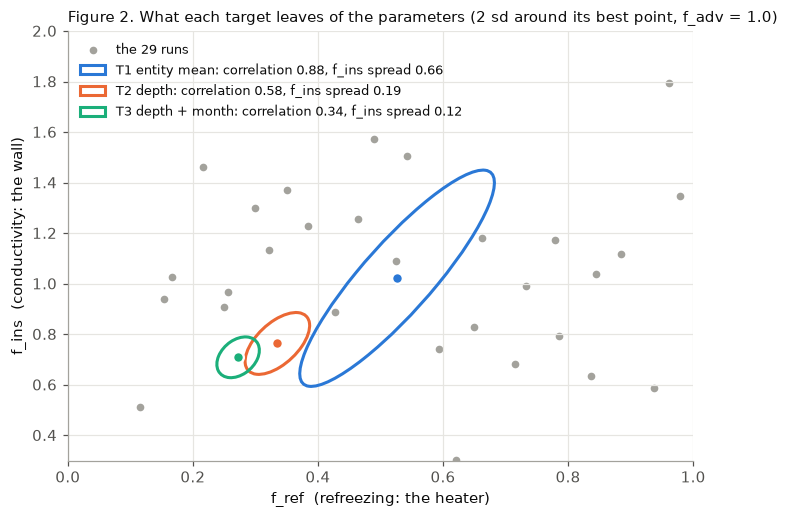

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.scatter(theta[keep, 0], theta[keep, 1], s=16, color=MUTED, zorder=1, label='the 29 runs')
label = {'T1': 'T1 entity mean', 'T2': 'T2 depth', 'T3': 'T3 depth + month'}
for n in ('T1', 'T2', 'T3'):
    r = ID['alps_s2'][(n, '2p')]
    Cn = r['post'][2] * np.outer(SD[:2], SD[:2])                 # posterior covariance, parameter units
    w, v = np.linalg.eigh(Cn)
    ang = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
    ax.add_patch(Ellipse(r['best'][:2], 4 * np.sqrt(w[1]), 4 * np.sqrt(w[0]), angle=ang, fill=False, lw=2,
                         color=COL[n], zorder=3, label=f"{label[n]}: correlation {r['post'][0]:.2f}, f_ins spread {r['post'][1][1]:.2f}"))
    ax.plot(*r['best'][:2], 'o', color=COL[n], ms=7, mec='white', mew=1.5, zorder=4)
ax.set_xlim(0, 1)
ax.set_ylim(0.3, 2.0)
ax.set_xlabel('f_ref  (refreezing: the heater)')
ax.set_ylabel('f_ins  (conductivity: the wall)')
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Figure 2. What each target leaves of the parameters (2 sd around its best point, f_adv = 1.0)', fontsize=10)
fig.tight_layout()
plt.show()

**Reading** (all expectations from the slopes at one point, see "How").
- **T1 cannot calibrate f_ins.** What a fit would leave is a long ridge ("raise both together"):
  f_ins keeps 66–68 % of its prior uncertainty, and the correlation is 0.87–0.88. None of the 5 best
  runs passes either. Data and prior contribute about equally to the 0.66: the data alone would
  leave 0.92 of f_ins's prior spread (correlation 0.94), the prior alone 1.
- **T2 and T3 are expected to tell f_ref and f_ins apart**, by both methods, at the best point and
  at all 5 best runs: correlation 0.50–0.58 (T2) and 0.25–0.34 (T3), f_ins spread left 0.19–0.23
  and 0.12–0.15. Their weakest direction is almost f_ins alone: the ridge is broken. Counting the
  priors exactly changes these numbers by at most 0.003 (second table); T1 gets slightly worse
  (0.90 / 0.70 with the surface).
- **T3 cuts the f_ins spread by about a third compared with T2**: 0.188 → 0.124 (surface) and
  0.230 → 0.155 (emulator), more than the 20 % the rule asks.
- **f_adv stays at 1.0.** With three parameters its spread left at the best point is 0.91 (T1),
  0.62–0.75 (T2) and 0.48–0.72 (T3); only T3 with the surface reaches 0.5 at the best point, and
  then at 1 of its 5 runs. f_adv moves the rows by 0.12–0.14 °C per prior sd, against 1.5–1.7 for
  f_ref and about 0.8 for f_ins. Freeing it would not stop T2 and T3 telling the other two apart.
  *How the rule is read here:* as written, it asks only that f_adv's spread left be ≤ 0.5 and that
  f_ref and f_ins still be told apart. This notebook applies the "told apart" reading (both
  methods, best point and 4 of 5 runs) to f_adv too, which is an interpretation. Read literally
  with the surface at the best point alone, T3 would pass (0.48); with the emulator (0.72), or at
  the 5 best runs (1 of 5), it does not.
- **alps_r7 (before the snow fix) gives the same verdicts and nearly the same numbers**: the
  separating information comes from the firn, and the snow fix acts only on ice bands.
- The best points of T2 and T3 lie at much lower f_ref and f_ins than T1's. That is the conflict of
  section 5.2.

In [18]:
inf = S3A['info']
sel = inf[(inf.ens == 'alps_s2') & (inf.method == 'surface') & (inf['mode'] == '2p')
          & inf.grouping.isin(['glacier system', 'depth band', 'firn label', 'season'])]
wide = {}
for n in ('T2', 'T3'):
    s = sel[sel.target == KEY[n]].set_index(['grouping', 'group'])
    wide[(n, 'rows')] = s.rows
    wide[(n, 'f_ins information')] = (100 * s.share_f_ins).round(0)
    wide[(n, 'separating information')] = (100 * s.share_weak).round(0)
info_tab = pd.DataFrame(wide)
order = [(g, x) for g, xs in (('glacier system', sorted(TG['T2'].rows.system_short.unique())),
                              ('depth band', bands), ('firn label', ['firn', 'ice', 'unknown']),
                              ('season', ['DJF', 'MAM', 'JJA', 'SON', 'several seasons', 'date range'])) for x in xs]
info_tab = info_tab.reindex([o for o in order if o in info_tab.index])
for n in ('T2', 'T3'):
    info_tab[(n, 'rows')] = info_tab[(n, 'rows')].astype('Int64')
print('Share of the information [%] at the best point (surface, f_adv = 1.0). "Separating" = along the weakest '
      'direction, the part that tells the two apart.')
display(info_tab)
adv = inf[(inf.ens == 'alps_s2') & (inf.method == 'surface') & (inf['mode'] == '3p')
          & (((inf.grouping == 'glacier system') & (inf.group == 'Monte Rosa')) | ((inf.grouping == 'firn label') & (inf.group == 'firn')))]
print('share of the f_adv information [%]:',
      {f"{r.target} {r.group}": round(100 * r.share_f_adv) for r in adv.itertuples()})

Share of the information [%] at the best point (surface, f_adv = 1.0). "Separating" = along the weakest direction, the part that tells the two apart.


T2                                             T3                                         
                                rows f_ins information separating information  rows f_ins information separating information
grouping       group                                                                                                        
glacier system Bossons           124              27.0                   11.0   152              17.0                    9.0
               Corvatsch          41               0.0                    0.0   301              10.0                   14.0
               Hintereisferner    57               6.0                    9.0   208              13.0                   14.0
               Hohsaas            21               0.0                    1.0    90               2.0                    2.0
               Monte Rosa        422              66.0                   79.0   776              58.0                   59.0
               Tête Rousse       106               0.0                    0.0   144               1.0                    1.0
depth band     0-5 m              93              22.0                   51.0   332              30.0                   42.0
               5-15 m            211              39.0                   37.0   585              37.0                   40.0
               15-30 m           180              27.0                    8.0   362              23.0                   13.0
               > 30 m            287              13.0                    5.0   392               9.0                    4.0
firn label     firn              488              81.0                   91.0  1166              80.0                   84.0
               ice               198               3.0                    5.0   406              11.0                   12.0
               unknown            85              16.0                    4.0    99              10.0                    4.0
season         DJF                16               1.0                    2.0   186               8.0                    9.0
               MAM                27              12.0                   16.0   185              26.0                   29.0
               JJA               209              49.0                   43.0   567              35.0                   34.0
               SON               178              16.0                   23.0   565              24.0                   26.0
               several seasons   341              22.0                   16.0  <NA>               NaN                    NaN
               date range       <NA>               NaN                    NaN   168               7.0                    2.0

share of the f_adv information [%]: {'T1 Monte Rosa': 40, 'T2 Monte Rosa': 78, 'T2 firn': 91, 'T3r Monte Rosa': 71, 'T3r firn': 94}


**Where the separating information comes from.**
- **Monte Rosa** holds most of it: 79 % of T2's and 59 % of T3's separating information. Bossons
  (Col du Dôme) adds 9–11 %; in T3 Corvatsch and Hintereisferner add 14 % each, through their
  month rows. Tête Rousse and Hohsaas contribute almost nothing.
- **The firn** carries 84–91 %; ice rows alone hardly pin f_ins in T2 (spread 0.65), but in T3 they
  do better (0.34), through the month-to-month changes under the winter snow.
- **The top 5 m** carry half of T2's separating information (51 %); in T3 the top 15 m carry 82 %.
- **In T3, spring carries f_ins almost alone** (26 % of the f_ins information, 1 % of f_ref's),
  and autumn half of the f_ref information (49 %).
- f_adv's information sits on Monte Rosa (71–78 %) and in the firn (91–94 %).

In [19]:
sens, ver, main = S3A['sens'], S3A['verdicts'], S3A['main']
variants = ['primary', 'campaign prior U[0.1,1] for f_ref', 'per-glacier offset delta in Sigma', 'surface LOO error added to Sigma',
            'emulator LOO error instead of E', 'emulator without E', 'emulator trained on all 32 runs',
            'emulator explained variance 0.99', 'emulator step +-0.25 prior sd', '5 best runs by RMSE']
cells = {}
for v in variants:
    src = main if v == 'primary' else sens
    for meth in ('surface', 'emulator'):
        row = {}
        for n in ('T1', 'T2', 'T3'):
            b = src[(src.ens == 'alps_s2') & (src.variant == v) & (src.method == meth) & (src.target == KEY[n])
                    & (src['mode'] == '2p') & (src.point == 'best point')]
            w = ver[(ver.ens == 'alps_s2') & (ver.variant == v) & (ver.method == meth) & (ver.target == KEY[n]) & (ver['mode'] == '2p')]
            if len(b) and len(w):
                b, w = b.iloc[0], w.iloc[0]
                row[n] = (f"{b.corr_ref_ins:.2f} / {b.spread_f_ins:.2f} ({int(w.runs_pass)}/5, "
                          + ('pass' if w.told_apart else 'fail') + ')')
        if row:
            cells[(v, meth)] = row
print('Sensitivities (Stage 3a), alps_s2, 2 parameters: correlation / f_ins spread at the best point (runs passing, verdict)')
VNAME = {'per-glacier offset delta in Sigma': 'per-glacier offset δ in Σ', 'surface LOO error added to Sigma': "surface's one-run-left-out error added to Σ",
         'emulator LOO error instead of E': "emulator's one-run-left-out error instead of E", 'emulator step +-0.25 prior sd': 'emulator slopes over ±0.25 prior sd'}
display(pd.DataFrame.from_dict(cells, orient='index').rename(index=VNAME, level=0).rename_axis(['variant', 'method']))
print('per-glacier offset delta: the calibrator\'s discrepancy GP fitted to the entity residuals:', S3A['delta_kernel']['kernel'])
own = S3A['bestpts'][(S3A['bestpts'].ens == 'alps_s2') & S3A['bestpts'].target.isin(['T2', 'T3r'])].copy()
eig = S3A['emu_own'].query("ens == 'alps_s2' and mode == '2p'").set_index(['target', 'point']).E_max_eig
best_eig = S3A['main'].query("ens == 'alps_s2' and mode == '2p' and method == 'emulator' and variant == 'primary' "
                             "and point == 'best point'").set_index('target').E_max_eig
own['E: largest pattern [°C²]'] = [best_eig[t] if m == 'surface' else eig[(t, 'own MAP with E' if 'with E' in m else 'own MAP without E')]
                                   for t, m in zip(own.target, own.method)]
own['where'] = own.method.replace({'surface': 'best point (surface optimum)', 'emulator with E (own MAP)': 'emulator optimum, E varying',
                                   'emulator without E (own MAP)': 'emulator optimum, without E'})
print(f"The emulator's optima (2 parameters); the coverage gate admits points up to {S3A['emu_meta'].gate_trust.iloc[0]:.2f} "
      f"from the nearest run (distances in units of the design's own spread of each parameter)")
display(own.assign(target=own.target.replace({'T3r': 'T3'})).set_index(['target', 'where'])[['f_ref_2p', 'f_ins_2p', 'nn_2p', 'E: largest pattern [°C²]']]
        .rename(columns={'f_ref_2p': 'f_ref', 'f_ins_2p': 'f_ins', 'nn_2p': 'distance to the nearest run'}).round(3))
sub = pd.read_csv(STEP5A / 'identifiability' / 'subsets.csv')
sub = sub[(sub['mode'] == '2p')]
sub['cell'] = sub.corr_ref_ins.map('{:.2f}'.format) + ' / ' + sub.spread_f_ins.map('{:.2f}'.format)
print('Leaving rows out (Stage 3a, best point; "the top 3 m" here means shallower than 3.0 m)')
display(sub.pivot_table(index=['subset', 'method'], columns='target', values='cell', aggfunc='first', sort=False))

Sensitivities (Stage 3a), alps_s2, 2 parameters: correlation / f_ins spread at the best point (runs passing, verdict)


T1                       T2                        T3
variant                                        method                                                                              
primary                                        surface   0.88 / 0.66 (0/5, fail)  0.58 / 0.19 (5/5, pass)   0.34 / 0.12 (5/5, pass)
                                               emulator  0.87 / 0.68 (0/5, fail)  0.50 / 0.23 (5/5, pass)   0.25 / 0.15 (5/5, pass)
campaign prior U[0.1,1] for f_ref              surface   0.88 / 0.65 (0/5, fail)  0.58 / 0.19 (5/5, pass)   0.34 / 0.12 (5/5, pass)
                                               emulator  0.87 / 0.67 (0/5, fail)  0.50 / 0.23 (5/5, pass)   0.25 / 0.15 (5/5, pass)
per-glacier offset δ in Σ                      surface   0.71 / 0.85 (0/5, fail)  0.38 / 0.21 (5/5, pass)   0.16 / 0.13 (5/5, pass)
                                               emulator  0.69 / 0.86 (0/5, fail)  0.34 / 0.24 (5/5, pass)   0.16 / 0.16 (5/5, pass)
surface's one-run-left-out error added to Σ    surface   0.82 / 0.71 (0/5, fail)  0.51 / 0.21 (5/5, pass)   0.32 / 0.14 (5/5, pass)
emulator's one-run-left-out error instead of E emulator  0.74 / 0.74 (0/5, fail)  0.32 / 0.24 (5/5, pass)   0.17 / 0.17 (5/5, pass)
emulator without E                             emulator  0.88 / 0.67 (0/5, fail)  0.37 / 0.19 (5/5, pass)   0.21 / 0.12 (5/5, pass)
emulator trained on all 32 runs                emulator  0.81 / 0.64 (1/5, fail)  0.07 / 0.22 (5/5, pass)  -0.12 / 0.16 (5/5, pass)
emulator explained variance 0.99               emulator  0.85 / 0.69 (0/5, fail)  0.70 / 0.55 (0/5, fail)   0.41 / 0.21 (5/5, pass)
emulator slopes over ±0.25 prior sd            emulator  0.88 / 0.68 (0/5, fail)  0.50 / 0.23 (5/5, pass)   0.26 / 0.15 (5/5, pass)
5 best runs by RMSE                            surface   0.88 / 0.66 (0/5, fail)  0.58 / 0.19 (5/5, pass)   0.34 / 0.12 (5/5, pass)
                                               emulator  0.87 / 0.68 (0/5, fail)  0.50 / 0.23 (5/5, pass)   0.25 / 0.15 (5/5, pass)

per-glacier offset delta: the calibrator's discrepancy GP fitted to the entity residuals: 2.25**2 * Matern(length_scale=[0.125, 0.22, 298, 1.2e+04], nu=1.5) + WhiteKernel(noise_level=0.238)
The emulator's optima (2 parameters); the coverage gate admits points up to 1.26 from the nearest run (distances in units of the design's own spread of each parameter)


f_ref  f_ins  distance to the nearest run  E: largest pattern [°C²]
target where                                                                                            
T2     best point (surface optimum)  0.335  0.764                        0.598                     2.372
       emulator optimum, E varying   0.278  0.496                        1.262                     9.758
       emulator optimum, without E   0.341  0.782                        0.573                     2.038
T3     best point (surface optimum)  0.272  0.709                        0.651                    13.652
       emulator optimum, E varying   0.415  1.793                        1.262                   102.681
       emulator optimum, without E   0.251  0.638                        0.845                    17.451

Leaving rows out (Stage 3a, best point; "the top 3 m" here means shallower than 3.0 m)


target                                                           T1           T2          T3r
subset                                        method                                         
all rows                                      surface   0.88 / 0.66  0.58 / 0.19  0.34 / 0.12
                                              emulator  0.87 / 0.68  0.50 / 0.23  0.25 / 0.15
without the top 3 m                           surface   0.88 / 0.64  0.68 / 0.23  0.41 / 0.15
                                              emulator  0.87 / 0.67  0.57 / 0.28  0.31 / 0.18
without Colle Gnifetti > 40 m                 surface   0.88 / 0.66  0.57 / 0.19  0.33 / 0.12
                                              emulator  0.87 / 0.68  0.49 / 0.23  0.25 / 0.16
without the Hintereisferner tongue            surface   0.89 / 0.68  0.58 / 0.19  0.36 / 0.13
                                              emulator  0.88 / 0.70  0.50 / 0.23  0.26 / 0.16
without Monte Rosa                            surface   0.86 / 0.81  0.76 / 0.40  0.38 / 0.19
                                              emulator  0.85 / 0.82  0.62 / 0.43  0.26 / 0.21
without the top 3 m and Colle Gnifetti > 40 m surface   0.88 / 0.65  0.67 / 0.23  0.40 / 0.15
                                              emulator  0.87 / 0.67  0.56 / 0.28  0.30 / 0.18

**Reading the sensitivities.**
- **Nothing changes the verdicts except one setting:** with the emulator keeping only 99 % of the
  variance, T2 loses the f_ins information (correlation 0.70, spread 0.55: fails, 0 of 5 runs). The
  campaign needs `explained_variance: 0.999` (your yaml).
- **The per-glacier offset δ in Σ** (sd 2.25 °C per borehole site, fitted as the calibrator does)
  absorbs the level: it lowers the correlation but widens f_ins; T1 still fails, T2 and T3 still
  pass.
- **Without Monte Rosa**, T2 comes close to the 0.8 limit (0.76, spread 0.40); T3 stays clear
  (0.38 / 0.19).
- **The emulator's optimum depends on E.** Two optima of the same emulator appear from here on,
  with two names:
  - *the emulator optimum, E varying*: E (its own uncertainty) computed afresh at every parameter
    set, as the pipeline does. For T2 and T3 it lands on the edge of the area the design covers
    (T3 at f_ref 0.42, f_ins 1.79), where E is largest: its largest pattern reaches 103 °C² there,
    against 14 °C² at the surface's best point, and such an E "explains away" misfit;
  - *the emulator optimum without E*: it agrees with the surface (T2: 0.34, 0.78 against 0.34,
    0.76).
  This is why section 4's emulator numbers take E at the surface's best point. What happens when E
  varies is the next section.

### 4.1 When the emulator's uncertainty E varies with the parameters

The table above takes E at one point. In the pipeline E changes with the parameters, and a fit then
also scores how large E is. Two diagnostics:
- **E varying** (Stage 3a's emulator, exact fits on Stage 3a's grid, read from `results.pkl` and
  recomputed with Stage 3a's code in `step5a/revise/r04_emuE_grid.py`): where the fit puts its
  weight, and whether it tells the parameters apart;
- **E held fixed** (Stage 3c's emulator, a separate build of the same kind, with E computed once at
  three points and scaled by three factors; `checks/c01c_emuE_diag.py` for T2, extended to T3 in
  `step5a/revise/r05_emuE_fixed.py`).

In [20]:
REV = STEP5A / 'revise'
gq = S3A['grid'][S3A['grid'].ens == 'alps_s2'].assign(target=lambda d: d.target.replace({'T3r': 'T3'}))
gq = gq[gq.target.isin(['T1', 'T2', 'T3'])].set_index(['target', 'method'])
eg = json.loads((REV / 'emuE_grid.json').read_text())
gtab = gq[['correlation' if 'correlation' in gq else 'corr', 'spread_f_ins']].rename(columns={'corr': 'correlation', 'spread_f_ins': 'spread f_ins'})
gtab['told apart'] = [told_apart(c, s) for c, s in zip(gtab.correlation, gtab['spread f_ins'])]
for n, key in (('T2', 'T2'), ('T3', 'T3r')):
    for lab, m in (('with E', 'emulator with E (own MAP)'), ('without E', 'emulator without E (own MAP)')):
        d = eg[f'{key} {lab}']
        assert abs(d['corr'] - gtab.loc[(n, m), 'correlation']) < 1e-3                 # recomputation = results.pkl
        gtab.loc[(n, m), 'weight at f_ins > 1.4'] = d['share_f_ins_above_1p4']
        gtab.loc[(n, m), 'weight near the gate edge'] = d['share_near_edge']
        gtab.loc[(n, m), 'f_ins 5 / 50 / 95 %'] = f"{d['f_ins_q05']:.2f} / {d['f_ins_q50']:.2f} / {d['f_ins_q95']:.2f}"
gtab = gtab.rename(index={'emulator with E (own MAP)': 'emulator, E varying', 'emulator without E (own MAP)': 'emulator without E',
                          'surface': 'surface (quadratic)'})
print('Exact fits on the grid, f_adv = 1.0 (Stage 3a): correlation and f_ins spread left; where the weight sits')
display(gtab.round(3))
for n in ('T1', 'T2', 'T3'):
    got(f'4.1_{n}_emuE_corr', gtab.loc[(n, 'emulator, E varying'), 'correlation'])
    got(f'4.1_{n}_emuE_spread_ins', gtab.loc[(n, 'emulator, E varying'), 'spread f_ins'])
fx = pd.DataFrame(json.loads((REV / 'emuE_fixed.json').read_text()))
fx['target'] = fx.target.replace({'T3r': 'T3'})
fx['cell'] = (fx['corr'].map('{:.2f}'.format) + ' / ' + fx['spread_f_ins'].map('{:.2f}'.format)
              + np.where(fx.told_apart, '', '  FAIL'))
print('E held fixed (Stage 3c\'s emulator): correlation / f_ins spread left, exact grid fits; rows: where E was '
      'computed; columns: the factor E is scaled by')
display(fx.pivot_table(index=['target', 'E_at'], columns='inflation', values='cell', aggfunc='first', sort=False)
        .rename(columns=lambda x: f'E × {x:g}'))
print('largest pattern of E [°C²] at those points (scale 1):',
      {f"{r.target}, {r.E_at}": round(r.E_top, 2) for r in fx[fx.inflation == 1.0].itertuples()})
for n in ('T2', 'T3'):
    got(f'4.1_{n}_fixedE_fail', (~fx[fx.target == n].told_apart).sum())
sd29 = theta[keep].std(axis=0)                                  # the gate's units: the design's own sd
Z29 = theta[keep] / sd29
pair = np.sqrt(((Z29[:, None, :] - Z29[None, :, :]) ** 2).sum(-1))
np.fill_diagonal(pair, np.inf)
GATE = 2 * np.median(pair.min(axis=1))
b3 = pickle.load(open(STEP5A / 'checks' / 'baseline.pkl', 'rb'))['T3r']
nn3 = np.sqrt(((np.array([b3['emulator_E']['map_f_ref'], b3['emulator_E']['map_f_ins'], 1.0]) / sd29 - Z29) ** 2).sum(1)).min()
print(f"Stage 3c's T3 fit with E computed once at its first optimum and kept: optimum ({b3['emulator_E']['map_f_ref']:.3f}, {b3['emulator_E']['map_f_ins']:.3f}), "
      f"{nn3:.3f} from the nearest run where the gate admits {GATE:.3f}; correlation {b3['emulator_E']['corr']:.2f}, "
      f"f_ins spread {b3['emulator_E']['spread_f_ins']:.2f} (without E {b3['emulator']['corr']:.2f}, {b3['emulator']['spread_f_ins']:.2f})")

Exact fits on the grid, f_adv = 1.0 (Stage 3a): correlation and f_ins spread left; where the weight sits


correlation  spread f_ins  told apart  weight at f_ins > 1.4  weight near the gate edge f_ins 5 / 50 / 95 %
target method                                                                                                                          
T1     surface (quadratic)        0.809         0.639       False                    NaN                        NaN                 NaN
       emulator, E varying        0.870         0.700       False                    NaN                        NaN                 NaN
       emulator without E         0.871         0.698       False                    NaN                        NaN                 NaN
T2     surface (quadratic)        0.633         0.218        True                    NaN                        NaN                 NaN
       emulator, E varying        0.949         0.843       False                  0.053                      0.517  0.49 / 0.54 / 1.66
       emulator without E         0.647         0.347        True                  0.000                      0.002  0.62 / 0.80 / 0.99
T3     surface (quadratic)        0.395         0.140        True                    NaN                        NaN                 NaN
       emulator, E varying        0.904         1.421       False                  0.841                      0.867  0.50 / 1.78 / 1.79
       emulator without E         0.359         0.245        True                  0.000                      0.009  0.56 / 0.66 / 0.83

E held fixed (Stage 3c's emulator): correlation / f_ins spread left, exact grid fits; rows: where E was computed; columns: the factor E is scaled by


inflation                                                 E × 1          E × 0.708          E × 1.856
target E_at                                                                                          
T3     Stage 3c's emulator optimum without E        0.09 / 0.09        0.14 / 0.09        0.11 / 0.08
       surface optimum                              0.16 / 0.09        0.22 / 0.10        0.09 / 0.08
       design 13                                    0.39 / 0.23        0.40 / 0.23        0.38 / 0.22
T2     Stage 3c's emulator optimum without E  0.86 / 0.63  FAIL  0.83 / 0.54  FAIL  0.89 / 0.86  FAIL
       surface optimum                        0.82 / 0.50  FAIL        0.79 / 0.45  0.86 / 0.66  FAIL
       design 13                                    0.72 / 0.34        0.71 / 0.34        0.72 / 0.35

largest pattern of E [°C²] at those points (scale 1): {"T3, Stage 3c's emulator optimum without E": 12.82, 'T3, surface optimum': 7.58, 'T3, design 13': 0.53, "T2, Stage 3c's emulator optimum without E": 9.89, 'T2, surface optimum': 5.83, 'T2, design 13': 0.26}
Stage 3c's T3 fit with E computed once at its first optimum and kept: optimum (0.216, 0.497), 1.261 from the nearest run where the gate admits 1.262; correlation 0.14, f_ins spread 0.09 (without E 0.41, 0.24)


**Reading.**
- **With E varying, as the pipeline computes it, neither target is told apart on this design:**
  T2 correlation 0.95 and f_ins spread 0.84, T3 0.90 and 1.42 (T3 worse, T1 0.87 and 0.70). The
  fit is drawn to where no run lies, because there E is largest and "explains away" misfit: T3 puts
  84 % of its weight at f_ins > 1.4 and 87 % within 10 % of the coverage gate's edge; T2 52 % near
  the edge. Without E, both are told apart (T2 0.65 / 0.35, T3 0.36 / 0.25).
- **With E held fixed, T3 stays told apart in all 9 cases** (correlation ≤ 0.40, f_ins spread
  ≤ 0.23), **T2 fails in 5 of the 6 cases at its two optima** and passes only with E taken at
  design 13, where runs are close.
- **The two emulator builds disagree on how large E is:** at nearly the same T2 point, E's largest
  pattern is 2.4 °C² in Stage 3a's emulator (the package's) and 5.8 °C² in Stage 3c's.
- **The first version of this notebook quoted T3 as clearly told apart with E (correlation 0.14,
  f_ins spread 0.09).** That fit is narrow only because its optimum lies on the gate's edge (last
  line above), so the gate cuts its weight off; adding E to Σ cannot by itself make a fit narrower
  (without E the spread is 0.24). It is not evidence for T3.
- **What this means.** "Told apart" passes by the rule's two methods with E taken at the
  surface's best point; T3 is more robust than T2 only when E is held fixed; with E varying,
  neither target is told apart on 29 runs. E shrinks where runs are added, so this is first a
  property of the design. Before either target is adopted, 5b and the campaign must deal with it:
  runs near the optimum in the second stage, and a cap on E or a tighter coverage gate, checked on
  the campaign's own emulator.

## 5. Held-out RMSE, consistency and the honest error model

All three checks fit the parameters, so they need a stand-in for GloGEM between the runs. The main
one here is Stage 3b's **cubic surface**: per row, cubic in f_ref and f_ins and quadratic in f_adv,
trained on the 29 runs (its error with one run left out is 0.22 °C on T2, against 0.25 °C for the
quadratic of section 4). Its own uncertainty E is the covariance of those left-out errors, within
each entity. A fit minimises

  misfit(θ) + ((f_ins − 1) ÷ 0.35)²

on a grid of step 0.005 over the design range (f_ref 0.10–0.98, f_ins 0.30–1.79; f_ref is uniform,
so it has only bounds; f_adv = 1.0). Everything with the cubic surface is recomputed below (a few
seconds); the emulator, the quadratic surface and the bootstrap come from Stage 3b
(`step5a/heldout/`).

Sections 5.1–5.3 use the August error model (3.5 °C², 15 m), as the plan fixed in advance.
Section 5.4 repeats the checks with an error model fitted to the misfits, the sensitivity run the
plan asked for; it changes the outcome.

In [21]:
def cubic_basis(th, center):
    a, b, c = ((np.atleast_2d(th) - center) / SD).T
    return np.column_stack([np.ones(len(a)), a, b, c, a * a, b * b, a * b, a ** 3, b ** 3, a * a * b, a * b * b,
                            c * c, a * c, b * c])


class CubicSurface:
    """Stage 3b's main stand-in, per row; loo = leave-one-run-out errors (predicted - true)."""

    def __init__(self, th, Y):
        self.center = th.mean(axis=0)
        M = cubic_basis(th, self.center)
        self.coef = np.linalg.lstsq(M, Y, rcond=None)[0]
        self.loo = (M @ self.coef - Y) / (1 - np.diag(M @ np.linalg.pinv(M)))[:, None]

    def basis(self, th2):                                   # (f_ref, f_ins) with f_adv = 1.0
        th2 = np.atleast_2d(th2)
        return cubic_basis(np.column_stack([th2, np.ones(len(th2))]), self.center)

    def dbasis(self, th2, h=1e-4):                          # d basis / d (f_ref, f_ins)
        return np.column_stack([(self.basis(th2 + h * e) - self.basis(th2 - h * e))[0] / (2 * h) for e in np.eye(2)])


PARTS = {'total': ('total', None), 'level': ('level', None), 'shape': ('total', 'level'),
         'depth shape': ('points', 'level'), 'month-to-month': ('total', 'points')}


class Forms:
    """Per entity, a target's misfit r^T Sigma^-1 r as a quadratic form in the surface basis b(theta),
    b^T Q b - 2 b^T q + c, and its parts: level = GLS entity mean, points = GLS point means (T3),
    shape = total - level. Exact for a polynomial stand-in, and fast on a large grid."""

    def __init__(self, coef, y, Sigma, ent, pts=None):
        self.ents, self.f = np.unique(ent), {'total': [], 'level': [], 'points': []}
        for e in self.ents:
            j = np.flatnonzero(ent == e)
            L = np.linalg.cholesky(Sigma[np.ix_(j, j)])
            W, w, u = np.linalg.solve(L, coef[:, j].T), np.linalg.solve(L, y[j]), np.linalg.solve(L, np.ones(len(j)))
            Z = (pts[j][:, None] == np.unique(pts[j])[None, :]).astype(float) if pts is not None else np.ones((len(j), 1))
            for part, P in (('total', np.eye(len(j))), ('level', u[None, :] / np.linalg.norm(u)),
                            ('points', np.linalg.qr(np.linalg.solve(L, Z))[0].T)):
                A, a = P @ W, P @ w
                self.f[part].append((A.T @ A, A.T @ a, a @ a))

    def misfit(self, B, part='total'):                      # grid x entities
        one = lambda k: np.column_stack([np.sum((B @ Q) * B, axis=1) - 2 * B @ q + c for Q, q, c in self.f[k]])
        a, b = PARTS[part]
        return one(a) - (one(b) if b else 0.0)

    def fisher(self, dB, part='total'):                     # 2 x 2, natural units
        one = lambda k: sum(dB.T @ Q @ dB for Q, _, _ in self.f[k])
        a, b = PARTS[part]
        return one(a) - (one(b) if b else 0.0)


SURF = {n: CubicSurface(theta[keep], TG[n].Y[keep]) for n in ('T2', 'T3')}
ENT = {n: TG[n].rows.e.to_numpy(int) for n in TG}
blocks = lambda M, ent: np.where(ent[:, None] == ent[None, :], M, 0.0)
E2, E3 = (SURF[n].loo.T @ SURF[n].loo / keep.sum() for n in ('T2', 'T3'))
E_TERM = {'T1': np.diag(np.diag(TG['T1'].A2 @ E2 @ TG['T1'].A2.T)), 'T2': blocks(E2, ENT['T2']), 'T3': blocks(E3, ENT['T3'])}
COEF = {'T1': SURF['T2'].coef @ TG['T1'].A2.T, 'T2': SURF['T2'].coef, 'T3': SURF['T3'].coef}
FORMS = {n: Forms(COEF[n], TG[n].y, TG[n].Sigma + E_TERM[n], ENT[n], TG['T3'].rows.t2.to_numpy(int) if n == 'T3' else None)
         for n in TG}
GRID = np.array([(a, b) for a in np.arange(0.10, 0.98 + 1e-9, 0.005) for b in np.arange(0.30, 1.79 + 1e-9, 0.005)])
B = SURF['T2'].basis(GRID)
PEN = ((GRID[:, 1] - 1.0) / 0.35) ** 2                     # -2 log prior of f_ins
P_NAT = np.diag([0.0, 1 / 0.35 ** 2])                        # its curvature; f_ref uniform
SSE_RULER = Forms(COEF['T2'], TG['T2'].y, np.eye(len(TG['T2'].y)), ENT['T2']).misfit(B)   # T2 SSE per entity
ENTS = FORMS['T2'].ents
SE = pd.Series(TG['T2'].rows.system_short.to_numpy(object), index=ENT['T2']).groupby(level=0).first().reindex(ENTS).to_numpy(object)
NPTS = np.bincount(np.searchsorted(ENTS, ENT['T2']), minlength=len(ENTS))
SYSTEMS = sorted(set(SE))
assert all(np.array_equal(FORMS[n].ents, ENTS) for n in TG)

### 5.1 Held-out RMSE

**How.** Six folds, one per glacier system: fit θ on the other five systems with the target's own
misfit, then score the left-out system's **T2 points** at the fitted θ, so every target is measured
with the same ruler. The six folds' errors are pooled. T1's fit uses the T2 stand-in pooled with
`calibrator.py`'s weights. As a check without any stand-in, the last method picks the best of the
29 real runs.

In [22]:
def held_out(C, pen, sse, cand):
    """C: misfit per (candidate, entity); sse: T2 squared errors per (candidate, entity).
    Returns (pooled held-out RMSE, per-fold table, in-sample candidate index)."""
    recs = []
    for h in SYSTEMS:
        k = int(np.argmin(C[:, SE != h].sum(1) + pen))
        recs.append(dict(system=h, points=int(NPTS[SE == h].sum()), k=k, f_ref=cand[k, 0], f_ins=cand[k, 1],
                         sse=float(sse[k, SE == h].sum())))
    f = pd.DataFrame(recs).set_index('system')
    f['rmse'] = np.sqrt(f.sse / f.points)
    return float(np.sqrt(f.sse.sum() / f.points.sum())), f, int(np.argmin(C.sum(1) + pen))


def run_misfits(t):
    """Misfit per (real run, entity) for the 29 runs, no stand-in."""
    out = np.zeros((len(ik), len(ENTS)))
    for k, e in enumerate(ENTS):
        j = np.flatnonzero(t.rows.e.to_numpy(int) == e)
        R = t.Y[np.ix_(ik, j)] - t.y[j]
        out[:, k] = np.einsum('ij,ij->i', R, np.linalg.solve(t.Sigma[np.ix_(j, j)], R.T).T)
    return out


SSE_RUNS = np.column_stack([((TG['T2'].Y[ik][:, ENT['T2'] == e] - TG['T2'].y[ENT['T2'] == e]) ** 2).sum(1) for e in ENTS])
HO = {'RS': {n: held_out(FORMS[n].misfit(B), PEN, SSE_RULER, GRID) for n in TG},
      'RUNS': {n: held_out(run_misfits(TG[n]), ((theta[ik, 1] - 1.0) / 0.35) ** 2, SSE_RUNS, theta[ik]) for n in TG}}
S3B = json.loads((STEP5A / 'heldout' / 'results.json').read_text())
hor = S3B['heldout_rmse']
tab = {'cubic surface (main), recomputed': [HO['RS'][n][0] for n in TG],
       'emulator (Stage 3b)': [hor[f'EMU/E/{n}'] for n in TG],
       'quadratic surface (Stage 3b)': [hor[f'RSQ3/E/{n}'] for n in TG],
       'best of the 29 real runs, recomputed': [HO['RUNS'][n][0] for n in TG]}
hot = pd.DataFrame(tab, index=list(TG)).T
hot['T2 − T1'], hot['T3 − T1'], hot['T3 − T2'] = hot.T2 - hot.T1, hot.T3 - hot.T1, hot.T3 - hot.T2
print('Held-out RMSE on the 771 T2 points, pooled over the six folds [°C]')
display(hot.round(3))
for n in TG:
    got(f'3b.ho_RS_{n}', HO['RS'][n][0]); got(f'3b.ho_RUNS_{n}', HO['RUNS'][n][0])
got('3b.ho_RS_T2-T1', hot.loc['cubic surface (main), recomputed', 'T2 − T1'])
got('3b.ho_RS_T3-T1', hot.loc['cubic surface (main), recomputed', 'T3 − T1'])
got('3b.ho_RS_T3-T2', hot.loc['cubic surface (main), recomputed', 'T3 − T2'])

Held-out RMSE on the 771 T2 points, pooled over the six folds [°C]


,T1,T2,T3,T2 − T1,T3 − T1,T3 − T2
"cubic surface (main), recomputed",2.193,2.264,2.269,0.072,0.076,0.005
emulator (Stage 3b),2.185,2.259,2.263,0.074,0.078,0.003
quadratic surface (Stage 3b),2.182,2.259,2.201,0.077,0.019,-0.058
"best of the 29 real runs, recomputed",2.178,2.186,2.405,0.008,0.227,0.219


In [23]:
fold = pd.DataFrame({'RGI7': rgi.reindex(SYSTEMS), 'points': HO['RS']['T1'][1].points})
for n in TG:
    f = HO['RS'][n][1]
    fold[n] = [f'{r.rmse:.2f}  ({r.f_ref:.3f} / {r.f_ins:.3f})' for r in f.itertuples()]
    for s, r in f.iterrows():
        got(f'3b.fold_{n}_{s}', r.rmse)
fold.index.name = 'left out'
print('Per fold, cubic surface: held-out RMSE [°C] (fitted f_ref / f_ins)')
display(fold)
ins = {}
for n in TG:
    k = HO['RS'][n][2]
    rm = np.sqrt(SSE_RULER[k].sum() / NPTS.sum())
    ins[n] = {'cubic surface: f_ref, f_ins (T2 RMSE)': f'{GRID[k, 0]:.3f}, {GRID[k, 1]:.3f}  ({rm:.3f} °C)',
              'emulator (Stage 3b): f_ref, f_ins (T2 RMSE)': f"{S3B['in_sample'][f'EMU/E/{n}']['f_ref']:.3f}, "
              f"{S3B['in_sample'][f'EMU/E/{n}']['f_ins']:.3f}  ({S3B['in_sample'][f'EMU/E/{n}']['rmse_T2']:.3f} °C)",
              'best real run (T2 RMSE)': f"run {ik[HO['RUNS'][n][2]]}  ({np.sqrt(SSE_RUNS[HO['RUNS'][n][2]].sum() / NPTS.sum()):.3f} °C)"}
    got(f'3b.ins_RS_{n}_rmse', rm)
print('Fitted on all six systems')
display(pd.DataFrame(ins).T)

Per fold, cubic surface: held-out RMSE [°C] (fitted f_ref / f_ins)


,RGI7,points,T1,T2,T3
left out,,,,,
Bossons,00773,124,1.73 (0.535 / 0.935),1.47 (0.340 / 0.670),1.46 (0.255 / 0.640)
Corvatsch,02103,41,2.39 (0.525 / 0.985),2.41 (0.345 / 0.745),2.41 (0.275 / 0.665)
Hintereisferner,03116,57,2.55 (0.590 / 1.230),2.36 (0.400 / 0.975),2.11 (0.265 / 0.720)
Hohsaas,01112,21,0.62 (0.535 / 1.020),0.57 (0.340 / 0.730),0.56 (0.260 / 0.640)
Monte Rosa,01225 + 01230,422,2.47 (0.390 / 0.720),2.65 (0.240 / 0.525),2.69 (0.235 / 0.565)
Tête Rousse,00777,106,1.20 (0.520 / 0.970),1.21 (0.340 / 0.730),1.22 (0.260 / 0.650)


Fitted on all six systems


,"cubic surface: f_ref, f_ins (T2 RMSE)","emulator (Stage 3b): f_ref, f_ins (T2 RMSE)",best real run (T2 RMSE)
T1,"0.530, 1.005 (2.126 °C)","0.540, 1.030 (2.133 °C)",run 13 (2.129 °C)
T2,"0.340, 0.730 (2.165 °C)","0.310, 0.655 (2.182 °C)",run 15 (2.217 °C)
T3,"0.260, 0.645 (2.250 °C)","0.265, 0.775 (2.314 °C)",run 23 (2.405 °C)


**How sure are the stand-ins near each fit?** No real run lies at a fitted optimum, so the
held-out RMSE there is the stand-in's prediction. The check: leave each real run near a fit out of
the cubic surface, predict its T2 RMSE, and compare with the real value. If the stand-in errs at
the fit as much as at a nearby run, the cost changes by the difference of the two errors (the
target's and T1's).

In [24]:
near_h08 = (pd.DataFrame(json.loads((STEP5A / 'heldout' / 'h08_extra.json').read_text())['loo_near'])
            .drop_duplicates('run').set_index('run'))                    # a run's prediction does not depend on the fit
true_rm = np.sqrt(((TG['T2'].Y[ik] - TG['T2'].y) ** 2).mean(1))
pred_rm = np.sqrt(((TG['T2'].Y[ik] + SURF['T2'].loo - TG['T2'].y) ** 2).mean(1))     # loo = predicted - true
NEAR = []
for n in TG:
    th_n = GRID[HO['RS'][n][2]]
    d2 = np.sqrt((((theta[ik, :2] - th_n) / SD[:2]) ** 2).sum(1))
    d3 = np.sqrt((((theta[ik] - np.r_[th_n, 1.0]) / SD) ** 2).sum(1))
    for i in np.argsort(d2)[:3]:
        r = int(ik[i])
        NEAR.append({'fit': n, 'run': r, 'f_ref, f_ins, f_adv': ', '.join(f'{v:.2f}' for v in theta[r]),
                     'distance in f_ref, f_ins [prior sd]': d2[i], 'with f_adv': d3[i], 'real T2 RMSE': true_rm[i],
                     'cubic surface': pred_rm[i], 'cubic error': pred_rm[i] - true_rm[i],
                     'quadratic error (Stage 3b)': near_h08.loc[r, 'Q3'] - true_rm[i] if r in near_h08.index else np.nan,
                     'emulator error (Stage 3b)': near_h08.loc[r, 'EMU999'] - true_rm[i] if r in near_h08.index else np.nan})
NEAR = pd.DataFrame(NEAR).set_index(['fit', 'run'])
print('Real runs nearest each in-sample fit, left out of the stand-in and predicted: T2 RMSE [°C]; error = predicted − real')
display(NEAR.round(3))
err_t1 = NEAR.loc['T1', 'cubic error'].iloc[0]                 # T1's nearest run (13)
cost = {n: HO['RS'][n][0] - HO['RS']['T1'][0] for n in ('T2', 'T3')}
carried = {n: cost[n] - (NEAR.loc[n, 'cubic error'] - err_t1) for n in ('T2', 'T3')}
CARRIED = pd.DataFrame({n: {'cost, cubic surface [°C]': f'{cost[n]:+.3f}',
                            'cost if the stand-in errs at the fit as at each nearby run': ' / '.join(f'{v:+.3f}' for v in carried[n]),
                            'range': f'{carried[n].min():+.2f} to {carried[n].max():+.2f}',
                            'within the 0.10 °C margin': 'yes' if carried[n].max() <= 0.10 else
                            ('no' if carried[n].min() > 0.10 else 'not resolved')} for n in ('T2', 'T3')}).T
display(CARRIED)
for n in ('T2', 'T3'):
    got(f'5.1_carried_{n}_max', carried[n].max()); got(f'5.1_carried_{n}_min', carried[n].min())

Real runs nearest each in-sample fit, left out of the stand-in and predicted: T2 RMSE [°C]; error = predicted − real


f_ref, f_ins, f_adv  distance in f_ref, f_ins [prior sd]  with f_adv  real T2 RMSE  cubic surface  cubic error  quadratic error (Stage 3b)  emulator error (Stage 3b)
fit run                                                                                                                                                                      
T1  13     0.52, 1.09, 1.05                                0.259       0.343         2.129          2.119       -0.010                      -0.016                     -0.003
    14     0.43, 0.89, 1.29                                0.508       1.286         2.156          2.149       -0.007                      -0.009                     -0.003
    7      0.65, 0.83, 0.82                                0.686       1.005         2.403          2.394       -0.009                       0.009                      0.003
T2  14     0.43, 0.89, 1.29                                0.569       1.312         2.156          2.149       -0.007                      -0.009                     -0.003
    23     0.25, 0.91, 0.94                                0.626       0.676         2.405          2.418        0.013                      -0.014                      0.009
    6      0.26, 0.97, 1.19                                0.785       1.115         2.464          2.479        0.016                      -0.027                     -0.014
T3  19     0.12, 0.51, 0.67                                0.650       1.515         2.543          2.460       -0.083                      -0.033                     -0.234
    23     0.25, 0.91, 0.94                                0.802       0.842         2.405          2.418        0.013                      -0.014                      0.009
    14     0.43, 0.89, 1.29                                0.942       1.511         2.156          2.149       -0.007                      -0.009                     -0.003

,"cost, cubic surface [°C]",cost if the stand-in errs at the fit as at each nearby run,range,within the 0.10 °C margin
T2,+0.072,+0.069 / +0.049 / +0.046,+0.05 to +0.07,yes
T3,+0.076,+0.149 / +0.054 / +0.073,+0.05 to +0.15,not resolved


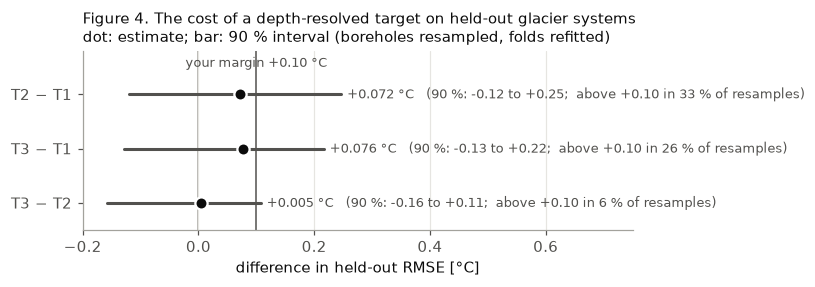

90 % intervals of the held-out RMSE difference [°C], cubic surface, 2,000 resamples (Stage 3b)


,"boreholes within each system, folds refitted (main)","points within each fold, fits kept",the six folds
T2 − T1,-0.12 to +0.25,+0.03 to +0.11,-0.18 to +0.15
T3 − T1,-0.13 to +0.22,+0.03 to +0.13,-0.26 to +0.18
T3 − T2,-0.16 to +0.11,-0.01 to +0.02,-0.11 to +0.03


In [25]:
bs = S3B['bootstrap']['RS/E']
lines = [('T2 − T1', 'T2-T1'), ('T3 − T1', 'T3-T1'), ('T3 − T2', 'T3-T2')]
fig, ax = plt.subplots(figsize=(7.2, 2.7))
for y, (lab, key) in enumerate(lines[::-1]):
    d = bs[f'a_boreholes_refit {key}']
    est = hot.loc['cubic surface (main), recomputed', lab]
    ax.plot([d['p05'], d['p95']], [y, y], color=INK2, lw=2, zorder=2)
    ax.plot(est, y, 'o', color=INK, ms=8, mec='white', mew=1.5, zorder=3)
    ax.text(d['p95'] + 0.01, y, f"{est:+.3f} °C   (90 %: {d['p05']:+.2f} to {d['p95']:+.2f};  above +0.10 in "
            f"{100 * d['frac_above_0p10']:.0f} % of resamples)", va='center', fontsize=8.5, color=INK2)
ax.axvline(0, color=MUTED, lw=1, zorder=1)
ax.axvline(0.10, color=INK2, lw=1, zorder=1)
ax.text(0.10, 2.45, 'your margin +0.10 °C', fontsize=8.5, color=INK2, ha='center', va='bottom')
ax.set_yticks(range(3), [l for l, _ in lines[::-1]])
ax.set_xlim(-0.2, 0.75)
ax.set_ylim(-0.5, 2.8)
ax.grid(axis='y', visible=False)
ax.set_xlabel('difference in held-out RMSE [°C]')
ax.set_title('Figure 4. The cost of a depth-resolved target on held-out glacier systems\n'
             'dot: estimate; bar: 90 % interval (boreholes resampled, folds refitted)', fontsize=10)
fig.tight_layout()
plt.show()
iv = pd.DataFrame({sch: {lab: f"{bs[f'{p} {key}']['p05']:+.2f} to {bs[f'{p} {key}']['p95']:+.2f}" for lab, key in lines}
                   for sch, p in (('boreholes within each system, folds refitted (main)', 'a_boreholes_refit'),
                                  ('points within each fold, fits kept', 'b_points_in_folds'),
                                  ('the six folds', 'c_folds'))})
print('90 % intervals of the held-out RMSE difference [°C], cubic surface, 2,000 resamples (Stage 3b)')
display(iv)

**Does T3's cost depend on its month-to-month term K?** K's parameters were fitted in Stage 2 to
the misfits of all six systems, including the one each fold leaves out. Below, T3's held-out cost
with K changed, and with K fitted again in each fold without the left-out system's months
(`step5a/revise/r01_kfold.py`: Stage 2's pair likelihood and settings; the depth-correlation
lengths kept; a factor with no data in a fold set to its neutral value: without Monte Rosa, the
high-firn factor is 1 and the between-borehole part 0). The last row shares half of each borehole's
measurement error between a point's months (section 3). The second column says whether T3 still
tells the parameters apart (slopes at the surface's best point, as in section 4).

In [26]:
KF = json.loads((STEP5A / 'revise' / 'kfold.json').read_text())
V3_ = np.diag(ta.date_spread_var(TG['T3'].rows, obs, s2['Y3'][ta.BEST_RUN]))
T3PTS = TG['T3'].rows.t2.to_numpy(int)
r3best = ID['alps_s2'][('T3', '2p')]
J3best = r3best['jac'](r3best['best'])


def t3_sigma(kparams=None, shared_d=0.0):
    return ta.error_cov(TG['T3'].rows, seasonal=lambda r: ta.seasonal_cov(r, kparams), shared_d=shared_d) + V3_


def t3_forms(Sig):
    return Forms(COEF['T3'], TG['T3'].y, Sig + E_TERM['T3'], ENT['T3'], T3PTS)


KCOST = {}
for lab, ch, sh in (('as fitted on all six systems (main)', None, 0.0), ('no high-firn factor', dict(high=1.0), 0.0),
                    ('no between-borehole part', dict(u0=0.0), 0.0), ('no drift', dict(beta=0.0), 0.0),
                    ('variance × 0.5', dict(a=ta.SEASONAL['a'] * 0.5), 0.0), ('variance × 2', dict(a=ta.SEASONAL['a'] * 2), 0.0),
                    ('measurement error half shared within a point', None, 0.5)):
    Sig = t3_sigma(ch, sh)
    c_, s_, _ = posterior(J3best, Sig)
    KCOST[lab] = {'T3 − T1 [°C]': held_out(t3_forms(Sig).misfit(B), PEN, SSE_RULER, GRID)[0] - HO['RS']['T1'][0],
                  'correlation / f_ins spread (slopes)': f'{c_:.2f} / {s_[1]:.2f}'}
sse_k, n_k, kfits = 0.0, 0, {}
for h in SYSTEMS:
    k = int(np.argmin(t3_forms(t3_sigma(KF[h]['seasonal'])).misfit(B)[:, SE != h].sum(1) + PEN))
    sse_k += SSE_RULER[k, SE == h].sum()
    n_k += NPTS[SE == h].sum()
    kfits[h] = f'{GRID[k, 0]:.3f} / {GRID[k, 1]:.3f}'
KCOST['fitted again in each fold, without the left-out system'] = {'T3 − T1 [°C]': np.sqrt(sse_k / n_k) - HO['RS']['T1'][0],
                                                                    'correlation / f_ins spread (slopes)': ''}
KCOST = pd.DataFrame(KCOST).T
print("T3's held-out cost over T1 [°C] (cubic surface, August S) and its separation, with K changed")
display(KCOST.assign(**{'T3 − T1 [°C]': KCOST['T3 − T1 [°C]'].astype(float).map('{:+.3f}'.format)}))
kp = pd.DataFrame({h: KF[h]['seasonal'] for h in ['all'] + SYSTEMS}).T
kp['pairs'] = [KF[h]['pairs'] for h in kp.index]
kp['T3 fit in the fold (f_ref / f_ins)'] = [''] + [kfits[h] for h in SYSTEMS]
kp.index = ['all six systems'] + [f'without {h}' for h in SYSTEMS]
print('K fitted per fold (median over the 29 runs; "high" = high-firn factor, "ice" = ice factor, u0 = between boreholes)')
display(kp.round(3))
got('5.1_T3_cost_kfold', KCOST.loc['fitted again in each fold, without the left-out system', 'T3 − T1 [°C]'])
got('5.1_T3_cost_no_drift', KCOST.loc['no drift', 'T3 − T1 [°C]'])
got('5.1_T3_cost_shared50', KCOST.loc['measurement error half shared within a point', 'T3 − T1 [°C]'])

T3's held-out cost over T1 [°C] (cubic surface, August S) and its separation, with K changed


,T3 − T1 [°C],correlation / f_ins spread (slopes)
as fitted on all six systems (main),+0.076,0.34 / 0.12
no high-firn factor,+0.098,0.15 / 0.10
no between-borehole part,+0.086,0.34 / 0.12
no drift,+0.175,0.35 / 0.12
variance × 0.5,+0.091,0.25 / 0.11
variance × 2,+0.073,0.42 / 0.14
measurement error half shared within a point,+0.070,0.33 / 0.12
"fitted again in each fold, without the left-out system",+0.069,


K fitted per fold (median over the 29 runs; "high" = high-firn factor, "ice" = ice factor, u0 = between boreholes)


,a,zs,w,tau,ice,high,u0,beta,pairs,T3 fit in the fold (f_ref / f_ins)
all six systems,2.986,3.497,0.288,7.047,0.250,5.366,0.454,0.035,5348,
without Bossons,2.986,3.497,0.288,7.047,0.250,5.366,0.454,0.035,5348,0.255 / 0.630
without Corvatsch,1.655,3.359,0.209,6.149,0.474,11.330,0.462,0.036,2143,0.280 / 0.690
without Hintereisferner,2.454,3.745,0.286,6.088,0.101,4.652,0.461,0.035,4494,0.265 / 0.745
without Hohsaas,2.687,3.650,0.317,6.692,0.292,5.006,0.456,0.035,4967,0.255 / 0.630
without Monte Rosa,4.426,3.119,0.276,12.897,0.256,1.000,0.000,0.021,4478,0.230 / 0.520
without Tête Rousse,2.994,3.531,0.295,6.979,0.244,5.142,0.399,0.047,5310,0.260 / 0.635


**Reading** (August error model).
- **T2 passes the RMSE check by every method:** held out it costs +0.072 °C over T1 (2.193 °C)
  with the cubic surface, +0.074 °C with the emulator, +0.077 °C with the quadratic surface and
  +0.008 °C choosing among the real runs. Near T2's fit the stand-in errs by at most 0.02 °C, which
  keeps the cost at +0.05 to +0.07 °C.
- **T3's RMSE check is not resolved.** The stand-ins pass it (+0.076 and +0.078 °C; the quadratic
  surface +0.019 °C); choosing among the real runs fails it (+0.227 °C: T3 picks run 23, f_ref 0.25,
  f_ins 0.91, f_adv 0.94, in every fold). No real run lies near T3's optimum. The nearest in f_ref
  and f_ins, run 19 (0.65 prior sd away, though at f_adv 0.67), is predicted 0.08 °C too low when
  left out of the cubic surface: if the stand-in errs as much at T3's fit, the cost is about
  +0.15 °C; if as little as at run 23, about +0.05 °C. The 0.024 °C left to the margin is smaller
  than that uncertainty. The two methods err in opposite directions: choosing among real runs
  overstates the cost of a target whose optimum has no run nearby (T3 has to take run 23, 0.80 prior
  sd from its optimum), and the stand-ins may understate it there. Only real runs near T3's
  optimum can decide it (the campaign's second stage).
- **T3 against T2:** +0.005 °C by the cubic surface, +0.003 °C by the emulator, +0.219 °C by the
  real runs; only the quadratic surface gives T3 the lower cost (−0.058 °C). The 90 % interval of
  T3 − T2 (cubic surface) is −0.16 to +0.11 °C.
- **K does not flatter T3.** Fitted again in each fold without the left-out system, K gives T3 a
  cost of +0.069 °C (main: +0.076 °C). Most of K's variants stay within 0.03 °C of the main value;
  without its drift part the cost rises to +0.175 °C, above the margin. Sharing half of each
  borehole's measurement error between a point's months (section 3) gives +0.070 °C. None of these
  changes stops T3 telling the parameters apart.
- **Six folds cannot tell whether the true cost is below the margin.** Resampling boreholes and
  refitting, the 90 % interval of T2 − T1 runs from −0.12 to +0.25 °C, and the cost exceeds
  0.10 °C in 26–33 % of the resamples. Resampling points only gives a narrower interval, but it
  wrongly treats every point of a borehole as independent and keeps the fits fixed.
- **Where they gain and where they lose.** Held out, T2 and T3 are better than T1 on Bossons and
  Hintereisferner (T3: 2.11 against 2.55 °C) and worse on Monte Rosa (2.65–2.69 against 2.47 °C).
  T1's own fit moves a lot when Monte Rosa is left out (f_ref 0.39, f_ins 0.72 instead of 0.53,
  1.01), T3's hardly moves (f_ref 0.235–0.275 in all folds).

### 5.2 Consistent: do the level and the shape want the same parameters?

**How.** The **level alone** is T1: each entity's depth-weighted mean. The **shape alone** is the
rest of the depth-resolved target: each entity's rows minus their mean, with the matching part of
Σ (in the misfit, the part left after the best-fitting entity mean is taken out). For T3 the shape
splits once more into the **depth shape** (the point means) and the **month-to-month** part. Each
is fitted on its own; the distance between two optima is measured in units of their combined
uncertainty after the fit, like a number of standard deviations (more than 3 fails).

In [27]:
def fit(name, part='total'):
    """Grid optimum of part + prior penalty, and the Gauss-Newton posterior covariance there."""
    k = int(np.argmin(FORMS[name].misfit(B, part).sum(1) + PEN))
    F = FORMS[name].fisher(SURF['T2'].dbasis(GRID[k:k + 1]), part)
    return dict(th=GRID[k], k=k, C=np.linalg.inv(F + P_NAT), name=name, part=part)


def distance(a, b):
    d = (a['th'] - b['th']) / SD[:2]
    S = (a['C'] + b['C']) / np.outer(SD[:2], SD[:2])
    return float(np.sqrt(d @ np.linalg.solve(S, d)))


FITS = {'level alone (T1)': fit('T1'), 'T2 shape alone': fit('T2', 'shape'), 'T3 shape alone': fit('T3', 'shape'),
        'T3 depth shape alone': fit('T3', 'depth shape'), 'T3 month-to-month alone': fit('T3', 'month-to-month'),
        'T2 whole': fit('T2'), 'T3 whole': fit('T3')}
ft = {}
for lab, r in FITS.items():
    Cs = r['C'] / np.outer(SD[:2], SD[:2])
    s = np.sqrt(np.diag(Cs))
    ft[lab] = {'f_ref': r['th'][0], 'f_ins': r['th'][1], 'uncertainty after the fit, f_ref [prior sd]': s[0],
               'uncertainty after the fit, f_ins [prior sd]': s[1], 'correlation': Cs[0, 1] / (s[0] * s[1])}
display(pd.DataFrame(ft).T)
L = FITS['level alone (T1)']
dist = {'T2: level vs shape': distance(L, FITS['T2 shape alone']), 'T3: level vs shape': distance(L, FITS['T3 shape alone']),
        'T3: level vs depth shape': distance(L, FITS['T3 depth shape alone']),
        'T3: level vs month-to-month': distance(L, FITS['T3 month-to-month alone']),
        'T3: depth shape vs month-to-month': distance(FITS['T3 depth shape alone'], FITS['T3 month-to-month alone'])}
display(pd.Series(dist, name='distance [sd]').round(2).to_frame())
for k, v in dist.items():
    got(f'3b.dist_{k}', v)
for lab in ('level alone (T1)', 'T2 shape alone', 'T3 shape alone'):
    got(f'3b.opt_{lab}_f_ref', FITS[lab]['th'][0]); got(f'3b.opt_{lab}_f_ins', FITS[lab]['th'][1])

,f_ref,f_ins,"uncertainty after the fit, f_ref [prior sd]","uncertainty after the fit, f_ins [prior sd]",correlation
level alone (T1),0.53,1.005,0.293,0.821,0.909
T2 shape alone,0.24,0.845,0.087,0.233,0.221
T3 shape alone,0.20,0.830,0.054,0.160,0.077
T3 depth shape alone,0.24,0.820,0.086,0.222,0.206
T3 month-to-month alone,0.17,0.900,0.069,0.234,0.019
T2 whole,0.34,0.730,0.086,0.197,0.557
T3 whole,0.26,0.645,0.054,0.123,0.278


,distance [sd]
T2: level vs shape,5.41
T3: level vs shape,6.90
T3: level vs depth shape,5.31
T3: level vs month-to-month,7.29
T3: depth shape vs month-to-month,2.43


In [28]:
var = pd.DataFrame(S3B['consistency']['variants'])
var['method'] = var.method.map({'RS': 'cubic surface', 'EMU': 'emulator', 'RSQ3': 'quadratic surface'}) + var.E.map({'E': '', 'noE': ', without E'})
long = var.melt(id_vars=['method', 'target'], value_vars=['d_main', 'd_gls_level', 'd_unit_prior', 'd_grid_moments'],
                var_name='definition')
long['definition'] = long.definition.map({'d_main': 'as defined', 'd_gls_level': 'level = best-fit entity mean',
                                          'd_unit_prior': 'prior weight 1 per prior sd', 'd_grid_moments': 'mean values of an exact grid fit'})
print('Distance between the level and the shape optima [sd] under other definitions and methods (Stage 3b)')
display(long.pivot_table(index=['target', 'definition'], columns='method', values='value', sort=False).round(2))
birge = json.loads((STEP5A / 'heldout' / 'h08_extra.json').read_text())['birge']
print('level uncertainty inflated by T1\'s own misfit ratio (x 1.99) and by 4, cubic surface:',
      {k.replace('RS/E ', ''): round(v, 2) for k, v in birge.items() if k.startswith('RS/E')})

Distance between the level and the shape optima [sd] under other definitions and methods (Stage 3b)


method                                   cubic surface  emulator  quadratic surface  cubic surface, without E  emulator, without E
target definition                                                                                                                 
T2     as defined                                 5.41      5.51               4.42                      5.43                 5.60
       level = best-fit entity mean               5.51      5.48               4.69                      5.52                 5.95
       prior weight 1 per prior sd                5.49      5.59               4.50                      5.50                 5.68
       mean values of an exact grid fit           4.97      5.05               4.29                      4.98                 5.20
T3     as defined                                 6.90      7.06               5.53                      7.02                 7.29
       level = best-fit entity mean               6.76      6.87               5.82                      6.96                 7.58
       prior weight 1 per prior sd                6.98      7.15               5.61                      7.10                 7.38
       mean values of an exact grid fit           6.43      6.53               5.27                      6.48                 6.82

level uncertainty inflated by T1's own misfit ratio (x 1.99) and by 4, cubic surface: {'T2 x1.00': 5.41, 'T2 x1.99': 4.26, 'T2 x4.00': 3.21, 'T3 x1.00': 6.9, 'T3 x1.99': 5.21, 'T3 x4.00': 3.81}


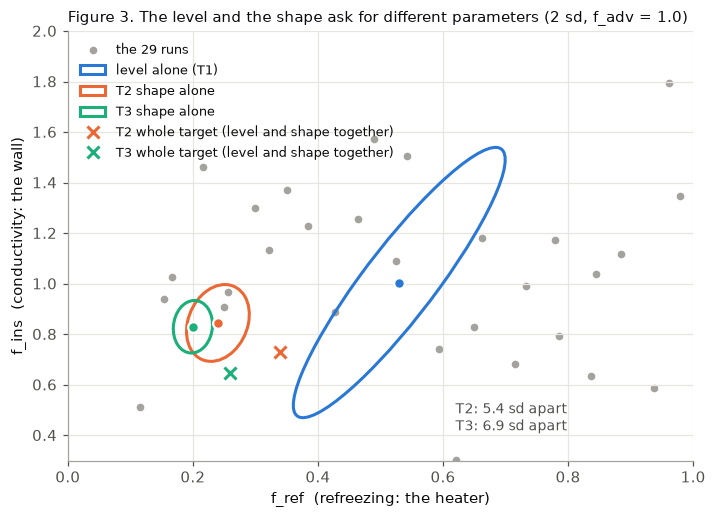

In [29]:
fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.scatter(theta[keep, 0], theta[keep, 1], s=16, color=MUTED, zorder=1, label='the 29 runs')
for lab, col in (('level alone (T1)', COL['T1']), ('T2 shape alone', COL['T2']), ('T3 shape alone', COL['T3'])):
    r = FITS[lab]
    w, v = np.linalg.eigh(r['C'])
    ax.add_patch(Ellipse(r['th'], 4 * np.sqrt(w[1]), 4 * np.sqrt(w[0]), angle=np.degrees(np.arctan2(v[1, 1], v[0, 1])),
                         fill=False, lw=2, color=col, zorder=3, label=lab))
    ax.plot(*r['th'], 'o', color=col, ms=7, mec='white', mew=1.5, zorder=4)
for lab, col in (('T2 whole', COL['T2']), ('T3 whole', COL['T3'])):
    ax.plot(*FITS[lab]['th'], 'x', color=col, ms=8, mew=2, zorder=4, label=f'{lab} target (level and shape together)')
ax.annotate(f"T2: {dist['T2: level vs shape']:.1f} sd apart\nT3: {dist['T3: level vs shape']:.1f} sd apart",
            xy=(0.62, 0.42), fontsize=9, color=INK2)
ax.set_xlim(0, 1)
ax.set_ylim(0.3, 2.0)
ax.set_xlabel('f_ref  (refreezing: the heater)')
ax.set_ylabel('f_ins  (conductivity: the wall)')
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Figure 3. The level and the shape ask for different parameters (2 sd, f_adv = 1.0)', fontsize=10)
fig.tight_layout()
plt.show()

In [30]:
def per_system(name, part, k):
    """Misfit per glacier system of a part at grid point k."""
    return pd.Series(FORMS[name].misfit(B[k:k + 1], part)[0], index=SE).groupby(level=0).sum()


att = {}
for n in ('T2', 'T3'):
    S = FITS[f'{n} shape alone']
    att[(n, 'level misfit rises by')] = per_system('T1', 'total', S['k']) - per_system('T1', 'total', L['k'])
    att[(n, 'shape misfit rises by')] = per_system(n, 'shape', L['k']) - per_system(n, 'shape', S['k'])
att = pd.DataFrame(att)
att.loc['all'] = att.sum()
print('Where the conflict sits: how much each fit\'s misfit rises at the other fit\'s optimum, per system [misfit units, rᵀ Σ⁻¹ r]')
display(att.round(1))
for n in ('T2', 'T3'):
    got(f'3b.att_{n}_MonteRosa_level', att.loc['Monte Rosa', (n, 'level misfit rises by')])
    got(f'3b.att_{n}_all_shape', att.loc['all', (n, 'shape misfit rises by')])
sub = pd.DataFrame(S3B['consistency']['where']['T2']['subsets']).set_index('rows')[['n', 'd_shape_vs_pooled_level']]
sub3 = pd.DataFrame(S3B['consistency']['where']['T3']['subsets']).set_index('rows')[['n', 'd_shape_vs_pooled_level']]
print('Each subset\'s shape alone against the pooled level [sd] (Stage 3b)')
display(pd.concat({'T2': sub, 'T3': sub3}, axis=1).round(2))
lv = pd.DataFrame(json.loads((STEP5A / 'heldout' / 'h08b_profile.json').read_text())['level'])
lv['cell'] = lv['mean'].map('{:+.2f}'.format) + ' (' + lv['rms'].map('{:.2f}'.format) + ')'
print('Entity-level misfit, model − boreholes [°C]: mean (rms) over the group\'s entities, at each optimum (Stage 3b)')
display(lv.pivot(index='group', columns='at', values='cell')[['level only', 'T2 shape only', 'T3 shape only']])

Where the conflict sits: how much each fit's misfit rises at the other fit's optimum, per system [misfit units, rᵀ Σ⁻¹ r]


T2                                          T3                      
                level misfit rises by shape misfit rises by level misfit rises by shape misfit rises by
Bossons                          15.2                  18.1                  21.4                  24.3
Corvatsch                        -0.0                   0.4                  -0.0                  20.7
Hintereisferner                  -1.3                   2.4                  -1.4                  -0.3
Hohsaas                          -0.1                   0.1                  -0.1                  -0.0
Monte Rosa                       46.6                  31.9                  61.5                 123.8
Tête Rousse                       0.2                   0.2                   0.2                   0.9
all                              60.6                  53.0                  81.6                 169.3

Each subset's shape alone against the pooled level [sd] (Stage 3b)


T2                            T3                        
                                n d_shape_vs_pooled_level     n d_shape_vs_pooled_level
rows                                                                                   
0-5 m                          93                    2.22   332                    3.11
5-15 m                        211                    2.38   585                    6.04
15-30 m                       180                    5.42   362                    6.99
> 30 m                        287                    2.81   392                    4.11
0-15 m                        304                    3.75   917                    5.26
> 15 m                        467                    6.11   754                    7.46
label firn                    488                    4.97  1166                    7.05
label ice                     198                    0.80   406                    1.77
label unknown                  85                    0.12    99                    0.21
Monte Rosa firn >= 3900 m     313                    4.78   663                    7.07
all but Monte Rosa >= 3900 m  458                    4.85  1008                    5.50

Entity-level misfit, model − boreholes [°C]: mean (rms) over the group's entities, at each optimum (Stage 3b)


at,level only,T2 shape only,T3 shape only
group,,,
Bossons,+0.14 (2.21),-1.72 (2.93),-2.01 (3.14)
Corvatsch,+2.06 (2.33),+2.06 (2.33),+2.06 (2.33)
Hintereisferner,-1.86 (2.22),-1.75 (2.09),-1.74 (2.08)
Hohsaas,-0.19 (0.56),-0.17 (0.52),-0.18 (0.51)
Monte Rosa < 3900 m,+0.24 (1.00),-0.16 (2.01),-0.24 (2.22)
Monte Rosa firn >= 3900 m,-0.06 (2.62),-1.93 (3.38),-2.23 (3.60)
Tête Rousse,+1.07 (1.21),+1.10 (1.23),+1.10 (1.24)


In [31]:
r2_ = TG['T2'].rows
sys_, band_ = r2_.system_short.to_numpy(object), r2_.band.to_numpy(float)
grp_pt = np.where((sys_ == 'Monte Rosa') & (band_ >= 3900), 'Monte Rosa firn ≥ 3900 m',
                  np.where(sys_ == 'Monte Rosa', 'Monte Rosa < 3900 m', sys_))
grp_ent = pd.Series(grp_pt).groupby(ENT['T2']).first().reindex(ENTS).to_numpy(object)
A_ = TG['T1'].A2


def entity_level(pred):
    """Mean over each group's entities of the entity's mean misfit (model − boreholes), °C."""
    return pd.Series(A_ @ (pred - TG['T2'].y), index=ENTS).groupby(grp_ent).mean()


LEVEL = {}
for lab in ('level alone (T1)', 'T2 whole', 'T3 whole', 'T2 shape alone', 'T3 shape alone'):
    th_ = FITS[lab]['th']
    LEVEL[f"{lab.replace('alone (T1)', 'alone')} ({th_[0]:.2f}, {th_[1]:.2f})"] = entity_level(
        (SURF['T2'].basis(th_[None, :]) @ SURF['T2'].coef)[0])
for run in (13, 15, 23):
    LEVEL[f'real run {run} ({theta[run, 0]:.2f}, {theta[run, 1]:.2f}, {theta[run, 2]:.2f})'] = entity_level(TG['T2'].Y[run])
LEVEL = pd.DataFrame(LEVEL)
print('Entity-level misfit, model − boreholes [°C], mean over each group\'s entities: at the fits (cubic surface) '
      'and at real runs 13 (T1\'s best), 15 (T2\'s) and 23 (T3\'s)')
display(LEVEL.round(2))
for c in LEVEL.columns[:3]:
    got(f"5.2_level_MR_{c.split(' (')[0]}", LEVEL.loc['Monte Rosa firn ≥ 3900 m', c])

Entity-level misfit, model − boreholes [°C], mean over each group's entities: at the fits (cubic surface) and at real runs 13 (T1's best), 15 (T2's) and 23 (T3's)


,"level alone (0.53, 1.01)","T2 whole (0.34, 0.73)","T3 whole (0.26, 0.65)","T2 shape alone (0.24, 0.85)","T3 shape alone (0.20, 0.83)","real run 13 (0.52, 1.09, 1.05)","real run 15 (0.38, 1.23, 0.62)","real run 23 (0.25, 0.91, 0.94)"
Bossons,0.14,-0.58,-1.01,-1.72,-2.01,-0.19,-0.97,-1.66
Corvatsch,2.06,2.07,2.08,2.06,2.06,2.05,2.04,2.05
Hintereisferner,-1.86,-1.63,-1.55,-1.75,-1.74,-1.91,-2.10,-1.81
Hohsaas,-0.19,-0.14,-0.13,-0.17,-0.18,-0.21,-0.25,-0.19
Monte Rosa < 3900 m,0.24,0.11,0.02,-0.16,-0.24,0.17,0.02,-0.17
Monte Rosa firn ≥ 3900 m,-0.06,-0.85,-1.30,-1.93,-2.23,-0.30,-1.23,-1.90
Tête Rousse,1.07,1.12,1.13,1.10,1.10,1.06,1.04,1.09


**Reading.**
- **CONSISTENT fails for T2 and T3.** The level alone is best at f_ref 0.53, f_ins 1.00; the shape
  alone at f_ref 0.24, f_ins 0.85 (T2) and 0.20, 0.83 (T3). They are 5.4 and 6.9 standard
  deviations apart, and every other definition or method gives more than 3 (4.3–7.6). Inflating
  the level's uncertainty by T1's own misfit ratio (×1.99) or by 4 still leaves 3.2–5.2.
- **In plain words:** how the temperature changes with depth and season inside a borehole asks for
  about half the refreezing at nearly the prior conductivity. At the shape's own optima the high
  firn of Monte Rosa (≥ 3,900 m) and Bossons (Col du Dôme) comes out about 2 °C too cold on
  average (−1.9 and −1.7 °C at T2's shape optimum, −2.2 and −2.0 °C at T3's, against −0.1 and
  +0.1 °C at the level's); all other groups move by at most 0.4 °C (0.5 °C at T3's).
- **At the parameters a calibration would adopt, the cost is smaller, and larger for T3 than for
  T2.** The level alone cannot choose a point along its ridge (correlation +0.91), so a whole T2 or
  T3 fit lands where that ridge meets the shape's region (f_ref 0.34 and 0.26, f_ins 0.73 and
  0.65: the × in Figure 3). There the Monte Rosa high firn is −0.85 °C too cold (T2) and −1.30 °C
  (T3), Bossons −0.58 and −1.01 °C (last table, by the cubic surface). At T3's best real run
  (run 23) they are −1.90 and −1.66 °C, at T2's (run 15) −1.23 and −0.97 °C.
- **Where it sits:** Monte Rosa carries about three quarters of the conflict and Bossons most of the
  rest; in T3, Corvatsch's month rows add to the shape side. The conflict lives in the firn (firn
  rows 5.0 and 7.1 sd, ice rows 0.8 and 1.8 sd), and more below 15 m (6.1 and 7.5 sd) than in the
  top 15 m (3.8 and 5.3 sd). Without Monte Rosa the distance is still 3.2 sd.
- **Within T3**, the depth shape and the month-to-month part agree with each other (2.4 sd); both
  disagree with the level.
- This is outcome 2's case: the parameters partly make up for a model error in the high firn.

### 5.3 Honest: are the misfits as large as the error model expects?

**How.** The misfit ratio rᵀ Σ⁻¹ r / n on the real runs (no stand-in, no E) at each target's best
run (the smallest misfit among the 32 runs), split into a level part (the best-fitting entity
means, one number per entity) and the rest within the entities. Picking the best of 32 runs pulls
the ratio down, so two more readings follow: the ratio at each target's fitted optimum (f_adv = 1.0;
cubic surface, without and with its uncertainty E) and its range over the target's 5 best runs.

In [32]:
def ratio_parts(t, Sigma, R):
    """Misfit ratio of each residual row of R (sets x rows) and its entity-level part (best-fitting entity means)."""
    R = np.atleast_2d(R)
    tot, lev = np.zeros(len(R)), np.zeros(len(R))
    for e in ENTS:
        j = np.flatnonzero(t.rows.e.to_numpy(int) == e)
        Lc = np.linalg.cholesky(Sigma[np.ix_(j, j)])
        W = np.linalg.solve(Lc, R[:, j].T)
        u = np.linalg.solve(Lc, np.ones(len(j)))
        tot += (W ** 2).sum(0)
        lev += (u @ W) ** 2 / (u @ u)
    return tot, lev


hon = {}
for n, t in TG.items():
    tot, lev = ratio_parts(t, t.Sigma, t.Y - t.y)
    i, nn, ne = int(np.argmin(tot)), len(t.y), len(ENTS)
    k = HO['RS'][n][2]
    pred = (SURF['T2'].basis(GRID[k:k + 1]) @ COEF[n])[0]
    r_opt = pred - t.y
    o5 = ik[np.argsort(tot[ik])[:5]]
    rec = {'best run': i, 'f_ref, f_ins, f_adv': ', '.join(f'{v:.2f}' for v in theta[i]), 'ratio': tot[i] / nn,
           'entity level part': lev[i] / ne, 'within-entity part': (tot[i] - lev[i]) / (nn - ne) if nn > ne else np.nan,
           'ratio at run 13': tot[13] / nn, 'runs with ratio 0.5-2': int(((tot / nn >= 0.5) & (tot / nn <= 2)).sum()),
           'at the fitted optimum': f'{GRID[k, 0]:.3f}, {GRID[k, 1]:.3f}',
           'ratio there': float(r_opt @ np.linalg.solve(t.Sigma, r_opt) / nn),
           'ratio there, with E': float(r_opt @ np.linalg.solve(t.Sigma + E_TERM[n], r_opt) / nn),
           '5 best of the 29 runs': ' '.join(map(str, o5)),
           'their ratios': f'{(tot[o5] / nn).min():.3f}–{(tot[o5] / nn).max():.3f}',
           'of them in 0.5–2': int(((tot[o5] / nn >= 0.5) & (tot[o5] / nn <= 2)).sum())}
    if n == 'T3':
        m = ta.misfit_ratio(t.Y[i] - t.y, t.Sigma, t.rows)
        rec.update({'point means': m['level'], 'month-to-month': m['month_to_month']})
    hon[n] = rec
    got(f'3b.honest_{n}', rec['ratio'])
    got(f'3b.honest_{n}_level', rec['entity level part'])
    got(f'5.3_ratio_at_opt_{n}', rec['ratio there'])
hon = pd.DataFrame(hon).T
display(hon)

,best run,"f_ref, f_ins, f_adv",ratio,entity level part,within-entity part,ratio at run 13,runs with ratio 0.5-2,at the fitted optimum,ratio there,"ratio there, with E",5 best of the 29 runs,their ratios,of them in 0.5–2,point means,month-to-month
T1,13,"0.52, 1.09, 1.05",1.992,1.992,NaN,1.992,1,"0.530, 1.005",1.957,1.906,13 14 9 1 3,1.992–2.214,1,NaN,NaN
T2,15,"0.38, 1.23, 0.62",0.605,2.353,0.441,0.635,32,"0.340, 0.730",0.589,0.577,15 14 25 23 0,0.605–0.632,5,NaN,NaN
T3,23,"0.25, 0.91, 0.94",0.588,2.92,0.492,0.663,32,"0.260, 0.645",0.578,0.57,23 6 25 15 28,0.588–0.616,5,0.635,0.547


**Reading.**
- **HONEST passes for all three at their best runs:** T1 1.992 at run 13, T2 0.605 at run 15 and
  T3 0.588 at run 23. T1's pass is at the limit and by selection: run 13 is the only one of the 32
  runs at or below 2, and its other 4 best runs give 2.09–2.21. At T1's fitted optimum the ratio is
  1.96 (1.91 with E). T2 and T3 stay inside 0.5–2 at their fitted optima (0.59 and 0.58) and at all
  of their 5 best runs (0.60–0.63), close to the lower limit. Note that T2's best run (15) has
  f_adv 0.62, not the 1.0 the rule fixes; the fitted optima have f_adv = 1.0.
- **The whole passes, but its parts do not.** The entity-level part is 2.35 (T2) and 2.92 (T3) at
  the best runs, above 2; the part within the entities is 0.44 and 0.49, below 0.5. The August
  model error (3.5 °C²) under-covers the borehole means and over-covers the shape within a
  borehole: a fit trusts the level more, and the shape less, than the misfits support. Inflating
  the level's uncertainty does not rescue CONSISTENT (still 3.2–5.2 sd, section 5.2). The plan
  kept the August model because the whole passes, and asked for the fitted one as a sensitivity:
  section 5.4.

### 5.4 The error model decides the outcome

**Why.** The parts above say the August error model is too tight on the level and too loose on the
shape. An error model fitted to the misfits themselves corrects that, so the shape steers more of
the fit, and the level, which dominates the RMSE, steers less. The plan asked for this as a
sensitivity run ("on alps_r7 it cost about 0.2 °C of held-out RMSE against T1").

**How.** Same form as the August model plus two terms: Σ = D + s · exp(−|dz| ÷ ℓ) + o + g within an
entity, with o shared by all rows of an entity (an entity offset, as an uncertainty, not a fitted
δ) and g shared by the rows of one point. The four numbers (s, ℓ, o, g) are fitted by maximum
likelihood to the T2 misfits of one real run: run 13 (T1's best), 15 (T2's) and 23 (T3's), each
on all six systems; and, to keep the left-out system out of its own error model, once more in each
fold on the other five systems (run 13). T3 keeps its month-to-month term K and date spread V. The
held-out RMSE is then recomputed exactly as in 5.1 (cubic surface with E, same folds, same T2
ruler), and the other three checks once with the run-13 fit.

In [33]:
EM_KEYS = ('variance', 'length', 'offset', 'nugget')
R2_ = TG['T2'].rows
V3_ = np.diag(ta.date_spread_var(TG['T3'].rows, obs, s2['Y3'][ta.BEST_RUN]))


def sigmas_em(em):
    """Sigma without E of T1, T2, T3 under error model em (variance, length, offset, nugget)."""
    return {'T1': ta.target_error_cov(TG['T1'], obs, **em), 'T2': ta.target_error_cov(TG['T2'], obs, **em),
            'T3': ta.target_error_cov(TG['T3'], obs, seasonal=ta.seasonal_cov, **em) + V3_}


def forms_em(Sig):
    return {n: Forms(COEF[n], TG[n].y, Sig[n] + E_TERM[n], ENT[n], T3PTS if n == 'T3' else None) for n in TG}


EMFITS, EMHO, EMSIG = {}, {}, {}
for run in (13, 15, 23):
    f_ = ta.fit_error_model(TG['T2'].Y[run] - TG['T2'].y, R2_)
    EMFITS[f'run {run}'] = f_
    EMSIG[f'run {run}'] = sigmas_em({k: f_[k] for k in EM_KEYS})
    F_ = forms_em(EMSIG[f'run {run}'])
    EMHO[f'run {run}'] = {n: held_out(F_[n].misfit(B), PEN, SSE_RULER, GRID) for n in TG}
# per fold: the error model fitted on the five training systems (run 13)
sse_f, n_f, per_fold = {n: 0.0 for n in TG}, 0, {}
for h in SYSTEMS:
    f_ = ta.fit_error_model(TG['T2'].Y[13] - TG['T2'].y, R2_, mask=(R2_.system_short != h).to_numpy())
    F_ = forms_em(sigmas_em({k: f_[k] for k in EM_KEYS}))
    per_fold[h] = {k: f_[k] for k in EM_KEYS}
    for n in TG:
        k = int(np.argmin(F_[n].misfit(B)[:, SE != h].sum(1) + PEN))
        sse_f[n] += SSE_RULER[k, SE == h].sum()
        per_fold[h][f'{n} fit'] = f'{GRID[k, 0]:.3f} / {GRID[k, 1]:.3f}'
    n_f += NPTS[SE == h].sum()
EMHO['run 13, refitted in each fold'] = {n: (np.sqrt(sse_f[n] / n_f),) for n in TG}
rows_em = {'August (3.5 °C², 15 m)': dict(variance=3.5, length=15.0, offset=0.0, nugget=0.0, **{'gain in log-likelihood': 0.0},
                                          **{f'held-out {n}': HO['RS'][n][0] for n in TG})}
for lab, f_ in EMFITS.items():
    rows_em[f'fitted at {lab}'] = {**{k: f_[k] for k in EM_KEYS}, 'gain in log-likelihood': f_['loglik'] - f_['loglik_august'],
                                   **{f'held-out {n}': EMHO[lab][n][0] for n in TG}}
rows_em['fitted at run 13, in each fold'] = {**{k: np.nan for k in EM_KEYS}, 'gain in log-likelihood': np.nan,
                                             **{f'held-out {n}': EMHO['run 13, refitted in each fold'][n][0] for n in TG}}
EMT = pd.DataFrame(rows_em).T
EMT['T2 − T1'], EMT['T3 − T1'] = EMT['held-out T2'] - EMT['held-out T1'], EMT['held-out T3'] - EMT['held-out T1']
EMT = EMT.rename(columns={'variance': 's [°C²]', 'length': 'ℓ [m]', 'offset': 'o [°C²]', 'nugget': 'g [°C²]'})
print('Error models and the held-out RMSE they give [°C] (cubic surface with E, six folds, T2 ruler)')
display(EMT.round(3))
print('fitted in each fold (run 13):')
display(pd.DataFrame(per_fold).T.round(3))
for lab in EMT.index[1:]:
    got(f'5.4_cost_T2_{lab}', EMT.loc[lab, 'T2 − T1']); got(f'5.4_cost_T3_{lab}', EMT.loc[lab, 'T3 − T1'])

Error models and the held-out RMSE they give [°C] (cubic surface with E, six folds, T2 ruler)


,s [°C²],ℓ [m],o [°C²],g [°C²],gain in log-likelihood,held-out T1,held-out T2,held-out T3,T2 − T1,T3 − T1
"August (3.5 °C², 15 m)",3.500,15.000,0.0,0.000,0.000,2.193,2.264,2.269,0.072,0.076
fitted at run 13,4.159,70.606,0.0,0.053,111.303,2.175,2.374,2.365,0.199,0.189
fitted at run 15,4.684,83.379,0.0,0.032,136.452,2.171,2.447,2.403,0.276,0.232
fitted at run 23,5.736,106.966,0.0,0.025,159.756,2.165,2.528,2.433,0.364,0.269
"fitted at run 13, in each fold",NaN,NaN,NaN,NaN,NaN,2.178,2.544,2.466,0.366,0.288


fitted in each fold (run 13):


,variance,length,offset,nugget,T1 fit,T2 fit,T3 fit
Bossons,2.621,39.491,1.324,0.053,0.495 / 0.800,0.310 / 0.710,0.250 / 0.685
Corvatsch,4.159,74.882,0.0,0.056,0.505 / 0.895,0.310 / 0.825,0.260 / 0.770
Hintereisferner,4.084,67.009,0.0,0.056,0.570 / 1.115,0.335 / 0.925,0.255 / 0.820
Hohsaas,4.397,72.33,0.0,0.053,0.515 / 0.925,0.310 / 0.830,0.245 / 0.750
Monte Rosa,3.642,154.143,0.0,0.015,0.440 / 0.790,0.185 / 0.845,0.185 / 0.695
Tête Rousse,2.404,30.805,2.138,0.056,0.495 / 0.865,0.310 / 0.800,0.245 / 0.735


In [34]:
SIG13 = EMSIG['run 13']
F13 = forms_em(SIG13)


def fit_em(name, part='total'):
    k = int(np.argmin(F13[name].misfit(B, part).sum(1) + PEN))
    F = F13[name].fisher(SURF['T2'].dbasis(GRID[k:k + 1]), part)
    return dict(th=GRID[k], k=k, C=np.linalg.inv(F + P_NAT))


EMCHK = {}
lev13 = fit_em('T1')
for n in ('T1', 'T2', 'T3'):
    t = TG[n]
    r_ = ID['alps_s2'][(n, '2p')]
    c_lin, sd_lin, _ = posterior(r_['jac'](r_['best']), SIG13[n], (0, 1))
    w_ = fit_em(n)
    Cs = w_['C'] / np.outer(SD[:2], SD[:2])
    s_ = np.sqrt(np.diag(Cs))
    tot, lev = ratio_parts(t, SIG13[n], t.Y - t.y)
    i, nn, ne = int(np.argmin(tot)), len(t.y), len(ENTS)
    EMCHK[n] = {'told apart, slopes at the best point (correlation / f_ins spread)': f'{c_lin:.2f} / {sd_lin[1]:.2f}',
                'whole fit: f_ref, f_ins': f"{w_['th'][0]:.3f}, {w_['th'][1]:.3f}",
                'whole fit: correlation / f_ins spread': f'{Cs[0, 1] / (s_[0] * s_[1]):.2f} / {s_[1]:.2f}',
                'level vs shape [sd]': '' if n == 'T1' else f"{distance(lev13, fit_em(n, 'shape')):.2f}",
                'honest: best run, ratio (level / within)': f'{i}: {tot[i] / nn:.2f} ({lev[i] / ne:.2f} / '
                + (f'{(tot[i] - lev[i]) / (nn - ne):.2f})' if nn > ne else '–)')}
print('The other checks with the error model fitted at run 13')
display(pd.DataFrame(EMCHK).T)

The other checks with the error model fitted at run 13


,"told apart, slopes at the best point (correlation / f_ins spread)","whole fit: f_ref, f_ins",whole fit: correlation / f_ins spread,level vs shape [sd],"honest: best run, ratio (level / within)"
T1,0.86 / 0.74,"0.510, 0.910",0.90 / 0.85,,13: 1.19 (1.19 / –)
T2,0.44 / 0.14,"0.310, 0.820",0.41 / 0.16,4.92,23: 0.89 (1.52 / 0.83)
T3,0.29 / 0.11,"0.250, 0.750",0.22 / 0.12,5.70,23: 0.72 (1.51 / 0.68)


**Reading.**
- **The fitted error model describes the misfits much better:** its log-likelihood is higher by
  111–160 (runs 13–23), and its misfit-ratio parts move inside 0.5–2 (T2: level 1.5, within 0.83,
  against 2.35 and 0.44 with the August model). On all six systems it puts nothing on the entity
  offset and uses a long depth correlation instead (70–110 m, variance 4.2–5.7 °C²), which acts
  like an offset on most boreholes; in two of the six folds it prefers an offset (1.3–2.1 °C²) with
  a 31–39 m correlation, the form the plan described.
- **With it, the RMSE check fails for both targets:** held out, T2 costs +0.20 to +0.36 °C over T1
  and T3 +0.19 to +0.27 °C (fitted at runs 13–23 on all systems); fitted in each fold without the
  left-out system, +0.37 and +0.29 °C. T1 itself gets slightly better (2.165–2.178 °C). T3 now
  costs less than T2 (by 0.01–0.09 °C), so even their order depends on the error model.
- **The other checks keep their verdicts:** both targets are still told apart (surface slopes at
  the best point: T2 correlation 0.44, f_ins spread 0.14; T3 0.29 and 0.11), CONSISTENT still fails
  (4.9 and 5.7 sd), and the misfit ratio passes as a whole and in its parts.
- **So the outcome depends on the error model:** with the August model T2 is outcome 2 (T3: not
  resolved, section 5.1); with a fitted one both are outcome 3 ("RMSE fails: you decide"). Letting
  the shape steer, which is what a depth-resolved target is for, costs 0.2–0.4 °C of held-out RMSE
  on these 7 glaciers, because shape and level disagree (section 5.2). The error model is your
  first decision (section 7).

## 6. The checks (a)–(g)

Seven questions from the plan, each answered on `alps_s2` with f_adv = 1.0, for T2 and T3. They
were run in Stage 3c as **exact fits on a grid** (not the slope-based expectations of section 4),
with the campaign prior for f_ref (uniform 0.1–1, prior sd 0.260), the quadratic surface and Stage
3c's emulator without E (both held at or below the melting point). So their reference fits are
slightly wider than section 4's: T2 correlation 0.63 and f_ins spread 0.22, T3 0.39 and 0.14
(surface). The tables come from `step5a/checks/`; row counts and a few headline numbers are
recomputed here. Where the surface and the emulator disagree, the emulator's own refitting noise
(retrained on the same runs with 0.01 °C added: f_ins moves by 0.11 prior sd for T2 and 0.21 for
T3, `c08_emu_refit_noise.log`) is the yardstick.

*Columns:* f_ref, f_ins = the fit's mean values; **shift** = how far they move against the fit with
all rows, in prior sd; **distance** = the same move in units of the uncertainty of the fit with all
rows (above about 1 it matters).

In [35]:
CK = STEP5A / 'checks'
ck = lambda f: pickle.load(open(CK / f, 'rb'))
REN = {'n': 'rows', 'mean_f_ref': 'f_ref', 'mean_f_ins': 'f_ins', 'corr': 'correlation', 'spread_f_ins': 'spread f_ins',
       'd_f_ref_prior_sd': 'shift f_ref', 'd_f_ins_prior_sd': 'shift f_ins', 'mahal_base': 'distance'}


def check_table(tab, variants=None, extra=(), methods=('surface', 'emulator')):
    t = tab[tab.method.isin(methods)]
    if variants is not None:
        t = t[t.variant.isin(variants)]
    t = t.assign(target=t.target.replace({'T3r': 'T3'})).set_index(['variant', 'target', 'method'])
    return t[[c for c in REN if c in t] + list(extra)].rename(columns=REN).round(3)


rows2, rows3 = TG['T2'].rows, TG['T3'].rows
grp2, grp3 = ta.group_of(rows2), ta.group_of(rows3)
quad = {n: QuadSurface(theta[keep], TG[n].Y[keep]) for n in ('T2', 'T3')}
pmp = {n: pressure_melting_point(TG[n].rows.depth.to_numpy(float)) for n in ('T2', 'T3')}
model_at = lambda n, f_ref, f_ins: np.minimum(quad[n].coef.T @ quad_basis(((np.array([f_ref, f_ins, 1.0]) - quad[n].c) / SD)[None, :])[0], pmp[n])

### (a) Do firn points and ice points want the same f_ins?

f_ins has two jobs: the firn's conductivity, and since Step 2 the winter snow on ice bands. Fitted
separately (f_ref free in both), firn rows and ice rows are compared; then each borehole group's
preferred f_ins with f_ref held at the joint optimum.

In [36]:
a = ck('c02_firn_ice.pkl')
display(check_table(a['table'], ['all rows', 'label firn', 'label ice', 'model ice band, without Hintereisferner tongue']))
z = a['z'][(a['z'].a.isin(['label firn', 'model firn band']))
           & a['z'].b.isin(['label ice', 'model ice band, without Hintereisferner tongue'])].copy()
z['target'] = z.target.replace({'T3r': 'T3'})
z['firn'] = z.f_ins_a.map('{:.2f}'.format) + ' ± ' + z.sd_a.map('{:.2f}'.format)
z['ice'] = z.f_ins_b.map('{:.2f}'.format) + ' ± ' + z.sd_b.map('{:.2f}'.format)
print('f_ins wanted by firn rows (a) and ice rows (b); difference in combined sd')
display(z.set_index(['target', 'a', 'b', 'method'])[['firn', 'ice', 'z']].round(2))
g = a['groups'][(a['groups'].target == 'T2') & (a['groups'].method == 'surface')]
print('T2, surface: each group\'s preferred f_ins with f_ref at the joint optimum (0.333)')
display(g.set_index('group')[['n', 'label', 'f_ins_data_opt', 'at_bound', 'dchi2_over_range', 'bias_at_joint']]
        .rename(columns={'n': 'points', 'f_ins_data_opt': 'preferred f_ins', 'at_bound': 'at a bound',
                         'dchi2_over_range': 'misfit change over the range', 'bias_at_joint': 'misfit at the joint optimum [°C]'}).round(2))

rows  f_ref  f_ins  correlation  spread f_ins  shift f_ins
variant                                        target method                                                              
all rows                                       T2     surface    771  0.339  0.777        0.633         0.218        0.000
                                                      emulator   771  0.323  0.726        0.706         0.333        0.000
label firn                                     T2     surface    488  0.338  0.788        0.591         0.236        0.036
                                                      emulator   488  0.322  0.754        0.675         0.376        0.085
label ice                                      T2     surface    198  0.544  0.823       -0.011         0.769        0.144
                                                      emulator   198  0.562  0.859       -0.083         0.744        0.407
model ice band, without Hintereisferner tongue T2     surface    202  0.552  1.234        0.005         0.895        1.404
                                                      emulator   202  0.556  1.209        0.012         0.803        1.480
all rows                                       T3     surface   1671  0.273  0.714        0.395         0.140        0.000
                                                      emulator  1671  0.243  0.639        0.413         0.239        0.000
label firn                                     T3     surface   1166  0.271  0.746        0.362         0.160        0.101
                                                      emulator  1166  0.241  0.732        0.395         0.318        0.286
label ice                                      T3     surface    406  0.542  0.616       -0.032         0.381       -0.301
                                                      emulator   406  0.663  0.617       -0.261         0.513       -0.066
model ice band, without Hintereisferner tongue T3     surface    274  0.559  1.161        0.006         0.721        1.371
                                                      emulator   274  0.550  1.161       -0.026         0.718        1.602

f_ins wanted by firn rows (a) and ice rows (b); difference in combined sd


firn          ice     z
target a               b                                              method                                  
T2     label firn      label ice                                      surface   0.79 ± 0.08  0.82 ± 0.25  0.13
                                                                      emulator  0.75 ± 0.12  0.86 ± 0.24  0.39
       model firn band model ice band, without Hintereisferner tongue surface   0.79 ± 0.07  1.23 ± 0.29  1.48
                                                                      emulator  0.75 ± 0.12  1.21 ± 0.26  1.60
T3     label firn      label ice                                      surface   0.75 ± 0.05  0.62 ± 0.12 -0.97
                                                                      emulator  0.73 ± 0.10  0.62 ± 0.17 -0.58
       model firn band model ice band, without Hintereisferner tongue surface   0.73 ± 0.05  1.16 ± 0.23  1.78
                                                                      emulator  0.66 ± 0.09  1.16 ± 0.23  2.01

T2, surface: each group's preferred f_ins with f_ref at the joint optimum (0.333)


,points,label,preferred f_ins,at a bound,misfit change over the range,misfit at the joint optimum [°C]
group,,,,,,
Colle Gnifetti (>= 4400 m),146,firn,1.63,False,104.14,1.38
Corvatsch,41,unknown,2.00,True,2.06,1.95
Gorner tongue,48,ice,0.98,False,0.56,-0.14
Grenz tongue (< 3000 m),52,ice,2.00,True,9.01,1.16
Hintereisferner firn (>= 3000 m),16,firn,0.33,False,13.13,-0.23
"Hintereisferner tongue, ice (< 3000 m)",41,ice,0.30,True,12.79,-2.49
Hohsaas,21,ice,0.57,False,0.82,-0.16
Mont Blanc / Bossons,124,firn,1.97,False,54.98,0.19
Monte Rosa high firn (3000-4400 m),176,firn,0.52,False,102.64,-1.51


**Answer.** On average one f_ins serves both: firn rows want 0.79 ± 0.08 and ice rows 0.82 ± 0.25
(T2, surface; 0.13 combined sd apart; in T3 1.0 sd). But only because sites that pull opposite ways
cancel. The Hintereisferner tongue (−2.5 °C at the joint optimum) wants the lowest allowed f_ins,
the Grenz tongue (+1.2 °C) the highest; without the Hintereisferner tongue the ice bands want
1.23 ± 0.29 against 0.79 for the firn (1.5–2.0 combined sd). The firn splits the same way: Colle
Gnifetti wants 1.63, the Monte Rosa high firn 0.525. Ice rows alone learn almost nothing in T2 (f_ins
spread 0.74–0.77, f_ref keeps its whole prior spread).

### (b) With and without the Hintereisferner tongue

The tongue (41 points, 161 T3 rows) is the most biased group and no parameter reaches it.

In [37]:
b = ck('c03_hef.pkl')
display(check_table(b['table'], extra=('rmse T2 all', 'rmse HEF tongue')))
hef2 = grp2 == 'Hintereisferner tongue, ice (< 3000 m)'
for lab, say in (('all rows', 'on all rows'), ('without HEF tongue', 'without the tongue')):
    s = b['fits'][(lab, 'T2')]['surface']
    bias = np.mean(model_at('T2', s['map_f_ref'], s['map_f_ins'])[hef2] - TG['T2'].y[hef2])
    print(f"T2 fit {say:19s} (f_ref {s['map_f_ref']:.3f}, f_ins {s['map_f_ins']:.3f}): tongue misfit {bias:+.3f} °C")
    got(f'3c.hef_bias_{lab}', bias)
print(f"design 13 (real run): tongue misfit {np.mean(TG['T2'].Y[13, hef2] - TG['T2'].y[hef2]):+.2f} °C; rows T2 {hef2.sum()}, "
      f"T3 {(grp3 == 'Hintereisferner tongue, ice (< 3000 m)').sum()}")
got('3c.hef_rows_T2', hef2.sum()); got('3c.hef_rows_T3', (grp3 == 'Hintereisferner tongue, ice (< 3000 m)').sum())

rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance  rmse T2 all  rmse HEF tongue
variant            target method                                                                                                                   
all rows           T2     surface    771  0.339  0.777        0.633         0.218        0.000        0.000     0.000        2.163            2.509
                          emulator   771  0.323  0.726        0.706         0.333        0.000        0.000     0.000        2.182            2.458
without HEF tongue T2     surface    730  0.346  0.808        0.651         0.238        0.029        0.095     0.436        2.162            2.545
                          emulator   730  0.338  0.805        0.760         0.401        0.059        0.241     0.722        2.182            2.494
all rows           T3     surface   1671  0.273  0.714        0.395         0.140        0.000        0.000     0.000        2.224            2.451
                          emulator  1671  0.243  0.639        0.413         0.239        0.000        0.000     0.000        2.277            2.372
without HEF tongue T3     surface   1510  0.278  0.744        0.410         0.151        0.017        0.095     0.677        2.230            2.489
                          emulator  1510  0.250  0.714        0.460         0.287        0.026        0.232     0.974        2.301            2.441

T2 fit on all rows         (f_ref 0.333, f_ins 0.762): tongue misfit -2.490 °C
T2 fit without the tongue  (f_ref 0.340, f_ins 0.792): tongue misfit -2.525 °C
design 13 (real run): tongue misfit -2.82 °C; rows T2 41, T3 161


**Answer.** The tongue barely steers the fit: without it f_ins moves by +0.10 (surface) and +0.24
(emulator) prior sd, a distance of 0.44–0.72 in T2 and 0.68–0.97 in T3. Telling the parameters
apart is unchanged (T2 correlation 0.63 → 0.65), and so is the RMSE over all points (2.163 →
2.162 °C). The tongue stays about 2.5 °C too cold at every fitted parameter set: no parameter
reaches its misfit.

### (c) Readings at the melting point

**Your August question.** In August, at strong warming, the model sat at the melting point at 75 %
of the points against 8 % of the readings; a point pinned there tells the fit nothing. The advice
then was to re-measure that share once the likelihood compares whole profiles, and to add a
one-sided (censored) treatment only if it stayed large. So the first answer is the share itself.

The second is a one-sided version, as an approximation: a reading at the melting point is a lower
bound (the model cannot be warmer than 0 °C, adjusted for pressure: depth × −0.000668 °C/m,
GloGEM's clamp), so its misfit is set to zero when the model is at or above min(reading, melting
point) and counted as usual when the model is colder. This is a hinge on single misfits, not a full
censored likelihood, and by construction it can forgive at most about 0.1 °C per reading.

In [38]:
near = {n: TG[n].y >= pmp[n] - 0.1 for n in ('T2', 'T3')}
for n in ('T2', 'T3'):
    above = TG[n].y > pmp[n]
    print(f"{n}: {near[n].sum()} of {len(near[n])} rows within 0.1 °C of the melting point or above it "
          f"({above.sum()} above it, by at most {(TG[n].y - pmp[n])[above].max():.3f} °C)")
    got(f'3c.near_{n}', near[n].sum())
display(check_table(ck('c05_melting.pkl')['table']))
s = ck('c05_melting.pkl')['fits'][('ordinary', 'T2')]['surface']
G = model_at('T2', s['map_f_ref'], s['map_f_ins'])
yb = np.minimum(TG['T2'].y, pmp['T2'])
colder = (G < yb - 1e-9) & near['T2']
print(f"at the T2 optimum (surface): the model is colder than the reading at {colder.sum()} of {near['T2'].sum()} such points, "
      f"by {np.mean((G - yb)[colder]):+.2f} °C on average; those are penalised either way")
got('3c.colder_T2', colder.sum())
for n in ('T2', 'T3'):
    at_d13 = TG[n].Y[13] >= pmp[n] - 0.01
    at_all = (TG[n].Y[ik] >= pmp[n] - 0.01).all(axis=0)
    line = (f"{n}: model at the melting point (within 0.01 °C) at {at_d13.sum()} of {len(at_d13)} rows at design 13 "
            f"({100 * at_d13.mean():.0f} %), at {at_all.sum()} in all 29 runs; readings within 0.1 °C of it: "
            f"{near[n].sum()} ({100 * near[n].mean():.0f} %)")
    if n == 'T2':
        line += f"; at the T2 optimum (surface): {(G >= pmp['T2'] - 0.01).sum()} points"
    print(line)
    got(f'6c.at_pmp_d13_{n}', at_d13.sum())

T2: 76 of 771 rows within 0.1 °C of the melting point or above it (28 above it, by at most 0.066 °C)
T3: 124 of 1671 rows within 0.1 °C of the melting point or above it (67 above it, by at most 0.066 °C)


rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance
variant   target method                                                                                     
ordinary  T2     surface    771  0.339  0.777        0.633         0.218        0.000        0.000     0.000
                 emulator   771  0.323  0.726        0.706         0.333        0.000        0.000     0.000
one-sided T2     surface    771  0.339  0.776        0.633         0.218       -0.000       -0.000     0.001
                 emulator   771  0.323  0.726        0.706         0.333       -0.000       -0.000     0.001
left out  T2     surface    695  0.347  0.812        0.678         0.251        0.032        0.109     0.502
                 emulator   695  0.346  0.838        0.802         0.440        0.092        0.342     1.033
ordinary  T3     surface   1671  0.273  0.714        0.395         0.140        0.000        0.000     0.000
                 emulator  1671  0.243  0.639        0.413         0.239        0.000        0.000     0.000
one-sided T3     surface   1671  0.273  0.714        0.395         0.140       -0.000       -0.000     0.002
                 emulator  1671  0.243  0.638        0.413         0.238       -0.000       -0.001     0.003
left out  T3     surface   1547  0.259  0.709        0.426         0.147       -0.056       -0.014     0.845
                 emulator  1547  0.222  0.605        0.434         0.247       -0.079       -0.104     1.228

at the T2 optimum (surface): the model is colder than the reading at 43 of 76 such points, by -0.99 °C on average; those are penalised either way
T2: model at the melting point (within 0.01 °C) at 116 of 771 rows at design 13 (15 %), at 101 in all 29 runs; readings within 0.1 °C of it: 76 (10 %); at the T2 optimum (surface): 115 points
T3: model at the melting point (within 0.01 °C) at 248 of 1671 rows at design 13 (15 %), at 210 in all 29 runs; readings within 0.1 °C of it: 124 (7 %)


**Answer.**
- **The share, re-measured: the pile-up at the melting point is gone.** At design 13 the model is
  at the melting point at 116 of the 771 T2 points (15 %), at 101 in every one of the 29 runs, and
  at 115 at the T2 optimum (surface); 76 readings (10 %) are within 0.1 °C of it (August: 75 %
  against 8 %).
  T3: 248 of 1,671 rows (15 %) against 124 readings (7 %).
- **The one-sided version changes nothing:** the optimum moves by at most 0.001 prior sd (0.003 in
  units of the fit's uncertainty), and the misfit at the optimum changes by +0.03 (T2) and +0.97
  (T3); it forgives at most 0.086 °C on 24 points (`c09_strengths.log`). The misfit even rises a
  little, because zeroing single misfits inside a correlated error model is not a proper censored
  likelihood. Since the hinge can forgive at most about 0.1 °C per reading, this test could not
  have found a large effect; the share above is what answers your question.
- **The real misfit is elsewhere:** at 43 of the 76 points the model is about 1.0 °C colder than
  the reading, and those count either way.
- Leaving these points out moves f_ins by +0.11 (surface) and +0.34 (emulator) prior sd; with the
  emulator the correlation then reaches 0.802, just past the rule's limit of 0.8 (distance 1.03),
  about three times the emulator's refitting noise.
- **Recommendation (your decision, section 7): keep them as ordinary readings;** a censored term is
  not needed for T2 or T3.

### (d) The depth reference under snow

The model counts depth from the snow surface, the boreholes from the ice surface. Where a shallow
reading was taken while the model's ice band carried snow (the `firnice_snowbh` logbook), reading
the model at depth + snow depth would compare like with like.

In [39]:
d = ck('c04c_snow_fit.pkl')
print(f"rows at 3 m or shallower read (partly) under modelled snow on an ice band: T2 {d['p2_snow'].sum()}, "
      f"T3 {d['r3_snow_shallow'].sum()}")
display(check_table(d['table'], extra=('rmse T2 shallow under snow',)))

rows at 3 m or shallower read (partly) under modelled snow on an ice band: T2 13, T3 61


rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance  rmse T2 shallow under snow
variant                     target method                                                                                                                 
as now                      T2     surface    771  0.339  0.777        0.633         0.218        0.000        0.000     0.000                       2.355
                                   emulator   771  0.323  0.726        0.706         0.333        0.000        0.000     0.000                       2.320
shallow under snow left out T2     surface    758  0.340  0.782        0.640         0.224        0.005        0.015     0.071                       2.359
                                   emulator   758  0.325  0.739        0.725         0.353        0.009        0.038     0.115                       2.318
as now                      T3     surface   1671  0.273  0.714        0.395         0.140        0.000        0.000     0.000                       2.314
                                   emulator  1671  0.243  0.639        0.413         0.239        0.000        0.000     0.000                       2.259
shallow under snow left out T3     surface   1610  0.274  0.718        0.405         0.145        0.002        0.014     0.100                       2.318
                                   emulator  1610  0.242  0.632        0.396         0.224       -0.001       -0.020     0.087                       2.259
depth + snow, shallow rows  T2     surface    771  0.338  0.776        0.637         0.221       -0.000       -0.001     0.004                       2.440
                                   emulator   771  0.342  0.794        0.721         0.405        0.074        0.209     0.698                       2.614
                            T3     surface   1671  0.272  0.706        0.401         0.141       -0.005       -0.022     0.158                       2.373
                                   emulator  1671  0.252  0.562        0.303         0.136        0.035       -0.236     1.437                       2.231
depth + snow, all rows      T2     surface    771  0.339  0.778        0.638         0.222        0.001        0.003     0.016                       2.442
                                   emulator   771  0.341  0.805        0.705         0.354        0.069        0.242     0.739                       2.492
                            T3     surface   1671  0.272  0.703        0.403         0.141       -0.005       -0.034     0.242                       2.368
                                   emulator  1671  0.265  0.711        0.028         0.205        0.084        0.221     1.377                       2.368

**Answer.** 13 of the 58 T2 points at 3 m or shallower, and 61 of the 206 such T3 rows (mostly
Hintereisferner 2805 m, March–September 1972–74), were read under a modelled snow cover of 2.1 m
on the median (0.1–3.3 m; `c04c_snow_fit.log`, line 5). Shifting them by the snow depth changes the
model there by −0.20 °C on average (0.97 °C RMS; `c04b_snow_shift.log`) and makes the tongue's
misfit there slightly worse (−2.60 → −2.80 °C; `c04c_snow_fit.log`, line 6). Dropping or shifting
them moves the surface optimum by at most 0.03 prior sd. The emulator moves more, and differently:
for T2 its f_ins moves by up to 0.24 prior sd, about twice its refitting noise (0.11); for T3 by
0.22–0.24 prior sd, about its noise (0.21), but 1.4 times its fit's uncertainty, and with all rows
shifted its correlation falls from 0.41 to 0.03. These are effects of the emulator that the surface
does not show. **Recommendation (your decision, section 7): no depth shift in the fit now; check it
again with the campaign's emulator.**

### (e) T3 without the top 3 m

Logger depths drift as the snow buries them or melt lowers the surface. Are the parameters still
told apart without the rows at 3 m depth or shallower?

In [40]:
e = ck('c06_top3m_cg.pkl')
display(check_table(e['table'], ['all rows', 'without top 3 m']))
lin = {}
for n in ('T2', 'T3'):
    t, r = TG[n], ID['alps_s2'][(n, '2p')]
    m = t.rows.depth.to_numpy(float) > 3.0
    pts = [('best point', r['best'])] + [(f'run {i}', np.r_[theta[i, :2], 1.0]) for i in r['runs']]
    res = [posterior(r['jac'](q)[m], t.Sigma[np.ix_(m, m)]) for _, q in pts]
    lin[n] = {'rows': int(m.sum()), 'best point: correlation': res[0][0], 'best point: spread f_ins': res[0][1][1],
              'runs: correlation': f"{min(x[0] for x in res[1:]):.2f}–{max(x[0] for x in res[1:]):.2f}",
              'runs: spread f_ins': f"{min(x[1][1] for x in res[1:]):.2f}–{max(x[1][1] for x in res[1:]):.2f}",
              'runs passing': f"{sum(told_apart(x[0], x[1][1]) for x in res[1:])}/5"}
    got(f'3c.top3_{n}_rows_removed', (~m).sum())
print('Expected from the slopes, as in section 4 (surface), without the rows at 3 m or shallower')
display(pd.DataFrame(lin).T)

rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance
variant         target method                                                                                     
all rows        T2     surface    771  0.339  0.777        0.633         0.218        0.000        0.000     0.000
                       emulator   771  0.323  0.726        0.706         0.333        0.000        0.000     0.000
without top 3 m T2     surface    713  0.361  0.837        0.770         0.494        0.086        0.186     0.921
                       emulator   713  0.371  0.890        0.798         0.476        0.187        0.503     1.730
all rows        T3     surface   1671  0.273  0.714        0.395         0.140        0.000        0.000     0.000
                       emulator  1671  0.243  0.639        0.413         0.239        0.000        0.000     0.000
without top 3 m T3     surface   1465  0.265  0.700        0.485         0.169       -0.032       -0.041     0.478
                       emulator  1465  0.226  0.566        0.463         0.187       -0.066       -0.223     1.168

Expected from the slopes, as in section 4 (surface), without the rows at 3 m or shallower


,rows,best point: correlation,best point: spread f_ins,runs: correlation,runs: spread f_ins,runs passing
T2,713,0.702,0.243,0.58–0.71,0.28–0.42,5/5
T3,1465,0.432,0.15,0.32–0.42,0.19–0.25,5/5


**Answer.** T3 still tells them apart: correlation 0.40 → 0.49 (surface) and 0.41 → 0.46
(emulator), f_ins spread 0.14 → 0.17 and 0.24 → 0.19, and the optimum moves by −0.04 and −0.22
prior sd. **T2 only just does:** correlation 0.77 and 0.80, f_ins spread 0.49 and 0.48, right at
the rule's limits (0.8 and 0.5); expected from the slopes (table above) it passes at the best point (0.70 / 0.24)
and at its 5 best runs. The reason: f_ref and f_ins act almost alike below 15 m (similarity of their
effects −0.95) and differently near the surface (−0.62 in T2, −0.38 in T3; `c09_strengths.log`).
Stage 3a's version of this check (top 3 m = shallower than 3.0 m, 7 T2 points fewer) gave T2 0.68 /
0.23 and T3 0.41 / 0.15.

### (f) Colle Gnifetti deeper than 40 m

48 points (100 T3 rows) of 4 entities at 40.8–101 m that carry the climate before 1942, which the
runs do not have (an accepted limitation).

In [41]:
cg2 = np.asarray(dict(ta.group_masks(rows2))['  of it deeper than 40 m (accepted)'], bool)
cg3 = np.asarray(dict(ta.group_masks(rows3))['  of it deeper than 40 m (accepted)'], bool)
print(f"rows: T2 {cg2.sum()}, T3 {cg3.sum()}; design 13 too warm there by {np.mean(TG['T2'].Y[13, cg2] - TG['T2'].y[cg2]):+.2f} °C (T2)")
got('3c.cg_rows_T2', cg2.sum()); got('3c.cg_rows_T3', cg3.sum())
display(check_table(e['table'], ['all rows', 'without CG > 40 m'], extra=('rmse T2 all',)))
h9 = json.loads((STEP5A / 'heldout' / 'h09_cg_deep.json').read_text())
for lab in ('all rows', 'without CG > 40 m'):
    h = h9[lab]['heldout']
    print(f"cubic surface, fits {lab:18s}: held-out RMSE T1 / T2 / T3 " + ' / '.join(f"{h[n]['all_points']:.3f}" for n in TG)
          + f" °C; level vs shape {h9[lab]['d_T2']:.2f} (T2), {h9[lab]['d_T3']:.2f} sd (T3)  [Stage 3b]")

rows: T2 48, T3 100; design 13 too warm there by +1.77 °C (T2)


rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance  rmse T2 all
variant           target method                                                                                                  
all rows          T2     surface    771  0.339  0.777        0.633         0.218        0.000        0.000     0.000        2.163
                         emulator   771  0.323  0.726        0.706         0.333        0.000        0.000     0.000        2.182
                  T3     surface   1671  0.273  0.714        0.395         0.140        0.000        0.000     0.000        2.224
                         emulator  1671  0.243  0.639        0.413         0.239        0.000        0.000     0.000        2.277
without CG > 40 m T2     surface    723  0.339  0.761        0.625         0.216       -0.000       -0.048     0.282        2.161
                         emulator   723  0.322  0.704        0.693         0.323       -0.003       -0.069     0.264        2.179
                  T3     surface   1571  0.275  0.700        0.378         0.139        0.006       -0.041     0.368        2.216
                         emulator  1571  0.245  0.619        0.369         0.222        0.008       -0.061     0.360        2.262

cubic surface, fits all rows          : held-out RMSE T1 / T2 / T3 2.193 / 2.264 / 2.269 °C; level vs shape 5.41 (T2), 6.90 sd (T3)  [Stage 3b]
cubic surface, fits without CG > 40 m : held-out RMSE T1 / T2 / T3 2.198 / 2.265 / 2.267 °C; level vs shape 5.39 (T2), 6.90 sd (T3)  [Stage 3b]


**Answer.** No effect. Without them f_ins moves by −0.04 to −0.07 prior sd, the distance stays
≤ 0.37, correlation and spread are unchanged, and the RMSE over all points goes from 2.163 to
2.161 °C. Held out, the cost over T1 becomes +0.067 (T2) and +0.069 °C (T3), and the level/shape
distance 5.39 and 6.90 sd. In these rows f_ref and f_ins act as one (similarity −0.999), so they say
nothing about telling the two apart (`c09_strengths.log`). **Keeping them out of the fit and
reporting them separately costs nothing** (the plan's recommendation).

### (g) Old against new readings

"Old" = readings before 1979: Hintereisferner (1972–76), Col du Dôme 1973–76 (Bossons 4275 and
4285 m) and, in T3 only, 8 rows of Colle Gnifetti 1977 (Grenzgletscher@4455; in T2 those readings
are pooled with later ones, so their 8 points count as "mixed"). If the old entities fit clearly
worse, your 28 September option C (extra model error for pre-1979 entities) comes back.

In [42]:
old2, new2 = (rows2.ym_last < 197901).to_numpy(), (rows2.ym_first >= 197901).to_numpy()
old3 = (rows3.ym_last < 197901).to_numpy()
print(f'T2 points: old {old2.sum()}, new {new2.sum()}, mixed {(~old2 & ~new2).sum()}; T3 rows: old {old3.sum()}, new {(~old3).sum()}')
got('3c.old_T2', old2.sum()); got('3c.old_T3', old3.sum())
gg = ck('c07_old_new.pkl')
res = gg['residuals']
res = res[res['at'].isin(['design 13', 'surface optimum'])].assign(target=lambda x: x.target.replace({'T3r': 'T3'}))
display(res.pivot_table(index=['target', 'set'], columns='at', values=['bias', 'rmse', 'ratio'], sort=False).round(2))
display(check_table(gg['table']))

T2 points: old 65, new 698, mixed 8; T3 rows: old 224, new 1447


bias                      rmse                     ratio                
at                                                    design 13 surface optimum design 13 surface optimum design 13 surface optimum
target set                                                                                                                         
T2     old (before 1979)                                  -2.03           -1.80      2.55            2.32      0.64            0.55
       new (1979 and later)                                0.47            0.26      2.08            2.14      0.59            0.54
       old without Hintereisferner tongue                 -0.69           -0.62      1.93            1.96      1.01            0.93
       Hintereisferner tongue (all old)                   -2.82           -2.49      2.84            2.51      0.42            0.33
       Col du Dome old (Bossons 4275-4285, 1973-76)       -1.41           -1.39      3.20            3.30      1.82            2.16
       Col du Dome new (Bossons 4245-4305, 1994-2011)      0.77            0.40      1.15            0.97      0.23            0.16
       Colle Gnifetti 4455 new (1990-2021)                 3.03            3.01      3.24            3.19      1.11            0.81
T3     old (before 1979)                                  -2.05           -1.74      2.51            2.20      1.10            1.06
       new (1979 and later)                                0.92            0.66      2.39            2.44      0.57            0.47
       old without Hintereisferner tongue                 -0.21           -0.12      1.42            1.44      0.72            0.73
       Hintereisferner tongue (all old)                   -2.77           -2.37      2.82            2.43      1.25            1.19
       Col du Dome old (Bossons 4275-4285, 1973-76)       -1.41           -1.47      3.20            3.33      1.82            2.22
       Col du Dome new (Bossons 4245-4305, 1994-2011)      0.87            0.24      1.20            0.92      0.27            0.19
       Colle Gnifetti 4455 new (1990-2021)                 3.30            3.11      3.76            3.40      1.51            0.94
       Colle Gnifetti 4455 old (1977)                      1.55            1.64      1.57            1.66      0.17            0.18

rows  f_ref  f_ins  correlation  spread f_ins  shift f_ref  shift f_ins  distance
variant                                        target method                                                                                     
without old rows                               T2     surface    706  0.355  0.810        0.663         0.249        0.063        0.103     0.600
                                                      emulator   706  0.350  0.814        0.802         0.439        0.106        0.269     0.965
                                               T3     surface   1447  0.283  0.708        0.396         0.152        0.037       -0.017     0.646
                                                      emulator  1447  0.250  0.602        0.364         0.217        0.026       -0.112     0.812
without old rows except Hintereisferner tongue T2     surface    747  0.347  0.776        0.644         0.227        0.031       -0.001     0.376
                                                      emulator   747  0.331  0.723        0.743         0.351        0.031       -0.009     0.420
option C: +0.05 C^2 offset per old entity      T2     surface    771  0.339  0.776        0.633         0.218        0.003       -0.001     0.036
                                                      emulator   771  0.323  0.724        0.706         0.331        0.001       -0.007     0.042
option C: +0.01 C^2 independent per old row    T2     surface    771  0.339  0.777        0.633         0.218        0.001        0.001     0.008
                                                      emulator   771  0.323  0.727        0.708         0.335        0.001        0.003     0.011
option C: +0.22 C^2 independent per old row    T3     surface   1671  0.278  0.732        0.399         0.146        0.019        0.056     0.420
                                                      emulator  1671  0.250  0.691        0.442         0.276        0.026        0.162     0.692

**Answer.** Old readings are not clearly worse once the Hintereisferner tongue is set aside: at the
T2 optimum the old points have a misfit ratio of 0.55, the new ones 0.54; without the tongue the old
points' bias is −0.62 °C. The sites measured in both periods do not tell one story: Colle Gnifetti
fits better in 1977 than later (RMSE 1.66 against 3.40 °C at the T3 optimum), and at Col du Dôme the
1973 borehole is 4.0 °C warmer than the model while the 1974–76 one is 1.25 °C colder; those two old
entities, 10 m apart in elevation, disagree with each other (`c07_old_new.log`). In T3 the old rows
have a ratio of 1.06 (new 0.47), almost all from the month-to-month part at Hintereisferner 2805 m
(`c11_old_t3r_split.log`). Leaving the old rows out moves f_ins by +0.10 (surface) and +0.27
(emulator) prior sd; option C would need only 0.05 °C² per old entity for T2, which changes
nothing. **Recommendation (your decision, section 7): option C is not needed.**

**For later stages.** Stage 3c's reference fits are below: the surface, its emulator without E, and
its emulator with E computed once at its first optimum and kept ("emulator_E"). The last one is narrow for
T3 only because its optimum lies on the coverage gate's edge (section 4.1); it is not used for any
verdict.

In [43]:
base = ck('baseline.pkl')
display(pd.DataFrame({(n.replace('T3r', 'T3'), m): {k: v for k, v in base[n][m].items()
                                                    if k in ('map_f_ref', 'map_f_ins', 'corr', 'spread_f_ref', 'spread_f_ins', 'E_top_eig')}
                      for n in base for m in base[n]}).T.rename(columns={'map_f_ref': 'f_ref (optimum)', 'map_f_ins': 'f_ins (optimum)',
                                                                        'corr': 'correlation', 'E_top_eig': 'E: largest pattern [°C²]'}).round(3))

f_ref (optimum)  f_ins (optimum)  correlation  spread_f_ref  spread_f_ins  E: largest pattern [°C²]
T2 surface               0.333            0.762        0.633         0.107         0.218                       NaN
   emulator              0.311            0.659        0.706         0.112         0.333                       NaN
   emulator_E            0.270            0.555        0.887         0.341         0.862                    18.331
T3 surface               0.273            0.714        0.395         0.069         0.140                       NaN
   emulator              0.239            0.609        0.413         0.064         0.239                       NaN
   emulator_E            0.216            0.497        0.142         0.063         0.094                     9.060

## 7. The decision rule, row by row

Every number below is computed in this notebook (surface, cubic surface, real runs, fitted error
model) or read from Stage 3 (emulator, quadratic surface); f_adv = 1.0, T3 = the T3r rows. A check
passes only if every method agrees; **not resolved** means the methods fall on both sides of the
limit. The rule itself is unchanged; two rows are added that it did not foresee: the emulator's E
varying with the parameters (section 4.1) and the error model fitted to the misfits (section 5.4,
the plan's sensitivity run).

In [44]:
emu_d = {r['target']: r['d_main'] for r in S3B['consistency']['variants'] if r['method'] == 'EMU' and r['E'] == 'E'}
ho_rs = {n: HO['RS'][n][0] for n in TG}
ho_em = {n: hor[f'EMU/E/{n}'] for n in TG}
ho_q = {n: hor[f'RSQ3/E/{n}'] for n in TG}
ho_run = {n: HO['RUNS'][n][0] for n in TG}
FIT_LABS = [lab for lab in EMT.index if lab.startswith('fitted')]
WORD = {True: 'PASS', False: 'FAIL', None: 'NOT RESOLVED'}


def verdict(values, limit=0.10):
    """True if every estimate is within the limit, False if none is, None if they straddle it."""
    v = np.asarray(list(values), float)
    return True if (v <= limit).all() else False if (v > limit).all() else None


V, txt = {}, {}
for n in TG:
    s, e = ID2.loc[(n, 'surface')], ID2.loc[(n, 'emulator')]
    V[(n, 'told apart')] = bool(s['told apart'] and e['told apart'])
    txt[(n, 'told apart')] = (f"{WORD[V[(n, 'told apart')]]}: correlation {s['correlation']:.2f} / {e['correlation']:.2f}, "
                              f"f_ins spread {s['spread f_ins']:.2f} / {e['spread f_ins']:.2f}; runs {s['runs passing']} / {e['runs passing']}")
    g_ = gtab.loc[(n, 'emulator, E varying')]
    txt[(n, 'told apart, E varying')] = (f"{'pass' if g_['told apart'] else 'fail'}: correlation {g_['correlation']:.2f}, "
                                         f"f_ins spread {g_['spread f_ins']:.2f}")
    if n == 'T1':
        V[(n, 'consistent')] = None
        txt[(n, 'consistent')] = 'does not apply (level only)'
        V[(n, 'RMSE, August error model')] = V[(n, 'RMSE, fitted error model')] = None
        txt[(n, 'RMSE, August error model')] = (f"reference: {ho_rs['T1']:.3f} °C (emulator {ho_em['T1']:.3f}, "
                                               f"real runs {ho_run['T1']:.3f})")
        txt[(n, 'RMSE, fitted error model')] = (f"reference: {EMT.loc[FIT_LABS, 'held-out T1'].min():.3f}–"
                                               f"{EMT.loc[FIT_LABS, 'held-out T1'].max():.3f} °C")
    else:
        d = dist[f'{n}: level vs shape']
        V[(n, 'consistent')] = bool(d <= 3 and emu_d[n] <= 3)
        txt[(n, 'consistent')] = f"{WORD[V[(n, 'consistent')]]}: {d:.2f} sd apart (emulator {emu_d[n]:.2f})"
        costs = {'cubic': ho_rs[n] - ho_rs['T1'], 'emulator': ho_em[n] - ho_em['T1'], 'quadratic': ho_q[n] - ho_q['T1'],
                 'real runs': ho_run[n] - ho_run['T1']}
        V[(n, 'RMSE, August error model')] = verdict(list(costs.values()) + list(carried[n]))
        txt[(n, 'RMSE, August error model')] = (
            f"{WORD[V[(n, 'RMSE, August error model')]]}: cubic {costs['cubic']:+.3f}, emulator {costs['emulator']:+.3f}, "
            f"quadratic {costs['quadratic']:+.3f}, real runs {costs['real runs']:+.3f} °C; with the stand-in's error near "
            f"the fit {carried[n].min():+.2f} to {carried[n].max():+.2f} °C")
        fc = EMT.loc[FIT_LABS, f'{n} − T1']
        V[(n, 'RMSE, fitted error model')] = verdict(fc)
        txt[(n, 'RMSE, fitted error model')] = (f"{WORD[V[(n, 'RMSE, fitted error model')]]}: {fc.min():+.2f} to "
                                               f"{fc.max():+.2f} °C ({len(fc)} fits)")
    h = hon.loc[n]
    V[(n, 'honest')] = bool(0.5 <= h['ratio'] <= 2.0)
    txt[(n, 'honest')] = (f"{WORD[V[(n, 'honest')]]}{', at the limit, by selection' if n == 'T1' else ''}: "
                          f"{h['ratio']:.3f} at run {h['best run']}; fitted optimum {h['ratio there']:.2f}; "
                          f"5 best runs {h['their ratios']} ({h['of them in 0.5–2']} of 5 inside)")
    a_s, a_e = ID3.loc[(n, 'surface')], ID3.loc[(n, 'emulator')]
    V[(n, 'f_adv freed')] = bool(a_s['f_adv passes'] and a_e['f_adv passes'])
    literal = bool(a_s['spread f_adv'] <= 0.5 and a_s['told apart'])
    txt[(n, 'f_adv freed')] = (f"{'YES' if V[(n, 'f_adv freed')] else 'NO'}: f_adv spread {a_s['spread f_adv']:.2f} / "
                               f"{a_e['spread f_adv']:.2f}, runs {a_s['runs with f_adv ≤ 0.5']} / {a_e['runs with f_adv ≤ 0.5']}"
                               + ('; the surface alone at the best point would pass' if literal and not V[(n, 'f_adv freed')] else ''))


def outcome(n, rmse_key):
    if not V[(n, 'told apart')]:
        return '4 (nothing separates f_ref and f_ins)'
    fails = [k for k in ('consistent', 'honest') if V[(n, k)] is False]
    r = V[(n, rmse_key)]
    if r is None:
        return '2 by the stand-ins, 3 by the real runs: not resolved' if fails == ['consistent'] else 'not resolved'
    if r is False:
        return '3 ("RMSE" fails: you decide)'
    return '1 (all pass)' if not fails else '2 (only "consistent" fails)' if fails == ['consistent'] else 'see the rows'


rule = {'told apart': "f_ins spread ≤ 0.5 and correlation ≤ 0.8, surface / emulator (E taken at the surface's best point), "
                      "best point and ≥ 4 of 5 runs",
        'told apart, E varying': "not part of the rule: exact grid fit with the emulator's E varying as in the pipeline (4.1)",
        'consistent': 'level-only and shape-only optima ≤ 3 sd apart',
        'RMSE, August error model': 'held-out RMSE ≤ T1 + 0.10 °C by every method, including the stand-in error near the fit',
        'RMSE, fitted error model': 'the same with an error model fitted to the misfits (5.4; the plan\'s sensitivity run)',
        'honest': 'misfit ratio 0.5–2 at the best run (August error model)',
        'f_adv freed': 'f_adv spread ≤ 0.5 with 3 parameters and f_ref, f_ins still told apart (read like "told apart")'}
DEC = pd.DataFrame({n: {k: txt[(n, k)] for k in rule} for n in TG})
DEC.insert(0, 'passes if', pd.Series(rule))
DEC.loc['outcome, August error model'] = ['', *[outcome(n, 'RMSE, August error model') for n in TG]]
DEC.loc['outcome, fitted error model'] = ['', *[outcome(n, 'RMSE, fitted error model') for n in TG]]
DEC.index.name = 'check'
with pd.option_context('display.max_colwidth', 220):
    display(DEC)
cut = {m: 1 - ID2.loc[('T3', m), 'spread f_ins'] / ID2.loc[('T2', m), 'spread f_ins'] for m in ('surface', 'emulator')}
d32 = {'cubic surface': ho_rs['T3'] - ho_rs['T2'], 'emulator': ho_em['T3'] - ho_em['T2'],
       'quadratic surface': ho_q['T3'] - ho_q['T2'], 'real runs': ho_run['T3'] - ho_run['T2']}
d32_fit = EMT.loc[FIT_LABS, 'T3 − T1'] - EMT.loc[FIT_LABS, 'T2 − T1']
higher = sum(v > 0 for v in d32.values())
print(f"T3 against T2. The rule: T3 only if it cuts the f_ins spread by a further 20 % at no higher RMSE cost.\n"
      f"  f_ins spread cut by {100 * cut['surface']:.0f} % (surface) and {100 * cut['emulator']:.0f} % (emulator)\n"
      f"  held-out RMSE, T3 − T2 (August error model): " + ', '.join(f'{k} {v:+.3f}' for k, v in d32.items())
      + f" °C; higher by {higher} of 4 methods; 90 % interval (cubic) {bs['a_boreholes_refit T3-T2']['p05']:+.2f} to "
      f"{bs['a_boreholes_refit T3-T2']['p95']:+.2f} °C\n"
      f"  with the fitted error model: {d32_fit.min():+.3f} to {d32_fit.max():+.3f} °C\n"
      f"  -> read literally, the rule selects {'T2' if higher else 'T3'}")
got('7.cut_surface', cut['surface'])
got('7.cut_emulator', cut['emulator'])

,passes if,T1,T2,T3
check,,,,
told apart,"f_ins spread ≤ 0.5 and correlation ≤ 0.8, surface / emulator (E taken at the surface's best point), best point and ≥ 4 of 5 runs","FAIL: correlation 0.88 / 0.87, f_ins spread 0.66 / 0.68; runs 0/5 / 0/5","PASS: correlation 0.58 / 0.50, f_ins spread 0.19 / 0.23; runs 5/5 / 5/5","PASS: correlation 0.34 / 0.25, f_ins spread 0.12 / 0.15; runs 5/5 / 5/5"
"told apart, E varying",not part of the rule: exact grid fit with the emulator's E varying as in the pipeline (4.1),"fail: correlation 0.87, f_ins spread 0.70","fail: correlation 0.95, f_ins spread 0.84","fail: correlation 0.90, f_ins spread 1.42"
consistent,level-only and shape-only optima ≤ 3 sd apart,does not apply (level only),FAIL: 5.41 sd apart (emulator 5.51),FAIL: 6.90 sd apart (emulator 7.06)
"RMSE, August error model","held-out RMSE ≤ T1 + 0.10 °C by every method, including the stand-in error near the fit","reference: 2.193 °C (emulator 2.185, real runs 2.178)","PASS: cubic +0.072, emulator +0.074, quadratic +0.077, real runs +0.008 °C; with the stand-in's error near the fit +0.05 to +0.07 °C","NOT RESOLVED: cubic +0.076, emulator +0.078, quadratic +0.019, real runs +0.227 °C; with the stand-in's error near the fit +0.05 to +0.15 °C"
"RMSE, fitted error model",the same with an error model fitted to the misfits (5.4; the plan's sensitivity run),reference: 2.165–2.178 °C,FAIL: +0.20 to +0.37 °C (4 fits),FAIL: +0.19 to +0.29 °C (4 fits)
honest,misfit ratio 0.5–2 at the best run (August error model),"PASS, at the limit, by selection: 1.992 at run 13; fitted optimum 1.96; 5 best runs 1.992–2.214 (1 of 5 inside)",PASS: 0.605 at run 15; fitted optimum 0.59; 5 best runs 0.605–0.632 (5 of 5 inside),PASS: 0.588 at run 23; fitted optimum 0.58; 5 best runs 0.588–0.616 (5 of 5 inside)
f_adv freed,"f_adv spread ≤ 0.5 with 3 parameters and f_ref, f_ins still told apart (read like ""told apart"")","NO: f_adv spread 0.91 / 0.91, runs 0/5 / 0/5","NO: f_adv spread 0.62 / 0.75, runs 0/5 / 0/5","NO: f_adv spread 0.48 / 0.72, runs 1/5 / 0/5; the surface alone at the best point would pass"
"outcome, August error model",,4 (nothing separates f_ref and f_ins),"2 (only ""consistent"" fails)","2 by the stand-ins, 3 by the real runs: not resolved"
"outcome, fitted error model",,4 (nothing separates f_ref and f_ins),"3 (""RMSE"" fails: you decide)","3 (""RMSE"" fails: you decide)"


T3 against T2. The rule: T3 only if it cuts the f_ins spread by a further 20 % at no higher RMSE cost.
  f_ins spread cut by 34 % (surface) and 33 % (emulator)
  held-out RMSE, T3 − T2 (August error model): cubic surface +0.005, emulator +0.003, quadratic surface -0.058, real runs +0.219 °C; higher by 3 of 4 methods; 90 % interval (cubic) -0.16 to +0.11 °C
  with the fitted error model: -0.095 to -0.010 °C
  -> read literally, the rule selects T2


### Outcome and recommendation

**The outcome depends on the error model.**
- **With the August error model** (the one the plan fixed in advance): **T2 is outcome 2.** It tells
  f_ref and f_ins apart, its held-out RMSE cost is inside your 0.10 °C by every method (+0.07 °C
  by the stand-ins, +0.01 °C by the real runs), and it passes the honesty check; only "consistent"
  fails. **T3 is not resolved between outcome 2 and
  3:** inside the margin by the stand-ins (+0.08 °C), outside it by the real runs (+0.23 °C), and the
  stand-ins' error near its optimum (up to about +0.15 °C) is larger than the margin left.
- **With an error model fitted to the misfits** (section 5.4): **both are outcome 3,** "RMSE
  fails, you decide": +0.20 to +0.37 °C for T2 and +0.19 to +0.29 °C for T3. That error model
  matches the misfits better (its parts pass the honesty check, the August model's do not), and
  lets the shape steer more of the fit, which costs RMSE because shape and level disagree.
- **With T1, f_ins cannot be calibrated** (outcome 4 for T1 alone). **f_adv stays at 1.0** with
  every target.
- **A risk the rule did not foresee:** with the emulator's own uncertainty E varying, as the
  pipeline computes it, neither T2 nor T3 is told apart on this 29-run design (section 4.1).

**Recommendation: build T2, with the August error model and f_adv = 1.0, and document the
level/shape conflict** like Colle Gnifetti's deep ice. At T2's fit the high firn of Monte Rosa
(≥ 3,900 m) is −0.85 °C too cold on average and Col du Dôme −0.58 °C (by the cubic surface), and
the held-out RMSE is expected to be 0.07 °C higher than with T1 (90 % interval −0.12 to +0.25 °C).
Why T2:
- **it is what the rule fixed in advance selects.** T3 cuts the f_ins spread by another 33–34 %
  (the rule asks 20 %), but not "at no higher RMSE cost": T3 − T2 is +0.005 °C by the cubic
  surface, +0.003 °C by the emulator and +0.219 °C by the real runs; only the quadratic surface
  gives T3 the lower cost (−0.058 °C);
- its RMSE check passes by every method; T3's is not resolved;
- at its fit the high firn is less cold than at T3's (Monte Rosa −0.85 against −1.30 °C, Col du
  Dôme −0.58 against −1.01 °C);
- it is the smaller code change (no month rows in the emulator, no month-to-month term).

**T3 stays an option for you, not the rule's choice.** For it: it separates the parameters better
(f_ins spread left 0.12 against 0.19); it stays clearly told apart where T2 sits at the limits
(without the top 3 m T2 reaches correlation 0.77–0.80, without Monte Rosa 0.76) and with E held
fixed (T3 9 of 9 cases, T2 fails 5 of the 6 cases at its optima); with the fitted error model it is
the cheaper of the two (by 0.01–0.09 °C). Against it: its RMSE cost is not resolved and at T3's
best real run (run 23) the high firn is −1.90 °C (Monte Rosa) and −1.66 °C (Col du Dôme); with E
varying it does worse than T2. Only runs near its optimum can settle its cost; the campaign's
second stage provides them, and T2 could be switched to T3 then if you wish.

**Two caveats for either target.**
1. *The error model decides the outcome* (above). The August model passes the honesty check as a
   whole (T2 0.61) but not in its parts: the borehole means are under-covered (2.35) and the shape
   within a borehole over-covered (0.44), so a fit leans on the level.
2. *The emulator's own uncertainty E.* With E varying, neither target is told apart on 29 runs: the
   fit is drawn to the edge of the design, where E is largest. Before adoption, 5b and the campaign
   must handle it: runs near the optimum in the second stage, a cap on E or a tighter coverage
   gate, and a check that the campaign emulator's optimum does not sit on the gate's edge.

### What you decide

Decisions that change the outcome:

| # | decision | recommendation | why |
|---|---|---|---|
| 1 | the error model: the August one (3.5 °C², 15 m), or one fitted to the misfits | the August one, as fixed in the plan; the fitted one stays the sensitivity, and both are re-measured on the campaign's 25 glaciers | outcome 2 for T2 with the August model, outcome 3 for both with the fitted one (+0.19 to +0.37 °C); the August model passes the honesty check as a whole, not in its parts |
| 2 | accept the level/shape conflict and build a depth-resolved target (outcome 2), or keep T1 and calibrate f_ref alone (f_ins = 1.0) | build it | with T1, f_ins cannot be calibrated (spread left 0.66; the data alone 0.92); your "at least two parameters" needs T2 or T3 |
| 3 | T2 or T3 | T2, as the rule selects; T3 only if runs near its optimum confirm its cost | section above |
| 4 | your RMSE margin (0.10 °C) | keep it | T2's expected cost is +0.07 °C, but it exceeds 0.10 °C in 33 % of the resamples; with the fitted error model the margin is exceeded anyway |

Decisions with a clear recommendation (the checks of section 6):

| # | decision | recommendation | why |
|---|---|---|---|
| 5 | readings at the melting point: ordinary, or one-sided | ordinary | the pile-up is gone (15 % of modelled points against 10 % of readings; August: 75 % against 8 %); the one-sided version changes nothing (check c) |
| 6 | Colle Gnifetti below 40 m in or out of the fit | out, reported separately | no effect either way; a known limitation then cannot steer the parameters (check f) |
| 7 | the depth reference under snow | no shift now; check again with the campaign's emulator | the surface moves by at most 0.03 prior sd; the larger moves are the emulator's own (check d) |
| 8 | option C, extra error for readings before 1979 | not needed | old readings are not clearly worse once the Hintereisferner tongue is set aside (check g) |
| 9 | f_adv | fixed at 1.0 | it fails its rule with every target; read literally with the surface alone at the best point, T3's f_adv would pass (section 4) |

The per-glacier offset δ stays out of the fit (your earlier decision).

**For 5b and the campaign:** `explained_variance: 0.999` in the campaign yaml (your file; at 0.99 the
emulator loses T2's f_ins information); the handling of E (caveat 2); runs near the optimum in the
second stage (for "told apart" with E, and for T3's cost if you want T3); the misfit-ratio parts
reported next to the whole.

**Limitations: what may not carry over.** Everything here rests on 7 glaciers, 32 runs (29 for the
stand-ins) and 6 folds. Monte Rosa holds 55 % of the points and most of both the separation and the
conflict. The "told apart" numbers are expectations from slopes and grid fits on stand-ins, not
calibrations. The cost intervals are wide (T2 − T1: −0.12 to +0.25 °C). The campaign will compare
116 entities on 25 glaciers, 18 of which 5a never saw.

## 8. Reproduction check

Each number recomputed above, against the value in the stage reports (the precision of the report
decides what counts as equal: half a unit of its last digit). Five emulator numbers are read from
Stage 3a, not recomputed; for those the check confirms only the transcription. The second table
checks the numbers this revision quotes in its text against the values computed above.

In [45]:
R = {  # key: (reported value, decimals, where)
    's1.rmse_d13_s2': (2.1286, 4, 'Stage 1: design 13 T2 RMSE alps_s2'), 's1.rmse_d13_r7': (2.3185, 4, 'Stage 1: alps_r7'),
    's1.rows_T1': (66, 0, 'Stage 1: T1 rows'), 's1.rows_T2': (771, 0, 'Stage 1: T2 rows'),
    's1.rows_T3lit': (3417, 0, 'Stage 1: T3 rows'), 's1.rows_T3r': (1671, 0, 'Stage 1: T3r rows'),
    's1.range_readings': (168, 0, 'Stage 1: range-dated readings'), 's1.range_rows_lit': (1914, 0, 'Stage 1: rows they fill'),
    's1.rmse_alps_s2_T1': (2.096, 3, 'Stage 1: RMSE d13 s2 T1'), 's1.rmse_alps_s2_T3': (1.913, 3, 'Stage 1: s2 T3'),
    's1.rmse_alps_s2_T3r': (2.404, 3, 'Stage 1: s2 T3r'), 's1.rmse_alps_r7_T1': (2.317, 3, 'Stage 1: r7 T1'),
    's1.rmse_alps_r7_T3': (2.142, 3, 'Stage 1: r7 T3'), 's1.rmse_alps_r7_T3r': (2.743, 3, 'Stage 1: r7 T3r'),
    's2.T1_ratio': (1.99, 2, 'Stage 2: T1 ratio'), 's2.T2_ratio': (0.635, 3, 'Stage 2: T2 ratio'),
    's2.T3r_ratio_noK': (26.32, 2, 'Stage 2: T3r, D + S only'), 's2.T3r_ratio': (0.663, 3, 'Stage 2: T3r with K'),
    's2.T3r_level': (0.648, 3, 'Stage 2: level part'), 's2.T3r_m2m': (0.676, 3, 'Stage 2: month-to-month part'),
    's2.T3lit_ratio_noK': (14.56, 2, 'Stage 2: T3 as specified, D + S'), 's2.T3lit_ratio': (0.356, 3, 'Stage 2: with K'),
    's2.T3m_ratio': (0.686, 3, 'Stage 2: month rows only'), 's2.T3r_median_run': (0.62, 2, 'Stage 2: median run'),
    's2.T3r_no_spike': (0.625, 3, 'Stage 2: without the 6 spike rows'),
    's2.by_depth 0-5 m': (1.41, 2, 'Stage 2: 0-5 m'), 's2.by_depth 5-15 m': (0.62, 2, 'Stage 2: 5-15 m'),
    's2.by_depth 15-30 m': (0.56, 2, 'Stage 2: 15-30 m'), 's2.by_depth > 30 m': (0.36, 2, 'Stage 2: > 30 m'),
    's2.by_Bossons': (0.53, 2, 'Stage 2'), 's2.by_Corvatsch': (0.50, 2, 'Stage 2'), 's2.by_Hintereisferner': (1.11, 2, 'Stage 2'),
    's2.by_Hohsaas': (0.24, 2, 'Stage 2'), 's2.by_Monte Rosa': (0.78, 2, 'Stage 2'), 's2.by_Tête Rousse': (0.14, 2, 'Stage 2'),
    's2.sens_no high-firn factor': (1.02, 2, 'Stage 2'), 's2.sens_no between-borehole part': (1.11, 2, 'Stage 2'),
    's2.sens_no drift': (0.74, 2, 'Stage 2'), 's2.sens_yearly-cycle share 0': (0.69, 2, 'Stage 2'),
    's2.sens_yearly-cycle share 0.5': (0.72, 2, 'Stage 2'), 's2.sens_depth lengths × 0.5': (0.67, 2, 'Stage 2'),
    's2.sens_depth lengths × 2': (0.73, 2, 'Stage 2'), 's2.sens_variance × 0.5': (0.89, 2, 'Stage 2'),
    's2.sens_variance × 2': (0.52, 2, 'Stage 2'),
    '3a.T1_surface_corr': (0.88, 2, 'Stage 3a'), '3a.T1_surface_spread_ins': (0.66, 2, 'Stage 3a'),
    '3a.T2_surface_corr': (0.58, 2, 'Stage 3a'), '3a.T2_surface_spread_ins': (0.188, 3, 'Stage 3a'),
    '3a.T3_surface_corr': (0.34, 2, 'Stage 3a'), '3a.T3_surface_spread_ins': (0.124, 3, 'Stage 3a'),
    '3a.T1_surface_spread_ref': (0.27, 2, 'Stage 3a'), '3a.T2_surface_spread_ref': (0.09, 2, 'Stage 3a'),
    '3a.T3_surface_spread_ref': (0.06, 2, 'Stage 3a'),
    '3a.T1_emulator_corr': (0.87, 2, 'Stage 3a (read)'), '3a.T2_emulator_spread_ins': (0.230, 3, 'Stage 3a (read)'),
    '3a.T3_emulator_spread_ins': (0.155, 3, 'Stage 3a (read)'),
    '3a.T1_surface_spread_adv': (0.91, 2, 'Stage 3a'), '3a.T2_surface_spread_adv': (0.62, 2, 'Stage 3a'),
    '3a.T3_surface_spread_adv': (0.48, 2, 'Stage 3a'), '3a.T2_emulator_spread_adv': (0.75, 2, 'Stage 3a (read)'),
    '3a.T3_emulator_spread_adv': (0.72, 2, 'Stage 3a (read)'),
    '3a.r7_T1_surface_corr': (0.88, 2, 'Stage 3a: alps_r7'), '3a.r7_T1_surface_spread_ins': (0.68, 2, 'Stage 3a: alps_r7'),
    '3a.r7_T2_surface_corr': (0.58, 2, 'Stage 3a: alps_r7'), '3a.r7_T2_surface_spread_ins': (0.19, 2, 'Stage 3a: alps_r7'),
    '3a.r7_T3_surface_corr': (0.33, 2, 'Stage 3a: alps_r7'), '3a.r7_T3_surface_spread_ins': (0.13, 2, 'Stage 3a: alps_r7'),
    '3b.ho_RS_T1': (2.193, 3, 'Stage 3b'), '3b.ho_RS_T2': (2.264, 3, 'Stage 3b'), '3b.ho_RS_T3': (2.269, 3, 'Stage 3b'),
    '3b.ho_RS_T2-T1': (0.072, 3, 'Stage 3b'), '3b.ho_RS_T3-T1': (0.076, 3, 'Stage 3b'), '3b.ho_RS_T3-T2': (0.005, 3, 'Stage 3b'),
    '3b.ho_RUNS_T1': (2.178, 3, 'Stage 3b'), '3b.ho_RUNS_T2': (2.186, 3, 'Stage 3b'), '3b.ho_RUNS_T3': (2.405, 3, 'Stage 3b'),
    '3b.ins_RS_T1_rmse': (2.126, 3, 'Stage 3b'), '3b.ins_RS_T2_rmse': (2.165, 3, 'Stage 3b'), '3b.ins_RS_T3_rmse': (2.250, 3, 'Stage 3b'),
    '3b.dist_T2: level vs shape': (5.41, 2, 'Stage 3b'), '3b.dist_T3: level vs shape': (6.90, 2, 'Stage 3b'),
    '3b.dist_T3: level vs depth shape': (5.31, 2, 'Stage 3b'), '3b.dist_T3: level vs month-to-month': (7.29, 2, 'Stage 3b'),
    '3b.dist_T3: depth shape vs month-to-month': (2.43, 2, 'Stage 3b'),
    '3b.opt_level alone (T1)_f_ref': (0.530, 3, 'Stage 3b'), '3b.opt_level alone (T1)_f_ins': (1.005, 3, 'Stage 3b'),
    '3b.opt_T2 shape alone_f_ref': (0.240, 3, 'Stage 3b'), '3b.opt_T2 shape alone_f_ins': (0.845, 3, 'Stage 3b'),
    '3b.opt_T3 shape alone_f_ref': (0.200, 3, 'Stage 3b'), '3b.opt_T3 shape alone_f_ins': (0.830, 3, 'Stage 3b'),
    '3b.att_T2_MonteRosa_level': (46.6, 1, 'Stage 3b'), '3b.att_T3_MonteRosa_level': (61.5, 1, 'Stage 3b'),
    '3b.att_T2_all_shape': (53.0, 1, 'Stage 3b'), '3b.att_T3_all_shape': (169.3, 1, 'Stage 3b'),
    '3b.honest_T1': (1.992, 3, 'Stage 3b'), '3b.honest_T2': (0.605, 3, 'Stage 3b'), '3b.honest_T3': (0.588, 3, 'Stage 3b'),
    '3b.honest_T2_level': (2.35, 2, 'Stage 3b'), '3b.honest_T3_level': (2.92, 2, 'Stage 3b'),
    '3c.hef_rows_T2': (41, 0, 'Stage 3c'), '3c.hef_rows_T3': (161, 0, 'Stage 3c'),
    '3c.hef_bias_all rows': (-2.49, 2, 'Stage 3c'), '3c.hef_bias_without HEF tongue': (-2.53, 2, 'Stage 3c'),
    '3c.near_T2': (76, 0, 'Stage 3c'), '3c.near_T3': (124, 0, 'Stage 3c'), '3c.colder_T2': (43, 0, 'Stage 3c'),
    '3c.top3_T3_rows_removed': (206, 0, 'Stage 3c'), '3c.cg_rows_T2': (48, 0, 'Stage 3c'), '3c.cg_rows_T3': (100, 0, 'Stage 3c'),
    '3c.old_T2': (65, 0, 'Stage 3c'), '3c.old_T3': (224, 0, 'Stage 3c'),
}
for s, a, b in (('Monte Rosa', 422, 776), ('Bossons', 124, 152), ('Tête Rousse', 106, 144), ('Hintereisferner', 57, 208),
                ('Corvatsch', 41, 301), ('Hohsaas', 21, 90)):
    R[f's1.sys_T2_{s}'], R[f's1.sys_T3r_{s}'] = (a, 0, 'Stage 1: T2 points by system'), (b, 0, 'Stage 1: T3r rows by system')
for b_, v in zip(bands, (93, 211, 180, 287)):
    R[f's1.T2_depth_{b_}'] = (v, 0, 'Stage 1: T2 points by depth')
for lab, v in (('firn', 488), ('ice', 198), ('unknown', 85)):
    R[f's1.T2_label_{lab}'] = (v, 0, 'Stage 1: T2 points by label')
R['s1.T2_mix_months'], R['s1.T2_mix_seasons'] = (403, 0, 'Stage 1: points mixing months'), (341, 0, 'Stage 1: mixing seasons')
folds_rep = {'T1': (1.73, 2.39, 2.55, 0.62, 2.47, 1.20), 'T2': (1.47, 2.41, 2.36, 0.57, 2.65, 1.21), 'T3': (1.46, 2.41, 2.12, 0.56, 2.69, 1.22)}
for n, vals in folds_rep.items():
    for s, v in zip(SYSTEMS, vals):
        R[f'3b.fold_{n}_{s}'] = (v, 2, 'Stage 3b: per fold')


def compare(ref):
    t = pd.DataFrame([dict(number=k, reported=v, recomputed=GOT.get(k, np.nan), source=src,
                           equal=abs(GOT.get(k, np.nan) - v) <= 0.5 * 10 ** -dp + 1e-9) for k, (v, dp, src) in ref.items()])
    t['difference'] = t.recomputed - t.reported
    return t


rep = compare(R)
read = rep.source.str.endswith('(read)')
print(f'{rep.equal.sum()} of {len(rep)} numbers equal the stage reports at their stated precision '
      f'({(~read).sum()} recomputed here, {read.sum()} read from Stage 3a)')
display(rep[~rep.equal].set_index('number').assign(recomputed=lambda d: d.recomputed.map('{:.5f}'.format),
                                                   difference=lambda d: d.difference.map('{:+.5f}'.format)))
print('not computed:', [k for k in R if k not in GOT] or 'none')
Q = {  # numbers quoted in the text of this revision: (quoted value, decimals, where)
    '4.T1_surface_data_only_spread_ins': (0.92, 2, 'section 4 reading, decision 2'),
    '4.1_T1_emuE_corr': (0.87, 2, '4.1'), '4.1_T1_emuE_spread_ins': (0.70, 2, '4.1'),
    '4.1_T2_emuE_corr': (0.95, 2, '4.1, summary'), '4.1_T2_emuE_spread_ins': (0.84, 2, '4.1, summary'),
    '4.1_T3_emuE_corr': (0.90, 2, '4.1, summary'), '4.1_T3_emuE_spread_ins': (1.42, 2, '4.1, summary'),
    '4.1_T2_fixedE_fail': (5, 0, '4.1, section 7'), '4.1_T3_fixedE_fail': (0, 0, '4.1, section 7'),
    '3.shared50_ratio': (0.73, 2, 'section 3'),
    '5.1_carried_T2_min': (0.05, 2, '5.1'), '5.1_carried_T2_max': (0.07, 2, '5.1'),
    '5.1_carried_T3_min': (0.05, 2, '5.1'), '5.1_carried_T3_max': (0.15, 2, '5.1, section 7, summary'),
    '5.1_T3_cost_kfold': (0.069, 3, '5.1'), '5.1_T3_cost_no_drift': (0.175, 3, '5.1'),
    '5.2_level_MR_level alone': (-0.06, 2, '5.2'), '5.2_level_MR_T2 whole': (-0.85, 2, '5.2, section 7'),
    '5.2_level_MR_T3 whole': (-1.30, 2, '5.2, section 7'),
    '5.3_ratio_at_opt_T1': (1.96, 2, '5.3'), '5.3_ratio_at_opt_T2': (0.59, 2, '5.3'), '5.3_ratio_at_opt_T3': (0.58, 2, '5.3'),
    '5.4_cost_T2_fitted at run 13': (0.20, 2, '5.4, section 7, summary'), '5.4_cost_T2_fitted at run 23': (0.36, 2, '5.4'),
    '5.4_cost_T2_fitted at run 13, in each fold': (0.37, 2, '5.4, section 7, summary'),
    '5.4_cost_T3_fitted at run 13': (0.19, 2, '5.4, section 7, summary'), '5.4_cost_T3_fitted at run 23': (0.27, 2, '5.4'),
    '5.4_cost_T3_fitted at run 13, in each fold': (0.29, 2, '5.4, section 7, summary'),
    '6c.at_pmp_d13_T2': (116, 0, 'check c, section 7'), '6c.at_pmp_d13_T3': (248, 0, 'check c'),
    '7.cut_surface': (0.34, 2, 'sections 4 and 7'), '7.cut_emulator': (0.33, 2, 'sections 4 and 7'),
}
qq = compare(Q)
print(f'{qq.equal.sum()} of {len(qq)} numbers quoted in the text of this revision equal the values computed above')
display(qq[~qq.equal].set_index('number'))
print('not computed:', [k for k in Q if k not in GOT] or 'none')

148 of 150 numbers equal the stage reports at their stated precision (145 recomputed here, 5 read from Stage 3a)


,reported,recomputed,source,equal,difference
number,,,,,
3c.hef_bias_without HEF tongue,-2.53,-2.52483,Stage 3c,False,+0.00517
3b.fold_T3_Hintereisferner,2.12,2.11495,Stage 3b: per fold,False,-0.00505


not computed: none
32 of 32 numbers quoted in the text of this revision equal the values computed above


,reported,recomputed,source,equal,difference
number,,,,,


not computed: none


**Differences from the stage reports, and why** (the cell above lists every recomputed number that
does not match; all others match at the stated precision):
- *Hintereisferner left out, T3:* the Stage 3b report's per-fold table gives 2.12 °C; the value is
  2.11495 °C, which rounds to 2.11, as Stage 3b's own log prints. A rounding slip in the report, no
  consequence.
- *Hintereisferner tongue misfit at the T2 fit without the tongue:* the Stage 3c report gives
  −2.53 °C; the value is −2.52483 °C (its log prints −2.525, and that was rounded again). No
  consequence.
- *Read, not recomputed here:* the emulator's numbers (sections 4 and 5), the bootstrap intervals,
  the quadratic-surface variants and Stage 3c's grid fits.
- *Stage 1's matcher check* compares the pipeline's matcher with a re-implementation of its time
  interpolation only; both read the profile at a depth with the same function (`model_at_depth`).
- *Conventions that differ between stages, not errors:* "the top 3 m" is shallower than 3.0 m in
  Stage 3a (51 T2 points) and 3.0 m or shallower in Stage 3c (58 points); the "5 best runs" are the
  best by each target's own misfit in Stage 3a (and here) but by T2 RMSE in Stage 2 and in Stage 3c's
  check (e); Stage 3c uses the campaign prior for f_ref and exact grid fits, Stage 3a the uniform 0–1
  prior and slope-based expectations; for T3 the date spread V comes from each run's own model in
  Stage 2 and from run 13 in Stage 3. The verdicts do not depend on any of these choices.
- *Rounding in Stage 3b's results.json:* its verdict text says T2 = T1 + 0.071 °C because it
  subtracts two rounded RMSEs; the difference itself is 0.0715 °C, reported as +0.072.

## 9. Where the numbers that are read come from

The notebook recomputes everything that takes seconds and reads the rest from the scratch tree
`/scratch_net/vierzack04_fourth/jabeer/tmp_icetemp_trees/step5a/`. The scripts that wrote those files
are next to them, not in the repository; before this notebook is committed they should be copied
into the repository (with the small result files) or the scratch tree kept. Rebuilding the cache
alone needs only the repository: `PYTHONPATH=src python scripts/icetemp_analysis/target_analysis.py`.

| file (under step5a/) | what it holds | written by (same folder unless stated) |
|---|---|---|
| cache/datahandler.pkl, obs_rows.pkl, model_rows_alps_{s2,r7}.pkl | borehole rows and model rows | `scripts/icetemp_analysis/target_analysis.py` (repository) |
| stage2/report.json | semivariogram tables, spike rows (section 3) | s2z_report.py (with s2lib.py) |
| stage2/spike_rows_month.npy | the six Colle Gnifetti melt rows | s2d_vfit.py |
| identifiability/results.pkl | emulator numbers of section 4, grid fits with E | s3a_main.py (s3lib.py) |
| identifiability/subsets.csv | rows left out (section 4) | s3c_subsets.py |
| heldout/results.json | emulator and quadratic held-out RMSE, bootstrap, consistency variants | h10_results.py, from h03–h07 (hlib.py) |
| heldout/h08_extra.json, h08b_profile.json, h09_cg_deep.json | runs near the fits, level by group, Colle Gnifetti | h08_extra.py, h08b_profile.py, h09_cg_deep.py |
| checks/*.pkl | checks (a)–(g), Stage 3c's reference fits | c01_baseline.py … c07_old_new.py (c3lib.py) |
| revise/kfold.json | K fitted per fold (5.1) | revise/r01_kfold.py |
| revise/emuE_grid.json | grid fits with E varying (4.1) | revise/r04_emuE_grid.py |
| revise/emuE_fixed.json | fits with E held fixed (4.1) | revise/r05_emuE_fixed.py |

`heldout/h03_grid.pkl` (1.26 GB) is not read and can be deleted.